# Class 9: Clustering & Community Detection 3 — Statistical Inference with `graph-tool`

Goal of today's class:
1. Community detection as inference!
2. Compare and contrast the abilities and syntax of `networkx` and `graph-tool`
3. (further) Highlight shortcomings of modularity

__________


## Getting today's notebook

**We don't meet today (Wed, Oct 14).** Work through this chapter on your own, at your own pace. Sections 0–16 are the chapter; the appendices are optional deeper dives.

**Every class, duplicate the notebook before you run anything, and work in the copy.** Running a cell changes the file, and a changed original can block your next pull.

1. Log in to [Open OnDemand](https://ood.explorer.northeastern.edu/), open the **Courses** menu, and click **JupyterLab (Python)**. Launch it with the same settings as last class; they should already be filled in.
2. Once JupyterLab starts, open a terminal (**File → New → Terminal**) and pull the new material, where `USERNAME` is your Northeastern username:
   ```bash
   cd /courses/NETS7052.202710/students/USERNAME/nets7052_fa26
   git fetch upstream
   git checkout main
   git merge --no-edit upstream/main
   ```
   Once you've committed work of your own to your fork (Assignment 1, for example), this merge needs a commit message. `--no-edit` lets Git write that message itself instead of opening a text editor in your terminal.
3. **Duplicate today's notebook before you run anything.** In the file browser, open `notebooks/class_09_communities3/`, right-click `class_09_communities3.ipynb`, and choose **Duplicate**. Open the copy (`class_09_communities3-Copy1.ipynb`) and work there.
4. **Use the `graph-tool` kernel from Class 8.** Open your copy of the notebook and choose **Kernel → Change Kernel…** → **Python (cmns-graphtool)**. If it isn't in the list, you skipped step 4 of Class 8: run this single line in the terminal, exactly as written, then reload the browser tab and choose the kernel.
   ```bash
   /courses/NETS7052.202710/shared/cmns-graphtool/bin/python -m ipykernel install --user --name cmns-graphtool --display-name "Python (cmns-graphtool)"
   ```

**If the merge doesn't work:**

- *"Your local changes to the following files would be overwritten by merge"*: you changed a notebook that I've since updated, and Git lists which one. If you took notes in it, duplicate it first. Then close it and reset it, using the path Git listed:
  ```bash
  git restore notebooks/class_08_communities2/class_08_communities2.ipynb
  ```

  `git restore` throws away every change you made to that one file and puts back the version from your last pull. Git can't undo it, which is why you duplicate first. Then run `git merge --no-edit upstream/main` again.
- *"'upstream' does not appear to be a git repository"*: you missed a step in Class 0. Run this, then start again from `git fetch upstream`:
  ```bash
  git remote add upstream https://github.com/computational-methods-network-science/nets7052_fa26.git
  ```
- **Git asks for a GitHub username or password:** don't type them. Your `upstream` address is wrong. Run this, then start again from `git fetch upstream`:
  ```bash
  git remote set-url upstream https://github.com/computational-methods-network-science/nets7052_fa26.git
  ```

**Builds on:** Class 7 (modularity, Girvan–Newman, and why naive community detection fails) and Class 8 (stochastic block models and description length in `graph-tool`).  
**Focus today:** How to use `graph-tool` to do *statistical* community detection (SBMs), with a gentle but thorough inference primer.

> `graph-tool` is a high-performance network analysis library (core in C++), with state-of-the-art algorithms for *inference of mesoscopic structure* (communities, hierarchies, overlaps, layers) — largely developed by Tiago Peixoto.

---


## Learning goals

By the end of this notebook, you should be able to:

1. **Introduction to `graph-tool` graphs**
   - Create graphs, add vertices/edges, store attributes with property maps
   - Filter and "view" subgraphs without copying data
   - Draw graphs with good layouts and meaningful styling

2. **Translate common `networkx` code into `graph-tool`**
   - Load data, convert graphs, keep node labels / attributes
   - Compute basic network statistics in both frameworks

3. **Preliminary understanding of the statistical inference viewpoint**
   - Likelihood, prior, posterior, evidence (marginal likelihood)
   - Why community detection can be a *model selection* problem
   - What "description length" (MDL) means and why `graph-tool` uses it

4. **Fit stochastic block models (SBMs) in `graph-tool`**
   - Choose between degree-corrected vs not
   - Use nested SBMs to infer multi-scale structure
   - Quantify uncertainty with MCMC and marginal membership probabilities

---

If the words likelihood, prior and posterior are new to you, read Section 12 (the statistical inference primer) before Section 11.4. Section 11.4 uses them.


## Table of contents

0. Notation, logs, and "what counts as a model?"
1. Setup: imports and versions
2. Mental model: `networkx` vs `graph-tool`
3. Graph basics: vertices, edges, directedness, multigraphs
4. Property maps: how attributes work in `graph-tool`
5. Building graphs from data (edge lists, pandas)
6. Converting `networkx` ↔ `graph-tool`
7. Graph views & filtering (largest component, masks, subgraphs)
8. Visualization: layouts, styling, exporting
9. Core descriptive stats: degrees, clustering, distances
10. Null models & simulation: Erdős-Rényi and configuration models
11. SBMs: from sociology to modern network inference (plus scaling/runtime comparisons)
12. Statistical inference primer: Bayes, evidence, MDL (with code)
13. SBM inference in `graph-tool`: `minimize_blockmodel_dl` + nested SBMs
14. Uncertainty & MCMC: sampling partitions, marginals
15. Case study: PolBlogs + posterior predictive checks (and exercises)
16. Community detection gallery: a few very different networks, fit-and-draw
17. References and further resources

**Appendices (optional deeper dives)**
- Appendix A: NetworkX ↔ `graph-tool` cheat sheet
- Appendix B: `graph-tool` datasets and Netzschleuder
- Appendix C: Weighted graphs in `graph-tool` (distances and SBM inference)
- Appendix D: Practical tips, performance, and common gotchas
- Appendix E: Modularity, `ModularityState`
- Appendix F: Overlapping communities with `OverlapBlockState`
- Appendix G: Multilayer (multiplex) networks with `LayeredBlockState`
- Appendix H: Link prediction with SBMs
- Appendix I: Network dynamics in `graph-tool` — SIS epidemics + spectral thresholds
- Appendix J: Other fun graph algorithms with `graph-tool`
- Appendix K: Centrality (PageRank, betweenness, closeness, eigenvector) in `graph-tool`
- Appendix L: Motifs and motif significance (triangles are just the start)
- Appendix M: Installing `graph-tool` on your own computer

## 0. Notation, logs, and "what counts as a model?"

We'll use a small amount of notation throughout the notebook so we can connect code + math.

### 0.1 Graph notation (you already know this, but just so this notebook can stand alone as a resource!)

A (simple) graph is:

$$G = (V, E)$$

- $V$: set of vertices (nodes), $|V| = N$
- $E$: set of edges, $|E| = M$

We often represent a graph with an adjacency matrix $A$:

$$A_{ij} =
\begin{cases}
1 & \text{if there is an edge } i\to j \\
0 & \text{otherwise}
\end{cases}$$

For undirected graphs, $A$ is symmetric.

A warning about letters. Later sections also write the number of nodes as $n$ and the number of edges as $m$ or $E$, and the code prints them as `V =` and `E =`. They mean the same as $N$ and $M$ here.

### 0.2 Degrees

For an undirected graph, the degree of node $i$ is

$$k_i = \sum_{j} A_{ij}.$$

For a directed graph, we distinguish:

$$k_i^{\text{out}} = \sum_j A_{ij},\qquad k_i^{\text{in}}  = \sum_j A_{ji}.$$

### 0.3 Partitions / "communities"

A (non-overlapping) community assignment is a function

$$b: V \to \{1,2,\dots,B\}$$

where $b_i$ is the block/community label for node $i$.

> **Important:** The numeric labels $1,2,\dots,B$ have *no meaning* by themselves (label switching). Only the grouping structure matters.

### 0.4 Probabilities vs logs (nats vs bits)

`graph-tool` reports many objective functions in **natural log units** ("nats").

- Natural log: $\ln(\cdot)$  
- Log base 2: $\log_2(\cdot)$ ("bits")

Conversion: $\log_2 x = \frac{\ln x}{\ln 2}.$

So if `graph-tool` gives you a **description length** $\Sigma$ in nats, you can convert to bits with: $\Sigma_{\text{bits}} = \frac{\Sigma}{\ln 2}.$

### 0.5 What is a "model" in this notebook?

A model is:

- a generative story for graphs, like an SBM (stochastic block model)
- plus a choice of priors / hyperpriors
- plus a choice of which parameters are learned vs fixed (e.g., degree-corrected vs not)

Different modeling assumptions can lead to different inferred "communities".
________

In [1]:
import numpy as np

# log conversion demo (pure math; independent of graph-tool)
x = 10.0
print("ln(x) =", np.log(x))
print("log2(x) =", np.log2(x))
print("ln(x)/ln(2) =", np.log(x) / np.log(2))

ln(x) = 2.302585092994046
log2(x) = 3.321928094887362
ln(x)/ln(2) = 3.3219280948873626


## 1. Setup

On the cluster there is nothing to install: step 4 of *Getting today's notebook* connected this notebook to the course's `cmns-graphtool` environment. The next two cells import what we need and print the versions. (To install `graph-tool` on your own computer, see Appendix M at the end.)

In [2]:
# Core Python / scientific stack
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import math
import itertools
from scipy import special
from scipy.sparse import linalg as spla

# NetworkX for translation examples
import networkx as nx

# graph-tool (this notebook assumes it is installed)
import graph_tool
import graph_tool.all as gt

In [3]:
# Reproducibility
np.random.seed(5)
gt.seed_rng(5)

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("NetworkX:", nx.__version__)
print("graph-tool:", getattr(graph_tool, "__version__", "unknown"))

Python: 3.11.17
NumPy: 2.4.6
Pandas: 3.0.6
NetworkX: 3.6.1
graph-tool: 3.9


## 2. Mental model: `networkx` vs `graph-tool`

Both libraries let you represent graphs, but they make different design tradeoffs.

### 2.1 Key differences between the packages

| Idea | `networkx` | `graph-tool` |
|---|---|---|
| Main goal | flexibility, readability | performance + inference algorithms |
| Vertex identity | any hashable Python object (strings, ints, tuples, ...) | vertices are integer indices `0..N-1` |
| Attributes | stored in nested Python dicts | stored in "typed" property maps (`vp`, `ep`, `gp`) |
| Subgraphs | `G.subgraph()` is a read-only view; people usually `.copy()` it | GraphView (cheap "views" via filters) |
| Graph type | `nx.Graph`: no parallel edges, self-loops allowed | multigraph by default (parallel edges allowed) |
| Sweet spot | small-medium graphs, fast prototyping | medium-large graphs, inference + speed |


`graph-tool` expects you to think a bit more like a systems programmer:
- keep a clean separation between structure (e.g. edges) and data (e.g. properties)
- be explicit about types (int/float/string/...)
- use views/filters to avoid copying

### 2.2 Why this matters for community detection

In Classes 7 and 8, we saw that modularity maximization can find communities in graphs that have none, and can miss small ones (the resolution limit from Class 7).

`graph-tool` takes a different approach:
- define a **generative model** for the graph (e.g., an SBM)
- infer the best explanation *and its complexity* from data
- quantify uncertainty via Markov-chain Monte Carlo

We'll build up to that slowly, starting with the fundamentals.

---

### 2.3 Your first translation: a tiny graph in both libraries


In [4]:
# NetworkX: tiny undirected graph with labels
G_nx = nx.Graph()
G_nx.add_edges_from([("alice", "bob"), ("bob", "carlos"), ("alice", "carlos"), ("carlos", "dana")])
print("NetworkX nodes:", list(G_nx.nodes()))
print("NetworkX edges:", list(G_nx.edges()))


NetworkX nodes: ['alice', 'bob', 'carlos', 'dana']
NetworkX edges: [('alice', 'bob'), ('alice', 'carlos'), ('bob', 'carlos'), ('carlos', 'dana')]


In [5]:
# graph-tool: same graph
g_gt = gt.Graph(directed=False)

# graph-tool vertices are integers. We'll keep labels in a vertex property map.
name = g_gt.new_vertex_property("string")

# Make a mapping from label -> vertex
label_to_v = {}
for lbl in list(G_nx.nodes()):
    v = g_gt.add_vertex()
    label_to_v[lbl] = v
    name[v] = lbl

# Add edges using the mapping
for u, v in G_nx.edges():
    g_gt.add_edge(label_to_v[u], label_to_v[v])

g_gt.vp["name"] = name  # store under a nice key

print("\ngraph-tool vertices:", g_gt.num_vertices())
print("graph-tool edges:", g_gt.num_edges())
# show labels
print("vertex labels:", [g_gt.vp.name[v] for v in g_gt.vertices()])


graph-tool vertices: 4
graph-tool edges: 4
vertex labels: ['alice', 'bob', 'carlos', 'dana']


________
### 2.4 Modularity

#### Recall: Modularity can be high *simply due to random chance!*

In Class 8, we saw an important observation

> Even *random graphs* can have surprisingly high maximum modularity.  
> So "high modularity" alone is not strong evidence of meaningful communities.

Let's reproduce the idea quickly with a small simulation:
- compute the modularity of one Louvain run on the Karate Club graph
- do the same on many random graphs with the same N and E
- compare the distributions

**When in doubt**:
- always compare to a null model
- don't confuse an optimization objective with "truth"

_____
In words, modularity is:

> Within-group edges minus what we would expect within-group if edges were placed "at random", *given the degrees*.

Let:

- $A_{ij}$ = adjacency matrix (1 if edge between $i$ and $j$, else 0)
- $k_i = \sum_j A_{ij}$ = degree of node $i$
- $m$ = number of edges (so $2m = \sum_i k_i$ in an undirected graph)
- $b_i$ = community assignment of node $i$ (Classes 7 and 8 wrote this as $C_i$. Here we write $b_i$, as in Section 0.3, and keep $C_i$ for the clustering coefficient of Section 9.)
- $\mathbf{1}\{b_i=b_j\}$ equals 1 if nodes $i$ and $j$ are in the same community and 0 if not. (Classes 7 and 8 wrote this as $\delta(C_i,C_j)$.)

A common modularity definition (undirected, unweighted) is:

$$
Q(\mathbf{b}) = \frac{1}{2m}\sum_{i,j}
\left(A_{ij} - \frac{k_i k_j}{2m}\right)\,\mathbf{1}\{b_i=b_j\}.
$$

The $\frac{k_i k_j}{2m}$ comes from the *configuration-model* baseline:

- Imagine node $i$ has $k_i$ "stubs" (half-edges)
- In total, there are $2m$ stubs
- A rough approximation: the chance that a randomly chosen stub attaches to node $j$ is $k_j/(2m)$

So each of node $i$'s $k_i$ stubs lands on node $j$ with chance about $k_j/(2m)$, and the expected number of edges between $i$ and $j$ is about $k_i$ times that:

$$
\mathbb{E}[A_{ij}] \approx \frac{k_i k_j}{2m}.
$$

Modularity is therefore attempting to compare observed vs degree-preserving random expectation.

#### Why high modularity can be misleading

Even if the graph is random, you can often find *some* partition that makes the within-group count larger than expected — not because the graph has real communities, but because you are optimizing over a huge space of possible partitions and/or the best partition is apt to over-fit on the noise.

That's why we compare to null models and/or use statistical inference (SBMs) instead of treating $Q$ as a ground-truth score.
_________

## Your turn! (Refresher) -- 10 minutes

Use `networkx` to measure the modularity of the Karate Club graph.

1. Run the Louvain algorithm, and store the modularity of the partition it outputs.
2. Write a function to randomize your network in two ways (with an input keyword):
    * First: Random network, same $n$ and $m$
    * Second: Degree-preserving random network.
3. For a loop of 1000 times, randomize your original network, under both approaches. Each time, run the Louvain community detection algorithm, and store the modularity.
4. Plot the two distributions of modularities, along with a vertical line corresponding to the original graph's modularity.

In [6]:
pass

____________
**One solution is below.** Try it yourself first.

In [7]:
from networkx.algorithms.community.quality import modularity
from networkx.algorithms.community import louvain_communities

def best_louvain_modularity(G, seed=0):
    # weight=None: count every edge once. networkx's karate graph stores an edge
    # attribute called "weight", and both functions use it unless told not to.
    parts = louvain_communities(G, weight=None, seed=seed)
    return modularity(G, parts, weight=None)


G_obs = nx.karate_club_graph()
n = G_obs.number_of_nodes()
m = G_obs.number_of_edges()
deg_seq = [d[1] for d in G_obs.degree]

In [8]:
q_obs = best_louvain_modularity(G_obs, seed=0)
print("Observed Karate modularity (Louvain):", round(q_obs, 3))

Observed Karate modularity (Louvain): 0.42


In [9]:
# 1000 random graphs of each kind. Their modularities form the "null distribution":
# what chance alone gives, in graphs built with no communities.
qs_r = []
qs_c = []
for i in range(1000):
    # same N and E
    G_rand = nx.gnm_random_graph(n, m, seed=i)
    qs_r.append(best_louvain_modularity(G_rand, seed=i))

    # same degrees: start from Karate and swap the ends of pairs of edges
    # (this never makes a self-loop or a repeated edge)
    G_conf = nx.Graph()
    G_conf.add_nodes_from(G_obs)
    G_conf.add_edges_from(G_obs.edges())
    nx.double_edge_swap(G_conf, nswap=10 * m, max_tries=100 * m, seed=i)
    qs_c.append(best_louvain_modularity(G_conf, seed=i))

qs_r = np.array(qs_r)
qs_c = np.array(qs_c)

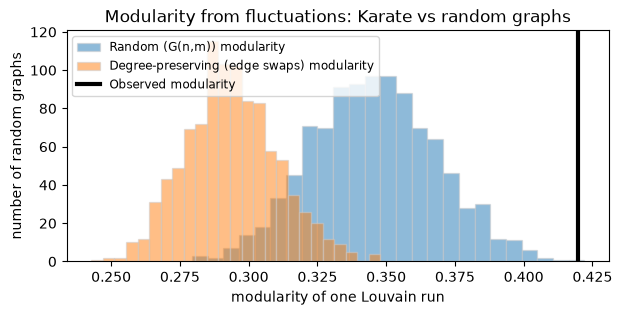

In [10]:
plt.figure(figsize=(7,3),dpi=100)

plt.hist(qs_r, bins=25, ec='.8', label='Random (G(n,m)) modularity', alpha=0.5)
plt.hist(qs_c, bins=25, ec='.8', label='Degree-preserving (edge swaps) modularity', alpha=0.5)
plt.axvline(q_obs, linewidth=3, color='k', label='Observed modularity')

plt.xlabel("modularity of one Louvain run")
plt.ylabel("number of random graphs")
plt.title("Modularity from fluctuations: Karate vs random graphs")
plt.legend(fontsize='small', loc=2)

plt.show()

Read the plot this way. Every one of these random graphs was built with no communities in it. Louvain still finds partitions with $Q$ around 0.35 in the $G(n,m)$ graphs, nearly all of them above the old rule of thumb $Q \approx 0.3$ from Class 7, and around 0.29 in the degree-preserving graphs. The Karate Club (black line, $Q = 0.42$) sits above both piles, so its modularity is more than chance alone gives. But look at how high the piles reach: a modularity of 0.3 or 0.35 does not, on its own, show that a network has communities. You have to ask what random graphs give.

If you built your degree-preserving graphs with `nx.configuration_model`, your second histogram sits higher, around 0.38, and about 1 in 11 of your random graphs match or beat Karate. That function returns a multigraph: here about 3 self-loops and 9 repeated edges out of 78 per draw. Louvain counts a self-loop as an edge inside a community, which pushes $Q$ up. The solution above keeps the graphs simple by swapping the ends of pairs of edges, the degree-preserving randomization from Class 4.

#### 2.5 In case you're interested... we can compute modularity from scratch like in Class 7.

We'll take the Louvain partition on Karate and compute:

$$
Q(\mathbf{b}) = \frac{1}{2m}\sum_{i,j}
\left(A_{ij} - \frac{k_i k_j}{2m}\right)\,\mathbf{1}\{b_i=b_j\}
$$

in plain NumPy, then verify it matches `networkx.algorithms.community.quality.modularity()`.

In [11]:
# Pull the Louvain partition explicitly
# weight=None again: count every edge once, as in the formula above
parts = louvain_communities(G_obs, weight=None, seed=0)
q_nx = modularity(G_obs, parts, weight=None)

nodes = list(G_obs.nodes())
idx = {node: i for i, node in enumerate(nodes)}

A = nx.to_numpy_array(G_obs, nodelist=nodes, weight=None)
k = A.sum(axis=1)
m = k.sum() / 2.0

# community labels aligned to our matrix ordering
g = np.empty(len(nodes), dtype=int)
for ci, group in enumerate(parts):
    for node in group:
        g[idx[node]] = ci

B = A - np.outer(k, k) / (2 * m)           # modularity matrix
S = (g[:, None] == g[None, :]).astype(float)  # same-block indicator
q_manual = (1 / (2 * m)) * np.sum(B * S)

print("NetworkX modularity:", q_nx)
print("Manual modularity  :", q_manual)
print("Match?             :", np.isclose(q_nx, q_manual))

NetworkX modularity: 0.41978961209730437
Manual modularity  : 0.4197896120973044
Match?             : True


______

### Recap done / check-in

1. What is the biggest *practical* difference between a `networkx` graph and a `graph-tool` graph?
2. Why does `graph-tool` use property maps for attributes instead of storing them directly on Python objects?
3. Suppose you need to compute a heavy statistic (like betweenness) on a graph with millions of edges. What parts of the stack become the bottleneck in pure-Python workflows?
4. When might `networkx` still be the right choice even if it's slower?

(Questions 2 and 3 look ahead. Come back to them after Section 4.)

_____

## 3. Graph basics in `graph-tool`

### 3.1 Creating graphs

In `graph-tool`, the central object is `gt.Graph`.

```python
g = gt.Graph(directed=False)   # undirected
g = gt.Graph(directed=True)    # directed
```

A few gotchas:
- A `Graph` is a **multigraph by default** (parallel edges allowed).
- Vertices are always indexed contiguously from `0` to `N-1`.
- Vertices and edges are "descriptors" — lightweight handles that refer into the graph.

### 3.2 Adding vertices and edges

- `v = g.add_vertex()` adds one vertex
- `g.add_edge(u, v)` adds an edge
- You can add many edges quickly via `g.add_edge_list(...)`

### 3.3 Iterating

- `for v in g.vertices(): ...`
- `for e in g.edges(): ...`
- `for u in v.out_neighbors(): ...` (directed graphs)
- `v.out_degree()` / `v.in_degree()` / `v.all_neighbors()`

### 3.4 Parallel edges and self-loops

Because graphs are multigraphs by default, the following are possible unless you remove them:
- multiple edges between the same pair of vertices
- edges from a vertex to itself

You can remove them with:
```python
gt.remove_self_loops(g)
gt.remove_parallel_edges(g)
```

---

### 3.5 Hands-on: build a directed graph and inspect it


In [12]:
g = gt.Graph(directed=True)
g.add_vertex(5);  # add 5 vertices: indices 0..4

In [13]:
# add some directed edges
g.add_edge(g.vertex(0), g.vertex(1))
g.add_edge(g.vertex(0), g.vertex(2))
g.add_edge(g.vertex(2), g.vertex(1))
g.add_edge(g.vertex(1), g.vertex(3))
g.add_edge(g.vertex(3), g.vertex(3))  # self-loop

<Edge object with source '3' and target '3' at 0x17983f520>

In [14]:
# parallel edge (same endpoints)
g.add_edge(g.vertex(0), g.vertex(1))

<Edge object with source '0' and target '1' at 0x17983f6d0>

In [15]:
print("directed?", g.is_directed())
print("V =", g.num_vertices(), "E =", g.num_edges())

directed? True
V = 5 E = 6


In [16]:
# degrees
for v in g.vertices():
    print(int(v), "out-degree =", v.out_degree(), "in-degree =", v.in_degree())

print("\nAll edges:")
for e in g.edges():
    print(int(e.source()), "->", int(e.target()))

0 out-degree = 3 in-degree = 0
1 out-degree = 1 in-degree = 3
2 out-degree = 1 in-degree = 1
3 out-degree = 1 in-degree = 2
4 out-degree = 0 in-degree = 0

All edges:
0 -> 1
0 -> 2
0 -> 1
1 -> 3
2 -> 1
3 -> 3


In [17]:
# clean up
gt.remove_self_loops(g)
gt.remove_parallel_edges(g)

print("\nAfter removing self-loops + parallel edges:")
print("E =", g.num_edges())


After removing self-loops + parallel edges:
E = 4


## 4. Property maps: how attributes work in `graph-tool`

In `networkx`, attributes live in Python dictionaries:

```python
G.nodes["alice"]["age"] = 19
G.edges["alice", "bob"]["weight"] = 0.7
```

In `graph-tool`, attributes live in **property maps**, which are:
- typed (e.g., `"int"`, `"double"`, `"string"`, `"bool"`, `"vector<double>"`)
- stored *separately* from the adjacency structure (for speed)
- accessible via:
  - `g.vp` (vertex properties)
  - `g.ep` (edge properties)
  - `g.gp` (graph properties)

### 4.1 Create property maps

```python
age   = g.new_vertex_property("int")
name  = g.new_vertex_property("string")
w     = g.new_edge_property("double")
label = g.new_graph_property("string")
```

Then assign values by indexing with a vertex/edge descriptor:
```python
age[v] = 19
w[e]   = 0.7
```

### 4.2 Store property maps inside the graph

You can keep property maps as standalone variables, **and/or** store them in the graph:

```python
g.vp["age"] = age
g.ep["weight"] = w
g.gp["dataset"] = label
```

Then you can access them as:
- `g.vp.age` (if the key is a valid Python identifier)
- `g.vp["age"]` (always works)

### 4.3 Fast numpy access (`.a` and `.fa`)

Many property maps expose numpy arrays for speed:
- `prop.a` is a numpy view of *all* the values, including any vertices/edges a filter hides (writing to it changes the property map)
- `prop.fa` is the *filtered* array: only the vertices/edges a `GraphView` keeps (a copy, when a filter is active)

You'll see this in graph-tool examples like:
```python
deg = g.degree_property_map("total").a
```

---

### 4.4 Hands-on: attach names to vertices and weights to edges


In [18]:
g = gt.Graph(directed=False)
g.add_vertex(4);

In [19]:
# make edges
edges = [(0, 1), (1, 2), (2, 3), (0, 2)]
g.add_edge_list(edges)

In [20]:
# vertex properties
name = g.new_vp("string")
for i, v in enumerate(g.vertices()):
    name[v] = ["alice", "bob", "carlos", "dana"][i]

In [21]:
# edge properties
w = g.new_ep("double")
for e in g.edges():
    w[e] = np.random.rand()

In [22]:
# store them
g.vp["name"] = name
g.ep["weight"] = w
g.gp["dataset"] = g.new_gp("string", val="toy_example")

In [23]:
print("Graph property dataset:", g.gp["dataset"])
for e in g.edges():
    print(g.vp.name[e.source()], "--", g.vp.name[e.target()], " weight =", round(g.ep.weight[e], 3))

Graph property dataset: toy_example
alice -- bob  weight = 0.222
alice -- carlos  weight = 0.871
bob -- carlos  weight = 0.207
carlos -- dana  weight = 0.919


### Check-in:

1. What is the type of `g.vp["name"]` (a **property map**) versus the type of `g.vp["name"][v]` (a **value**)?
2. `deg = g.degree_property_map("total")` gives a property map. What does `deg.a` return, and why is that convenient?
3. What happens to vertex/edge property maps when you create a `GraphView`? (Think: *view* vs *copy*.)
4. If you filter a graph and then call `gt.Graph(view, prune=True)`, what changes, and what stays the same?

(Questions 3 and 4 look ahead. Come back to them after Section 7.)

__________
## 5. Building graphs from data (edge lists, pandas, file formats)

### 5.1 Edge lists are the universal "exchange format"

Most real-world network datasets can be reduced to something like:

| source | target | weight | timestamp | ... |
|---|---|---:|---|---|
| alice | bob | 0.2 | 2024-01-01 | ... |
| bob | carlos | 1.1 | 2024-01-02 | ... |

In `graph-tool`, the most efficient way to build a graph from data is usually:

- turn your edge list into a numpy array or list of tuples
- call `g.add_edge_list(...)`

### 5.2 `add_edge_list(..., hashed=True)` for string node IDs

If your nodes are strings, you can let `graph-tool` build the mapping automatically:

```python
g = gt.Graph(directed=False)
vprop_id = g.add_edge_list(edge_array, hashed=True, hash_type="string")
g.vp["id"] = vprop_id
```

This creates:
- vertices with integer indices `0..N-1`
- a vertex property map that stores the original IDs

### 5.3 Reading and writing graphs

`graph-tool` supports multiple formats:
- `.gt` (native binary, fast)
- `.graphml` / `.xml`
- `.gml`, `.dot`

```python
g.save("mygraph.gt")
g2 = gt.load_graph("mygraph.gt")
```

---

### 5.4 Hands-on: make a graph from a pandas edge list


In [24]:
# Make a tiny "realistic" edge list as a DataFrame
df_edges = pd.DataFrame({
    "src": ["alice", "alice", "bob", "carlos", "carlos", "dana"],
    "dst": ["bob", "carlos", "carlos", "dana", "alice", "bob"],
    "weight": [1.0, 0.2, 0.8, 2.0, 0.5, 1.3],
})

df_edges

,src,dst,weight
0,alice,bob,1.0
1,alice,carlos,0.2
2,bob,carlos,0.8
3,carlos,dana,2.0
4,carlos,alice,0.5
5,dana,bob,1.3


In [25]:
# Edge list as list of tuples (src, dst, weight)
edge_list = list(df_edges.itertuples(index=False, name=None))
edge_list

[('alice', 'bob', 1.0),
 ('alice', 'carlos', 0.2),
 ('bob', 'carlos', 0.8),
 ('carlos', 'dana', 2.0),
 ('carlos', 'alice', 0.5),
 ('dana', 'bob', 1.3)]

In [26]:
g = gt.Graph(directed=False)

In [27]:
# We will store weights in an edge property map.
eweight = g.new_ep("double")

In [28]:
# add_edge_list can fill edge properties if we pass eprops=[...]
# IMPORTANT: When hashed=True, it will map string IDs -> vertex indices.
vprop_id = g.add_edge_list(edge_list, hashed=True, hash_type="string", eprops=[eweight])

In [29]:
# store properties
g.vp["id"] = vprop_id
g.ep["weight"] = eweight

In [30]:
print("V =", g.num_vertices(), "E =", g.num_edges())
print("Some vertex IDs:", [g.vp.id[v] for v in list(g.vertices())[:5]])

V = 4 E = 6
Some vertex IDs: ['alice', 'bob', 'carlos', 'dana']


Note `E = 6`. The table lists alice and carlos twice, once in each direction. In an undirected graph those are the same pair, so `graph-tool` keeps two parallel edges between them (Section 3). Call `gt.remove_parallel_edges(g)` if you want one.

In [31]:
# show first few edges with weights
for e in list(g.edges())[:5]:
    print(g.vp.id[e.source()], "-", g.vp.id[e.target()], "w =", g.ep.weight[e])

alice - bob w = 1.0
alice - carlos w = 0.2
bob - carlos w = 0.8
carlos - dana w = 2.0
carlos - alice w = 0.5


________
## 6. Converting `networkx` ↔ `graph-tool` (interoperability)

You will often:
- prototype in `networkx` (quick + flexible)
- scale or infer structure in `graph-tool` (fast + statistical inference)
- export results back to `networkx` for compatibility with other tooling

### 6.1 The core challenge: node labels

- In `networkx`, nodes can be strings, ints, tuples, etc.
- In `graph-tool`, vertices are **integer indices**.

So any conversion needs a mapping. A common pattern:
- store original node labels in a vertex property map named `"id"` or `"name"`

### 6.2 Practical conversion utilities

Below is a conversion function that:
- preserves node labels (as `vp["id"]`)
- carries over node/edge attributes when possible

> These are "teaching implementations", not industrial-strength ETL.  
> For messy real datasets, you'll want to be explicit about which columns/attributes you keep.


In [32]:
def _infer_gt_type(value):
    # Infer a graph-tool property type for common Python values.
    if isinstance(value, bool):
        return "bool"
    if isinstance(value, int) and not isinstance(value, bool):
        return "int"
    if isinstance(value, float):
        return "double"
    if isinstance(value, str):
        return "string"
    # fallback: stores arbitrary Python objects (less portable)
    return "object"

def nx_to_gt(G_nx, node_id_key="id"):
    '''
    Convert a NetworkX graph -> graph-tool Graph.

    - Keeps original node labels in vertex property `node_id_key`.
    - Copies node and edge attributes when possible.
    '''
    g = gt.Graph(directed=G_nx.is_directed())

    # --- Collect attribute keys
    node_attr_keys = set()
    edge_attr_keys = set()

    for _, data in G_nx.nodes(data=True):
        node_attr_keys |= set(data.keys())
    for _, _, data in G_nx.edges(data=True):
        edge_attr_keys |= set(data.keys())

    # Create vertex property maps
    vp = {}
    vp[node_id_key] = g.new_vp("string")  # always keep labels as strings
    for k in sorted(node_attr_keys):
        sample = None
        for _, data in G_nx.nodes(data=True):
            if k in data:
                sample = data[k]
                break
        vp[k] = g.new_vp(_infer_gt_type(sample) if sample is not None else "string")

    # Create edge property maps
    ep = {}
    for k in sorted(edge_attr_keys):
        sample = None
        for _, _, data in G_nx.edges(data=True):
            if k in data:
                sample = data[k]
                break
        ep[k] = g.new_ep(_infer_gt_type(sample) if sample is not None else "string")

    # --- Add vertices and mapping
    nxnode_to_v = {}
    for n, data in G_nx.nodes(data=True):
        v = g.add_vertex()
        nxnode_to_v[n] = v

        vp[node_id_key][v] = str(n)

        for k, pmap in vp.items():
            if k == node_id_key:
                continue
            if k in data:
                try:
                    pmap[v] = data[k]
                except Exception:
                    pmap[v] = str(data[k])

    # --- Add edges
    for u, v, data in G_nx.edges(data=True):
        e = g.add_edge(nxnode_to_v[u], nxnode_to_v[v])
        for k, pmap in ep.items():
            if k in data:
                try:
                    pmap[e] = data[k]
                except Exception:
                    pmap[e] = str(data[k])

    # Attach property maps
    for k, pmap in vp.items():
        g.vp[k] = pmap
    for k, pmap in ep.items():
        g.ep[k] = pmap

    return g

def gt_to_nx(g, node_id_key="id"):
    '''
    Convert graph-tool Graph -> NetworkX graph.

    If g.vp[node_id_key] exists, uses it as NetworkX node labels.
    Otherwise uses integer vertex indices.
    '''
    G_nx = nx.DiGraph() if g.is_directed() else nx.Graph()

    use_id = (node_id_key in g.vp)
    v_to_label = {}

    for v in g.vertices():
        lbl = g.vp[node_id_key][v] if use_id else int(v)
        v_to_label[v] = lbl
        G_nx.add_node(lbl)

        # copy vertex properties (excluding id)
        for k, pmap in g.vp.items():
            if k == node_id_key:
                continue
            try:
                G_nx.nodes[lbl][k] = pmap[v]
            except Exception:
                G_nx.nodes[lbl][k] = str(pmap[v])

    # edges + properties
    for e in g.edges():
        u = v_to_label[e.source()]
        v = v_to_label[e.target()]
        G_nx.add_edge(u, v)

        for k, pmap in g.ep.items():
            try:
                G_nx.edges[u, v][k] = pmap[e]
            except Exception:
                G_nx.edges[u, v][k] = str(pmap[e])

    return G_nx


### 6.3 Demo: convert the Karate Club graph

1. load the classic Zachary Karate Club network in NetworkX
2. convert to `graph-tool`
3. compute a layout and draw it (graph-tool)
4. convert back to NetworkX (so you can keep using your old workflows)


In [33]:
G_k = nx.karate_club_graph()
print("NetworkX karate:", G_k.number_of_nodes(), "nodes,", G_k.number_of_edges(), "edges")

g_k = nx_to_gt(G_k, node_id_key="id")
print("graph-tool karate:", g_k.num_vertices(), "vertices,", g_k.num_edges(), "edges")

NetworkX karate: 34 nodes, 78 edges
graph-tool karate: 34 vertices, 78 edges


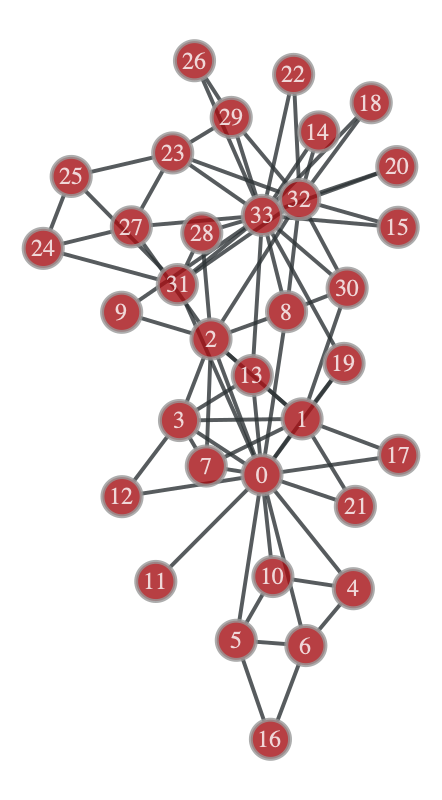

In [34]:
pos = gt.sfdp_layout(g_k)
gt.graph_draw(
    g_k, pos=pos,
    vertex_text=g_k.vp.id,
    vertex_font_size=12,
    output_size=(400, 400)
);

In [35]:
# convert back
G_back = gt_to_nx(g_k, node_id_key="id")
print("Back to NetworkX:", G_back.number_of_nodes(), "nodes,", G_back.number_of_edges(), "edges")

Back to NetworkX: 34 nodes, 78 edges


## 7. Graph views & filtering (largest component, masks, subgraphs)

One of the most powerful ideas in `graph-tool` is the **GraphView**:

- You can create a *view* of a subset of vertices/edges
- Most algorithms operate on the view transparently
- This avoids expensive copying

### 7.1 The two-step pattern

1) Create a boolean filter (a property map of type `"bool"`):
```python
vfilt = g.new_vp("bool")
vfilt[v] = True  # keep
vfilt[v] = False # hide
```

2) Create a view:
```python
gv = gt.GraphView(g, vfilt=vfilt)
```

If you later need an independent graph (no filters), you can copy/prune:
```python
g2 = gt.Graph(gv, prune=True)
```

### 7.2 Largest connected component

Community detection and inference are usually best done on the **giant component**.

Two common patterns:
- `gt.extract_largest_component(g, directed=False)` (quick)
- `GraphView + label_largest_component()` (more control)

---

### 7.3 Hands-on: filter to the largest component and to "high-degree" vertices


In [36]:
# Let's use a built-in dataset (Karate Club)
g = nx_to_gt(nx.karate_club_graph())

In [37]:
print("Original: V =", g.num_vertices(), "E =", g.num_edges())

Original: V = 34 E = 78


In [38]:
# Largest component (Karate is connected, but this is the pattern)
g_lcc = gt.extract_largest_component(g, directed=False)
print("Largest component: V =", g_lcc.num_vertices(), "E =", g_lcc.num_edges())

Largest component: V = 34 E = 78


In [39]:
# Filter: keep only vertices with degree >= 4
deg = g_lcc.degree_property_map("total")
vfilt = g_lcc.new_vp("bool")
vfilt.a = deg.a >= 4  # vectorized assignment

In [40]:
gv = gt.GraphView(g_lcc, vfilt=vfilt)
g_deg4 = gt.Graph(gv, prune=True)

print("Degree>=4 view (pruned): V =", g_deg4.num_vertices(), "E =", g_deg4.num_edges())

Degree>=4 view (pruned): V = 16 E = 39


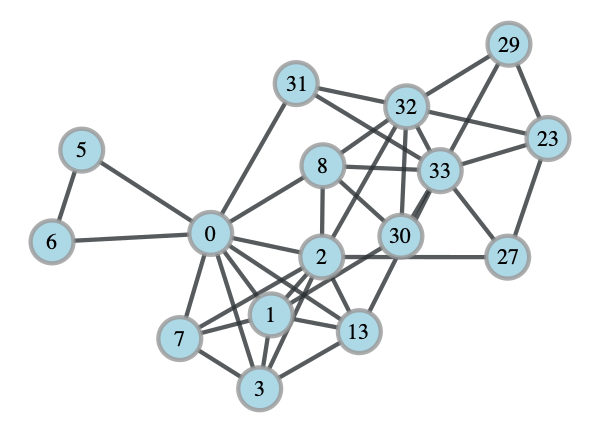

In [41]:
pos = gt.sfdp_layout(g_deg4)
gt.graph_draw(
    g_deg4, pos=pos,
    vertex_text=g_deg4.vp.id,
    vertex_font_size=11,
    output_size=(300, 300),
    vertex_fill_color='lightblue'
);

## 8. Visualization: layouts, styling, exporting

`graph-tool` can draw graphs *directly* (via Cairo), and its layout algorithms are excellent.

### 8.1 Layouts (where do nodes go?)

A layout is usually a **vertex property map** with a 2D position per node:
- type often looks like `"vector<double>"` under the hood

A common default:
```python
pos = gt.sfdp_layout(g)
```

### 8.2 Styling (colors, sizes, labels)

Most style parameters can be:
- a constant (e.g., `vertex_size=10`)
- **or** a property map (e.g., size that grows with degree)

Example:
```python
deg = g.degree_property_map("total")
vsize = gt.prop_to_size(deg, mi=5, ma=20)
gt.graph_draw(g, pos=pos, vertex_size=vsize)
```

`prop_to_size` rescales the values so the smallest becomes `mi` and the largest becomes `ma` and, by default, takes a square root on the way (`power=0.5`); pass `power=1` for a linear map.

### 8.3 Exporting

You can render directly to a file:
```python
gt.graph_draw(g, pos=pos, output="figure.svg")
```

---

### 8.4 Hands-on: draw the Karate Club graph with degree-based sizing


In [42]:
g = nx_to_gt(nx.karate_club_graph())

# layout
pos = gt.sfdp_layout(g)

In [43]:
# degree -> size
deg = g.degree_property_map("total")
vsize = gt.prop_to_size(deg, mi=10, ma=30)

In [44]:
# color by degree (continuous)
vcolor = gt.prop_to_size(deg, mi=0.1, ma=0.9)  # values mapped to [0.1,0.9] for colormap usage

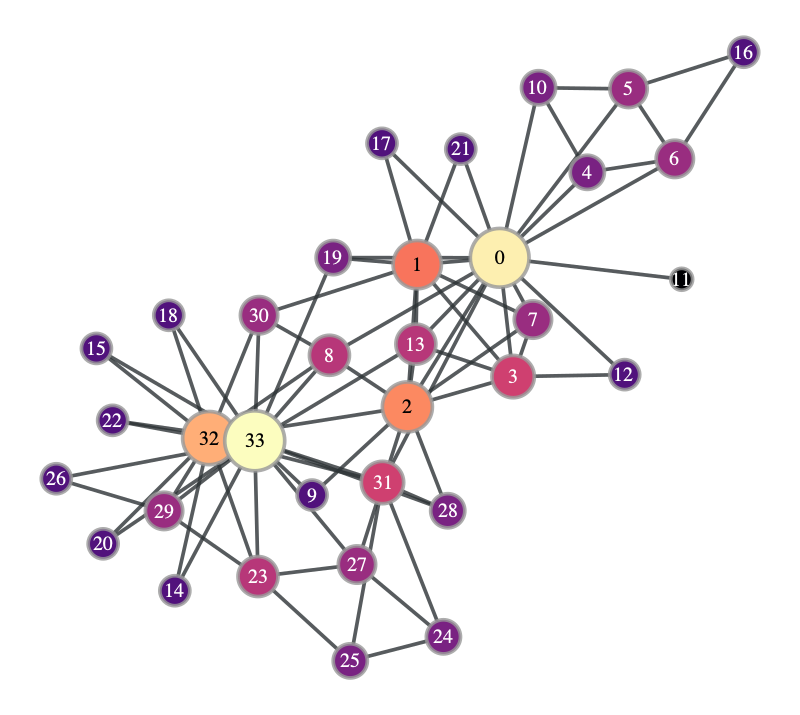

In [45]:
gt.graph_draw(
    g, pos=pos,
    vertex_size=vsize,
    vertex_fill_color=vcolor,
    vertex_text=g.vp.id if "id" in g.vp else g.vertex_index,
    vertex_font_size=10,
    output_size=(400, 400)
);

## Your turn! (15 minutes)
Explore the graph-tool cookbook, and try pasting in an interesting routine / module / analysis.

https://graph-tool.skewed.de/static/docs/stable/demos/index.html

## 9. Core descriptive stats: degrees, clustering, distances

Before we infer communities, we should be comfortable with basic network summaries.

We'll use the Karate Club network as a running example.

> Why this matters: when you later fit an SBM, you should *always* sanity-check the result against basic summaries (degree distribution, clustering, path lengths, assortativity, etc.).
> 
> Otherwise, you can end up "discovering" communities that are really just artifacts of degree heterogeneity, disconnected components, or measurement issues.

---


### 9.1 Degree (distribution and averages)

For an undirected simple graph with adjacency matrix $A$:

$$k_i = \sum_j A_{ij}.$$

For a directed graph:

$$k_i^{\text{out}} = \sum_j A_{ij},\qquad k_i^{\text{in}} = \sum_j A_{ji}.$$


**NetworkX**
- `dict(G.degree())`
- `np.mean([d for _, d in G.degree()])`

**graph-tool**
- `deg = g.degree_property_map("total").a`
- `gt.vertex_average(g, "total")`
- `gt.vertex_hist(g, "total")`

---

### 9.2 Clustering coefficient (triangles)

A triangle is a 3-cycle: $i\to j\to k\to i$.

A common definition of the **local clustering coefficient** is:

$$C_i = \frac{\text{number of triangles touching } i}{\text{number of triples centered at } i}
= \frac{2T_i}{k_i(k_i-1)},$$

where $T_i$ is the number of triangles incident to $i$, and $k_i$ is the degree.

A common **global** clustering / transitivity is:

$$C = \frac{3\times\text{\# triangles}}{\text{\# connected triples}}.$$

A *triple centered at $i$* is a pair of neighbors of $i$; there are $k_i(k_i-1)/2$ of them, and $T_i$ counts the pairs that are themselves connected. The formula needs $k_i\ge 2$. For $k_i=0$ or $1$ it is $0/0$, and both `networkx` and `graph-tool` report $C_i=0$ (Karate node 11 has degree 1). A *connected triple* is a path of length two, $j - i - l$; each triangle contains three of them, hence the factor 3. For the Karate Club, $3\times 45/528 = 0.2557$.


**NetworkX**
- `nx.clustering(G)` (local)
- `nx.average_clustering(G)` (global average of local $C_i$)
- `nx.transitivity(G)` (global transitivity)

**graph-tool**
- `gt.local_clustering(g)` (local)
- `gt.local_clustering(g).a.mean()` (global average of local $C_i$)
- `gt.global_clustering(g)` (global transitivity)

---


In [46]:
# The same graph in both libraries (nx_to_gt is from Section 6)
G = nx.karate_club_graph()
g = nx_to_gt(G)

c_nx = np.array(list(nx.clustering(G).values()))   # dict: node -> C_i
c_gt = gt.local_clustering(g).a                    # property map -> numpy array
print("Local clustering agrees for every node?", np.allclose(c_nx, c_gt))
print("Average of the local C_i:", round(nx.average_clustering(G), 4), "(networkx) ", round(float(c_gt.mean()), 4), "(graph-tool)")
print("Transitivity            :", round(nx.transitivity(G), 4), "(networkx) ", round(gt.global_clustering(g)[0], 4), "(graph-tool)")

Local clustering agrees for every node? True
Average of the local C_i: 0.5706 (networkx)  0.5706 (graph-tool)
Transitivity            : 0.2557 (networkx)  0.2557 (graph-tool)


Two things to notice. First, `gt.global_clustering` returns two numbers: the coefficient, and a measure of how uncertain it is (how much the value moves when you leave out one node at a time). The `[0]` takes the first. Second, the two "global" numbers differ a lot, 0.57 against 0.26, because they average differently. The first gives every node one vote. The second gives every connected triple one vote, so the hubs, which sit at the centre of most triples and have low clustering, dominate.

### 9.3 Shortest-path distance

The shortest path distance between $i$ and $j$ is:

$$d(i,j) = \min_{\pi:i\to j} |\pi|,$$

i.e., the minimum number of edges along any path $\pi$ from $i$ to $j$.


**NetworkX**
- `nx.shortest_path_length(G, source, target)`

**graph-tool**
- `gt.shortest_distance(g, source=v)` returns distances to all vertices
- `gt.shortest_distance(g, source=v, target=u)` returns one distance

---

In [47]:
d_nx = nx.shortest_path_length(G, source=0)            # dict: node -> distance from node 0
d_gt = gt.shortest_distance(g, source=g.vertex(0)).a   # numpy array, one entry per vertex
print("Distances from node 0 agree for every node?", np.array_equal([d_nx[v] for v in G.nodes()], d_gt))
print("Distance from node 0 to node 33:", nx.shortest_path_length(G, 0, 33), "(networkx) ",
      gt.shortest_distance(g, source=g.vertex(0), target=g.vertex(33)), "(graph-tool)")

Distances from node 0 agree for every node? True
Distance from node 0 to node 33: 2 (networkx)  2 (graph-tool)


### 9.4 Betweenness centrality

Betweenness of a vertex $v$ measures how often it lies on shortest paths:

$$\mathrm{BC}(v) = \sum_{s\neq v\neq t}\frac{\sigma_{st}(v)}{\sigma_{st}},$$

where:
- $\sigma_{st}$ is the number of shortest paths from $s$ to $t$
- $\sigma_{st}(v)$ is the number of those paths that pass through $v$

The sum runs over pairs of nodes $s,t$ that are both different from $v$. Both libraries then divide by the number of such pairs, so the reported value lies between 0 and 1. For an undirected graph with $N$ nodes, each unordered pair is counted once and the divisor is $(N-1)(N-2)/2$. For node 0 of the Karate Club, $231.07/528 = 0.4376$. That is what "normalized" means in the code below. (That 528 is a coincidence: it is also the number of connected triples in Section 9.2.)


**NetworkX**
- `nx.betweenness_centrality(G)` (can be slow for large graphs)

**graph-tool**
- `vb, eb = gt.betweenness(g)` (optimized; can use OpenMP)

---

In [48]:
b_nx = nx.betweenness_centrality(G)   # dict: node -> betweenness (normalized by default)
b_gt, _ = gt.betweenness(g)           # vertex and edge betweenness (also normalized by default)
print("Betweenness agrees for every node?", np.allclose([b_nx[v] for v in G.nodes()], b_gt.a))
print("Node 0:", round(b_nx[0], 4), "(networkx) ", round(float(b_gt.a[0]), 4), "(graph-tool)")

Betweenness agrees for every node? True
Node 0: 0.4376 (networkx)  0.4376 (graph-tool)


<!-- #### 9.0 (Optional) A tiny "by hand" check of the formulas

Before we use library functions, it can be helpful to sanity-check the definitions on a toy graph.

We'll build a 4-node graph consisting of:
- a triangle on nodes $\{0,1,2\}$
- plus a "tail" edge $(2,3)$

Then we'll compute:
- degrees from $k_i = \sum_j A_{ij}$
- triangles via $(A^3)_{ii}$
- local clustering via $C_i = 2T_i / (k_i(k_i-1))$

> This is **not** the fastest way to do things — it's a pedagogical check that the code matches the math. -->

<!-- ##### 9.0.1 Why does $A^3$ "know about" triangles?

This is one of the most useful linear-algebra facts in network science.

Start with an adjacency matrix $A$ for an **undirected simple** graph.

**Claim 1:** $(A^2)_{ij}$ counts the number of length-2 walks from $i$ to $j$.

Proof sketch:

$$
(A^2)_{ij} = \sum_k A_{ik}A_{kj}.
$$

A term $A_{ik}A_{kj}$ equals 1 exactly when:

- $i$ is connected to $k$
- and $k$ is connected to $j$

So each intermediate node $k$ that forms a 2-step path $i\to k\to j$ contributes 1.

**Claim 2:** $(A^3)_{ii}$ counts the number of length-3 closed walks that start and end at $i$.

$$
(A^3)_{ii} = \sum_{j,k} A_{ij}A_{jk}A_{ki}.
$$

Now look at a triangle $(i,j,k)$.

In an undirected triangle, you can traverse the triangle and return to $i$ in **two** distinct 3-step directions:

- $i\to j\to k\to i$
- $i\to k\to j\to i$

So **each triangle incident to $i$ contributes 2** to $(A^3)_{ii}$.

Therefore:

$$
T_i = \frac{(A^3)_{ii}}{2}
$$

where $T_i$ is the number of triangles that touch vertex $i$.

Finally, if you sum over all vertices:

- each triangle has 3 vertices
- at each vertex, it contributes 2 closed walks

So the total triangle count is:

$$
\#\text{triangles} = \frac{\mathrm{tr}(A^3)}{6}.
$$ -->


The next four cells repeat the summaries from Sections 9.1 to 9.4 side by side in both libraries, and draw betweenness as node size.

In [49]:
G = nx.karate_club_graph()

# NetworkX degrees
deg_nx = np.array([d for _, d in G.degree()])
print("NetworkX mean degree:", deg_nx.mean())

g = nx_to_gt(G)

deg_gt = g.degree_property_map("total").a
print("graph-tool mean degree:", deg_gt.mean())

NetworkX mean degree: 4.588235294117647
graph-tool mean degree: 4.588235294117647


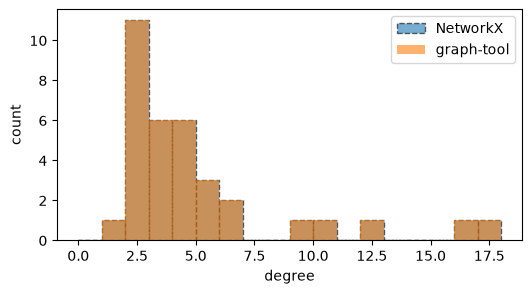

In [50]:
# Compare full distributions
plt.figure(figsize=(6,3),dpi=100)

plt.hist(deg_nx, bins=range(deg_nx.max()+2), alpha=0.6, label="NetworkX", ls='--', ec='k')
plt.hist(deg_gt, bins=range(int(deg_gt.max())+2), alpha=0.6, label="graph-tool")
plt.xlabel("degree")
plt.ylabel("count")
plt.legend()

plt.show()

In [51]:
g = nx_to_gt(nx.karate_club_graph())

# Clustering
c_local = gt.local_clustering(g)       # vertex property map
c_global = gt.global_clustering(g)     # (value, std) by default

print("graph-tool global clustering (estimate):", c_global)

# Distances from a source vertex
source = g.vertex(0)
dist = gt.shortest_distance(g, source=source)  # vertex property map of distances
print("Distances from vertex 0 (first 10):", dist.a[:10])

graph-tool global clustering (estimate): (0.2556818181818182, 0.06314746595079679)
Distances from vertex 0 (first 10): [0 1 1 1 1 1 1 1 1 2]


Top 5 betweenness vertices: [ 0 33 32  2 31]


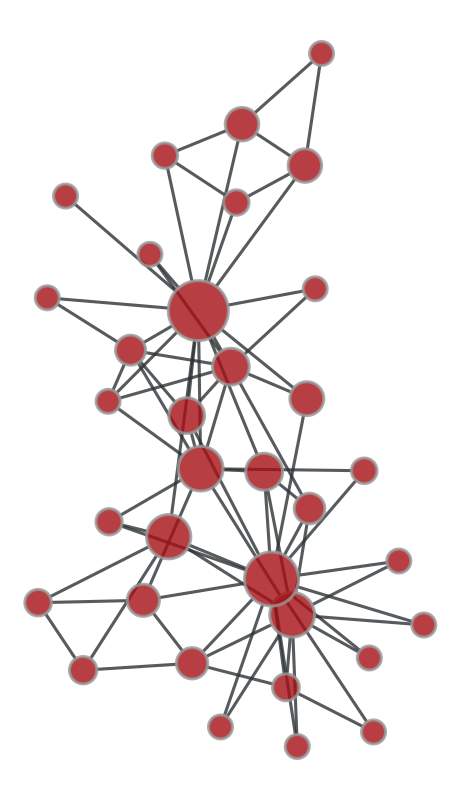

In [52]:
# Betweenness
vb, eb = gt.betweenness(g)
print("Top 5 betweenness vertices:", np.argsort(vb.a)[-5:][::-1])

# Visualize betweenness as node size
pos = gt.sfdp_layout(g)
vsize = gt.prop_to_size(vb, mi=12, ma=30)
gt.graph_draw(g, pos=pos, vertex_size=vsize, output_size=(400,400));

## 10. Null models & simulation: Erdős-Rényi vs configuration models in `graph-tool`

A **null model** answers:

> *"What patterns would we expect even if nothing interesting is happening?"*

This is absolutely central to statistical thinking:
- we observe a statistic $T(G)$ on the real graph $G$
- we compare it to the distribution of $T(\tilde G)$ for graphs $\tilde G$ generated from a null model

---


### 10.1 Erdős-Rényi $G(N,p)$ / $G(N,E)$

Two common ER variants:

1) **$G(N,p)$**: each possible edge is present independently with probability $p$.  
2) **$G(N,E)$**: choose exactly $E$ edges uniformly at random from all $\binom{N}{2}$ possibilities.

Here $E$ is the number of edges (called $M$ in Section 0.1). $\binom{N}{2} = N(N-1)/2$ is the number of pairs of nodes, read "N choose 2". "Uniformly at random" means every possible set of $E$ pairs is equally likely.

For an undirected $G(N,p)$, node $i$ has $N-1$ possible neighbors, and each one is linked to it with probability $p$. So its expected (average) degree is $p(N-1)$. A count of successes in $N-1$ independent yes/no tries, each with probability $p$, follows the binomial distribution; read $\sim$ as "is distributed as":

$$\mathbb{E}[k_i] = p(N-1),
\qquad
k_i \sim \mathrm{Binomial}(N-1, p).$$

To match an observed graph with $N$ nodes and $E$ edges, set $p$ to the fraction of possible edges that are present. This is the graph's density. The hat marks a value estimated from data:

$$\hat p = \frac{E}{\binom{N}{2}} = \frac{2E}{N(N-1)}.$$

In `graph-tool`, the fast way to sample something like $G(N,E)$ while keeping $N$ and $E$ fixed is rewiring:

```python
gt.random_rewire(g, model="erdos")
```

---


### 10.2 Configuration model (degree sequence preserved)

Many network statistics are heavily influenced by the degree sequence $\{k_i\}$. A stronger null model keeps degrees fixed while randomizing everything else. A configuration-model null preserves the degrees but randomizes the pairing of "stubs" (half-edges). In `graph-tool`, you can sample from a configuration-model-like ensemble via:

```python
gt.random_rewire(g, model="configuration")
```

Btw:

A quick back of the envelope derivation:

- Node $i$ has $k_i$ stubs.
- There are $2m$ stubs in total.
- Pick one stub from $i$. The probability it connects to a stub at node $j$ is roughly $k_j/(2m-1) \approx k_j/(2m)$.

Since $i$ has $k_i$ stubs, the expected number of $i\leftrightarrow j$ connections is approximately:

$$
\mathbb{E}[A_{ij}] \approx \frac{k_i k_j}{2m}.
$$

(This is the baseline term inside modularity!)

If you compare a real graph only to ER, you might mistake "heavy-tailed degrees" for "community structure". Configuration-model comparisons help you ask a sharper question:

> "Does this graph have structure beyond what degrees alone would produce?"


### 10.3 A simple hypothesis test by simulation (a Monte Carlo test)

Let $T(G)$ be a statistic (e.g., global clustering).

A **p-value** answers one question: if the null model were the true story, how often would it produce a value of $T$ at least as large as the one we observed? A small p-value (say below 0.05) means the null model rarely does, so it is a poor explanation of that statistic. A large p-value means the observed value is ordinary for that null model. We estimate it by simulation ("Monte Carlo" just means "by drawing many random samples"): generate $S$ graphs $\tilde G_1, \dots, \tilde G_S$ from the null model and count how many have $T(\tilde G_s) \ge T(G)$. The symbol $\mathbf{1}\{\cdot\}$ is 1 when the statement inside is true and 0 when it is false, so the sum below is that count.

- **Null hypothesis:** the graph was generated from a null model (ER or configuration)
- **Test statistic:** $T$
- **Monte Carlo p-value:**

$$p_{\text{val}} = \frac{1 + \sum_{s=1}^{S} \mathbf{1}\{T(\tilde G_s) \ge T(G)\}}{S+1}.$$

We add 1 in numerator and denominator for a small-sample correction (so the p-value is never exactly 0). This is a one-sided test: it asks how often the null gives a value at least as large as the observed one.

---

### 10.4 Hands-on: compare clustering after rewiring

We'll start with one rewire (quick intuition), then do a simulation-based p-value.

In [53]:
# Start from the Karate Club graph
g0 = nx_to_gt(nx.karate_club_graph())

# Copy graphs before rewiring
g_erdos = gt.Graph(g0)
g_conf  = gt.Graph(g0)

gt.random_rewire(g_erdos, model="erdos", n_iter=10, edge_sweep=True)
gt.random_rewire(g_conf,  model="configuration", n_iter=10, edge_sweep=True);

In [54]:
# Degree sanity-check: configuration rewiring preserves degrees (ER does not)
deg0 = g0.degree_property_map("total").a
degE = g_erdos.degree_property_map("total").a
degC = g_conf.degree_property_map("total").a
print("Degrees preserved under configuration rewire?", np.all(deg0 == degC))
print("Degrees preserved under ER rewire?           ", np.all(deg0 == degE))

Degrees preserved under configuration rewire? True
Degrees preserved under ER rewire?            False


In [55]:
# Compare global clustering
c0 = gt.global_clustering(g0)[0]
cE = gt.global_clustering(g_erdos)[0]
cC = gt.global_clustering(g_conf)[0]

print("Global clustering:")
print("  original        :", round(c0, 3))
print("  ER (G(N,E))     :", round(cE, 3))
print("  configuration   :", round(cC, 3))

Global clustering:
  original        : 0.256
  ER (G(N,E))     : 0.117
  configuration   : 0.205


That was one rewired graph of each kind, a single draw. The next cells repeat it 10,000 times.

In [56]:
g0 = nx_to_gt(nx.karate_club_graph())
c_obs = gt.global_clustering(g0)[0]

S = 10000
c_erdos = []
c_conf  = []

In [57]:
for _ in range(S):
    gE = gt.Graph(g0)
    gt.random_rewire(gE, model="erdos", n_iter=10, edge_sweep=True)
    c_erdos.append(gt.global_clustering(gE)[0])

    gC = gt.Graph(g0)
    gt.random_rewire(gC, model="configuration", n_iter=10, edge_sweep=True)
    c_conf.append(gt.global_clustering(gC)[0])

In [58]:
c_erdos = np.array(c_erdos)
c_conf  = np.array(c_conf)

In [59]:
def mc_pvalue(null_samples, obs):
    return (1 + np.sum(null_samples >= obs)) / (len(null_samples) + 1)

In [60]:
pE = mc_pvalue(c_erdos, c_obs)
pC = mc_pvalue(c_conf,  c_obs)

print(f"Observed global clustering: {c_obs:.4f}")
print(f"Monte Carlo p-value under ER rewiring         : {pE:.4f}")
print(f"Monte Carlo p-value under configuration model : {pC:.4f}")

Observed global clustering: 0.2557
Monte Carlo p-value under ER rewiring         : 0.0003
Monte Carlo p-value under configuration model : 0.1232


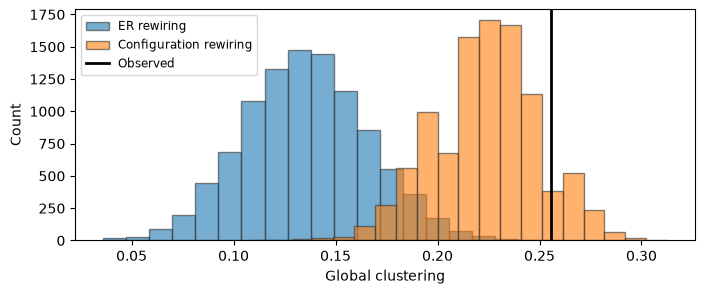

In [61]:
# Visualize the null distributions
plt.figure(figsize=(8,3), dpi=100)

plt.hist(c_erdos, bins=20, alpha=0.6, label="ER rewiring", ec='.2')
plt.hist(c_conf,  bins=20, alpha=0.6, label="Configuration rewiring", ec='.2')
plt.axvline(c_obs, linewidth=2, label="Observed", color='k')

plt.xlabel("Global clustering")
plt.ylabel("Count")
plt.legend(fontsize='small')

plt.show()

Read the two p-values like this. Out of 10,000 ER-rewired graphs, almost none had clustering as high as the real Karate Club (p about 0.0003). An ER graph does not explain Karate's clustering. But about 12% of the degree-preserving rewired graphs did (p about 0.12). So once each node keeps its degree, Karate's clustering is not unusual: most of it follows from the degrees. In the histogram, the black line sits far to the right of the ER pile and inside the right-hand side of the configuration pile.

### Check-in

1. In the Erdős-Rényi $G(n,p)$ model, what do we match when we choose $p$ from an observed graph?
2. In the configuration model (degree-preserving rewiring), what *structure* is explicitly preserved, and what is allowed to change?
3. If you compute a community score (like modularity) on an observed graph, what is the right baseline question to ask before interpreting it?
4. When you choose a null model, what is the trade-off between "too simple" and "too constrained"?


## Break!

![](images/graphtool.png)

________
## 11. Stochastic block models (SBMs): from sociology to modern inference

Before we talk about *inference*, we need a clear mental model of what an SBM is.

### 11.1 The core idea

An SBM assumes:
1. Each node belongs to a latent group (block) $b_i \in \{1,2,\dots,B\}$
2. Edge probabilities depend on groups: $P(A_{ij}=1 \mid b_i=r, b_j=s) = p_{rs}$
3. We infer the partition $\mathbf{b}$ (and sometimes $B$) from the observed graph.

That is: communities are parameters in a generative model, not just "clusters".

### 11.2 A short sociology history (why this is a social science model!)

SBMs originated in social science and statistics to model *roles* and *positions*:
- not only "assortative communities" (dense within groups),
- but also:
  - core-periphery
  - bipartite structure
  - hierarchical roles
  - disassortative mixing

### 11.3 Why nested SBMs?

Real networks often have structure at *multiple scales*:
- a few big clusters, each containing subclusters, etc.

Nested SBMs encode this with a hierarchy.

![](images/nested_sbm.png)

### 11.4 The canonical SBM likelihood (edges independent given blocks)

To fit an SBM to data we need its **likelihood**: the probability that the model, with a given partition and given block probabilities, produces exactly the graph we observed. (Section 12.2 goes through likelihood slowly. This is the SBM version.) Assume an undirected simple graph with adjacency matrix $A$ and a block assignment $b_i \in \{1,\dots,B\}$. A (canonical) SBM says:

- For each pair $i<j$ (so each pair of nodes is counted once), the edge indicator $A_{ij}$ is **Bernoulli**: a coin flip that gives 1 (edge) with some probability and 0 (no edge) otherwise
- The Bernoulli parameter depends only on the blocks $(b_i, b_j)$

$$
P(A_{ij}=1 \mid b_i=r, b_j=s) = p_{rs}.
$$

Assume the coin flips for different pairs do not affect one another once the blocks are fixed (this is what "conditionally independent" means). Probabilities of independent events multiply, so the probability of the whole graph is the product ($\prod$) over all pairs:

$$
P(A \mid \mathbf{b}, \mathbf{p})
= \prod_{i<j} p_{b_i b_j}^{A_{ij}}\,(1-p_{b_i b_j})^{1-A_{ij}}.
$$

Read one factor at a time. If $i$ and $j$ are linked, $A_{ij}=1$ and the factor is $p_{b_i b_j}$. If they are not, $A_{ij}=0$ and the factor is $1-p_{b_i b_j}$. Here $p_{b_i b_j}$ is the entry $p_{rs}$ for the blocks $r=b_i$ and $s=b_j$ that the two nodes sit in, and $\mathbf{p}$ is the whole table of them.

#### Sufficient statistics: edge counts between blocks

A **sufficient statistic** is a summary of the data that holds everything the likelihood needs. Here the summary is the table of edge counts between blocks: the likelihood does not depend on which pairs are linked, only on how many in each pair of blocks.

Define:

- $m_{rs}$ = number of observed edges between blocks $r$ and $s$
- $n_{rs}$ = number of *possible* pairs between blocks $r$ and $s$

For an undirected graph where block $r$ has $n_r$ nodes:

- if $r \neq s$: $n_{rs} = n_r n_s$
- if $r = s$: $n_{rr} = \binom{n_r}{2} = n_r(n_r-1)/2$

Now take the log of the likelihood ($\log$ means the natural log, $\ln$, here). The product becomes a sum over pairs. Group the pairs by the blocks they join. All $n_{rs}$ pairs joining blocks $r$ and $s$ share the same $p_{rs}$. Of these, $m_{rs}$ are edges, each adding $\log p_{rs}$, and the other $n_{rs}-m_{rs}$ are non-edges, each adding $\log(1-p_{rs})$. Nothing is dropped, so this is exact:

$$
\log P(A \mid \mathbf{b}, \mathbf{p})
= \sum_{r\le s} \Bigl[
m_{rs}\log p_{rs} + (n_{rs}-m_{rs})\log(1-p_{rs})
\Bigr].
$$

#### MLE of $p_{rs}$

**MLE** stands for maximum likelihood estimate: the value of $p_{rs}$ that makes the observed graph most probable. The log is an increasing function, so the largest log-likelihood and the largest likelihood occur at the same place, and the log is easier to work with. At a maximum the slope is zero, so we differentiate with respect to $p_{rs}$ and set the result to zero. Only one term of the sum contains a given $p_{rs}$; the rest drop out:

$$
\frac{\partial}{\partial p_{rs}}
\Bigl[m_{rs}\log p_{rs} + (n_{rs}-m_{rs})\log(1-p_{rs})\Bigr]
= \frac{m_{rs}}{p_{rs}} - \frac{n_{rs}-m_{rs}}{1-p_{rs}} = 0.
$$

(This uses $\frac{d}{dp}\ln p = \frac{1}{p}$ and $\frac{d}{dp}\ln(1-p) = -\frac{1}{1-p}$.) Multiply through by $p_{rs}(1-p_{rs})$: $m_{rs}(1-p_{rs}) = (n_{rs}-m_{rs})\,p_{rs}$, which simplifies to $m_{rs} = n_{rs}\,p_{rs}$. So:

$$
\hat p_{rs} = \frac{m_{rs}}{n_{rs}}.
$$

The hat marks a value estimated from data. (It needs $n_{rs} > 0$: a block with a single node has no within-block pairs.)

So: given a partition, the best-fitting block probabilities are just the edge density between the blocks.

---

### 11.5 Degree Correction

A "vanilla" SBM can accidentally use blocks to explain degree variation (i.e., hubs become their own communities). Here is why. In the plain ("vanilla") SBM, every node in a block has the same chances of linking to everyone else, so every node in a block has the same expected degree. A hub and a low-degree node cannot comfortably share a block, and the model splits them apart. A *degree-corrected SBM* adds per-vertex parameters (often written $\theta_i$) so the model can match heavy-tailed degrees without inventing extra blocks. One common formulation (for multigraphs / Poisson edges) is:

$$
A_{ij} \sim \text{Poisson}(\theta_i\theta_j\,\omega_{b_i b_j}),
$$

where $\omega_{rs}$ is a block-level connectivity parameter and $\theta_i$ is a node-specific propensity.

$\mathrm{Poisson}(\lambda)$ is a distribution over counts 0, 1, 2, ... whose average is $\lambda$. So here $A_{ij}$ is the number of edges between $i$ and $j$ (a multigraph can have more than one), and its average is $\theta_i\theta_j\,\omega_{b_i b_j}$. A node with twice the $\theta_i$ of another node in its block gets twice the expected degree. $\omega_{rs}$ plays the role that $p_{rs}$ played above.

The high-level point is simple:

- $\theta_i$ explains "how active" node $i$ is
- blocks explain "who connects to whom beyond degree effects"

`graph-tool` supports degree correction, and comparing description lengths (Section 13.4) tells you whether the extra complexity is worth it.

A **degree-corrected SBM** separates:
- community/block structure
- individual node degree propensity

In `graph-tool`, degree correction is commonly controlled with:
```python
state_args=dict(deg_corr=True)   # degree-corrected SBM
state_args=dict(deg_corr=False)  # non-degree-corrected SBM
```

---


### 11.6 Hands-on: generate a synthetic SBM with `graph-tool`

We'll generate a 3-block assortative network and visualize it.


**Important implementation detail (graph-tool vs. the SBM from Class 8):**

`gt.generate_sbm()` does *not* take a matrix of Bernoulli probabilities $p_{rs}$. Instead, its `probs[r, s]` parameter is an **edge propensity**: the *expected number of edges* between blocks $r$ and $s$ under a Poisson/multigraph SBM. If you want the familiar Bernoulli SBM probabilities $p_{rs}$, you can still use them — you just convert them to expected edge counts using the group sizes. Let $n_r$ be the number of vertices in block $r$.

- For $r \neq s$ (between blocks), the number of possible pairs is $n_r n_s$, so $\mathbb{E}[m_{rs}] = p_{rs}\,n_r n_s$. You should pass `probs[r, s] = p_rs * n_r * n_s`.

- For $r = s$ (within a block), the number of possible pairs is $\binom{n_r}{2}$, so $\mathbb{E}[m_{rr}] = p_{rr}\,\binom{n_r}{2}.$ In the `graph-tool` convention for undirected graphs, you pass **twice** that value on the diagonal: $\texttt{probs[r, r]} = 2\,\mathbb{E}[m_{rr}] = p_{rr}\,n_r(n_r-1).$ (Why twice? For undirected graphs `graph-tool` counts an edge inside a block once from each of its two ends, so the diagonal entry is twice the number of edges inside the block.)

For sparse graphs (small $p_{rs}$), the Poisson and Bernoulli formulations behave very similarly, because when the expected number of edges for a pair is tiny, a Poisson count is almost always 0 or 1, just like a coin flip. But the Poisson model does produce self-loops and repeated edges, and not only in dense graphs: with the numbers below ($n_r = 50$, $p_{rr} = 0.125$) a typical draw has about 9 self-loops and about 27 repeated edges out of roughly 500. If you need a simple graph, remove them afterwards with `gt.remove_parallel_edges(g)` and `gt.remove_self_loops(g)`. (`condensed=True` merges repeated edges and returns their multiplicities as an edge property map, but in graph-tool 3.9 it leaves the self-loops in.)

In [62]:
# Create a planted partition: 3 blocks of equal size
n_per_block = 50
b = np.repeat(np.arange(3), n_per_block)

p_in_pair  = 0.125   # per-pair within-block probability
p_out_pair = 0.005   # per-pair between-block probability

n = n_per_block

p_in  = p_in_pair  * n * (n - 1)   # = 2 * E[m_rr] for undirected
p_out = p_out_pair * n * n         # = E[m_rs] for r != s

probs = np.array([
    [p_in,  p_out, p_out],
    [p_out, p_in,  p_out],
    [p_out, p_out, p_in ],
], dtype=float)


In [63]:
g = gt.generate_sbm(b, probs, directed=False)
g.vp["block_true"] = g.new_vp("int", vals=b)

print("Generated SBM: V =", g.num_vertices(), "E =", g.num_edges())

Generated SBM: V = 150 E = 469


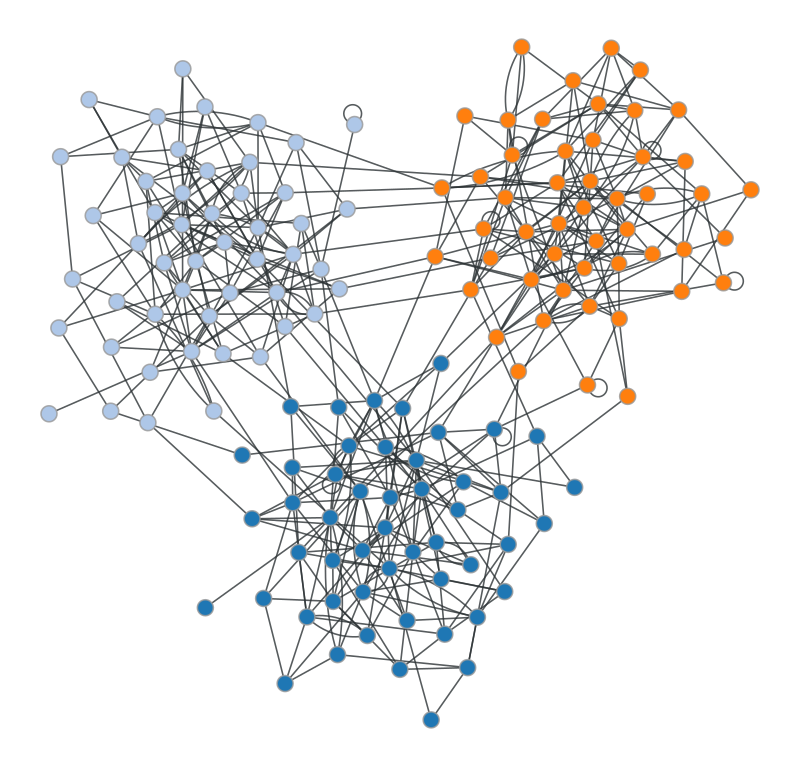

In [64]:
# (graph-tool 3.9 can crash on sfdp_layout(..., groups=...), so we lay out without the groups)
pos = gt.sfdp_layout(g)

gt.graph_draw(
    g, pos=pos,
    vertex_fill_color=g.vp.block_true,
    vertex_size=8,
    output_size=(400, 400)
);

### 11.7 Estimate $\hat p_{rs} = m_{rs}/n_{rs}$ from a generated SBM

We generated the graph from known per-pair probabilities (`p_in_pair` within blocks, `p_out_pair` between), which we converted to expected edge counts in `probs`.

Now we'll treat the graph as "observed data" and (using the true partition, which we know because we planted it) compute:

- $m_{rs}$: edge counts between blocks
- $n_{rs}$: possible pairs between blocks
- $\hat p_{rs} = m_{rs}/n_{rs}$: the canonical SBM MLE

This is a nice sanity check that the math and code agree.

The graph from `generate_sbm` contains a few self-loops and repeated edges. The code below counts every one of them in $m_{rs}$, so $\hat p_{rs}$ here is the average number of edges per pair, which is the quantity `probs` controls. If you removed self-loops and repeated edges first, the diagonal would come out near $1-e^{-0.1225}\approx 0.115$ instead of 0.125.

In [65]:
# Count edges between blocks in the generated graph
b_true = g.vp["block_true"].a
B = int(b_true.max() + 1)

In [66]:
# Block sizes
n_r = np.array([(b_true == r).sum() for r in range(B)])

In [67]:
# Possible pairs n_rs
n_rs = np.zeros((B, B), dtype=float)
for r in range(B):
    for s in range(B):
        if r == s:
            n_rs[r, s] = n_r[r] * (n_r[r] - 1) / 2
        else:
            n_rs[r, s] = n_r[r] * n_r[s]

In [68]:
# Observed edges m_rs (undirected, count each edge once)
m_rs = np.zeros((B, B), dtype=float)
for e in g.edges():
    r = int(b_true[int(e.source())])
    s = int(b_true[int(e.target())])
    m_rs[r, s] += 1
    m_rs[s, r] += 1  # symmetric fill

In [69]:
# For undirected graphs, the diagonal was double-counted above (because r==s adds twice).
for r in range(B):
    m_rs[r, r] /= 2.0

p_hat = m_rs / n_rs

In [70]:
# `probs` held expected edge counts; these are the per-pair probabilities behind them
p_true = np.full((B, B), p_out_pair)
np.fill_diagonal(p_true, p_in_pair)
print("True per-pair probabilities p_rs used to generate:")
print(np.round(p_true, 3))
print("\nEstimated p_hat = m_rs / n_rs:")
print(np.round(p_hat, 3))

True per-pair probabilities p_rs used to generate:
[[0.125 0.005 0.005]
 [0.005 0.125 0.005]
 [0.005 0.005 0.125]]

Estimated p_hat = m_rs / n_rs:
[[0.122 0.005 0.004]
 [0.005 0.113 0.003]
 [0.004 0.003 0.123]]


The estimates are close to the true values but not equal. That is expected. The graph is one random draw, so each $\hat p_{rs}$ wobbles around its true $p_{rs}$. At this size a within-block estimate is typically off by about 0.01 and a between-block estimate by about 0.001. Generate a larger graph and the estimates land closer.

### 11.8 Runtime and scaling: which community detection algorithms you can actually run

When people say "community detection," they often mean *very different* computational problems.

It helps to sort algorithms into a few big families:

1. **Edge-removal / divisive methods** (classic Girvan-Newman)
2. **Objective maximization heuristics** (modularity: greedy, Louvain, Leiden)
3. **Flow / coding methods** (Infomap / map equation)
4. **Spectral relaxations** (eigenvectors of Laplacians / modularity matrices)
5. **Generative-model inference** (SBMs: canonical/microcanonical, nested, overlapping)

These families differ in:
- what they optimize (a score? a likelihood? a code length?)
- what they assume (null models, flow models, generative models)
- and very practically: **what graph sizes they can handle**.

#### A rough scaling comparison (rule-of-thumb, sparse graphs)

Let $n$ = number of nodes and $m$ = number of edges.

| Method family | Typical goal | Scaling intuition | What it's good for | What breaks |
|---|---|---:|---|---|
| Girvan-Newman (edge betweenness removal) | "cut" bridges between groups | **very expensive** (repeated betweenness computations) | teaching + tiny networks | anything beyond a few thousand edges |
| Modularity heuristics (Louvain/Leiden) | maximize $Q$ | **fast** in practice (often near-linear in $m$ per pass) | very large graphs, quick partitions | resolution limit, degeneracy, "high $Q$ by chance," no uncertainty |
| Spectral clustering | relax discrete partition into eigenvectors | sparse eigensolvers can scale well, but still heavier than Louvain | clean blocky structure, embeddings | must choose $B$; can be brittle in noisy graphs |
| Infomap / map equation | compress random-walk flow | typically fast in practice | flow-based communities | sensitive to dynamics assumptions |
| SBM inference (`graph-tool`) | maximize posterior / minimize description length | often scales well in $m$, but with larger constant factors | principled model selection; uncertainty; "no communities" is allowed | model mismatch; heavier than pure heuristics |

#### "Explicit" big-$O$ intuition (don't take these as promises)

These are the most common back-of-the-envelope statements you'll see:

- **Girvan-Newman (edge betweenness):**  
  computing edge betweenness via Brandes is $O(nm)$ for unweighted graphs.  
  If you recompute it after each edge removal for up to $m$ removals, you get roughly $O(nm^2)$ in the worst case.

- **Greedy modularity (agglomerative, Clauset-Newman-Moore):**  
  $O(m\,d\,\log n)$, where $d$ is the depth of the merge tree (the dendrogram). For a sparse graph with a balanced tree ($m\sim n$, $d\sim\log n$) that is $O(n\log^2 n)$; with an unbalanced tree ($d\sim n$) it degrades to about $O(mn\log n)$. Newman's original 2004 version is $O((m+n)n)$.  
  In practice it's often "fine" for medium graphs and then suddenly not fine.

- **Louvain / Leiden:**  
  usually described as approximately $O(m)$ per pass for sparse graphs (with a small number of passes), which is why they're popular at scale.

- **Spectral methods:**  
  computing the top $k$ eigenvectors of a sparse matrix can be about $O(km)$ per iteration of Lanczos/Arnoldi, times the number of iterations to converge.

- **SBM inference (graph-tool):**  
  the inference moves are designed so that many operations scale roughly with the number of affected edges, and a full sweep is often described as "about $O(m)$" (again: with constant factors and convergence time that depend on the data and the move set).

Two things to internalize:

- **There is no free lunch.** A method that returns uncertainty, chooses $B$, and avoids overfitting typically does more work than a simple greedy score maximizer.
- **Implementation matters.** `graph-tool` is fast because the heavy lifting is in C++ and the inference moves are carefully engineered.

#### Micro-benchmark: how runtimes grow with graph size

Below is a classroom-scale benchmark.  
It is not a "publishable benchmark," but it will give you a feel for how runtimes respond to $n$ and $m$.

> If this runs slowly, use the shorter `sizes` list in the code below.


In [71]:
import time

# -------------------------
# Helper: generate a planted SBM in NetworkX
# (We keep average degree roughly constant as n grows.)
# -------------------------
def planted_sbm_nx(n, B=4, c_in=12, c_out=2, seed=0):
    rng = np.random.default_rng(seed)
    sizes = [n // B] * B
    for i in range(n - sum(sizes)):
        sizes[i] += 1

    # Probabilities scale like 1/n to keep expected degree O(1)
    p_in  = c_in / n
    p_out = c_out / n
    p = [[p_in if r == s else p_out for s in range(B)] for r in range(B)]

    G = nx.stochastic_block_model(sizes, p, seed=seed)
    return G

# -------------------------
# Timing wrappers
# -------------------------
def time_call(fn, *args, **kwargs):
    t0 = time.perf_counter()
    out = fn(*args, **kwargs)
    t1 = time.perf_counter()
    return (t1 - t0), out

def nx_louvain_partition(G):
    # NetworkX built-in Louvain (if available); returns list of sets
    parts = louvain_communities(G, seed=0)
    return parts

def nx_greedy_partition(G):
    # Greedy modularity (Clauset-Newman-Moore style)
    parts = list(nx.algorithms.community.greedy_modularity_communities(G))
    return parts

def nx_girvan_one_split(G):
    # Girvan-Newman is expensive; here we only compute the FIRST split.
    gen = nx.algorithms.community.girvan_newman(G)
    first = next(gen)
    return list(first)

def gt_nested_sbm(g_gt):
    state = gt.minimize_nested_blockmodel_dl(g_gt, state_args=dict(deg_corr=True))
    return state

In [72]:
# -------------------------
# Benchmark settings
# -------------------------
sizes = np.logspace(2, 4.2, 11).astype(int)   # 11 sizes, from 100 to about 16,000 nodes
# sizes = [300, 600, 1200]                    # quick version: uncomment this line if the cell is slow
results = []

for n in sizes:
    print(n)
    G = planted_sbm_nx(n, B=4, c_in=12, c_out=2, seed=0)
    m = G.number_of_edges()

    row = dict(n=n, m=m)

    t, _ = time_call(nx_louvain_partition, G)
    row["nx_louvain_sec"] = t

    # Greedy modularity (usually slower than Louvain, still OK for moderate n)
    t, _ = time_call(nx_greedy_partition, G)
    row["nx_greedy_mod_sec"] = t

    # Girvan-Newman (very expensive): only run on the smallest size
    if n == min(sizes):
        t, _ = time_call(nx_girvan_one_split, G)
        row["nx_girvan_firstsplit_sec"] = t
    else:
        row["nx_girvan_firstsplit_sec"] = np.nan
    # graph-tool nested SBM inference (convert graph first)
    g_gt = nx_to_gt(G)
    t, _ = time_call(gt_nested_sbm, g_gt)
    row["gt_nested_sbm_sec"] = t
    results.append(row)

100


165
275


457


758


1258


2089


3467


5754


9549


15848


In [73]:
df_bench = pd.DataFrame(results)
df_bench

,n,m,nx_louvain_sec,nx_greedy_mod_sec,nx_girvan_firstsplit_sec,gt_nested_sbm_sec
0,100,227,0.002537,0.005464,0.302333,0.035715
1,165,380,0.005233,0.010421,NaN,0.047761
2,275,665,0.008278,0.019888,NaN,0.118572
3,457,1071,0.021804,0.038938,NaN,0.194125
4,758,1739,0.074615,0.071314,NaN,0.389187
5,1258,2870,0.094801,0.125438,NaN,0.889920
6,2089,4675,0.159149,0.294115,NaN,2.017236
7,3467,7749,0.286202,0.552719,NaN,2.693556
8,5754,13012,0.629929,1.123040,NaN,1.867264
9,9549,21578,5.040824,2.497648,NaN,3.622316


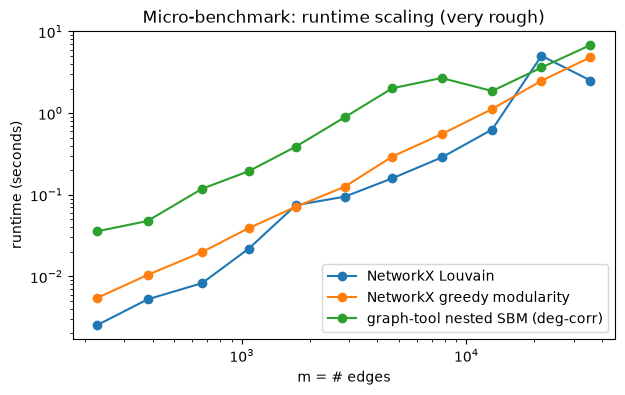

In [74]:
# Quick log-log plot (runtime vs edges)
plt.figure(figsize=(7,4),dpi=100)

plt.plot(df_bench["m"], df_bench["nx_louvain_sec"], marker="o", label="NetworkX Louvain")
plt.plot(df_bench["m"], df_bench["nx_greedy_mod_sec"], marker="o", label="NetworkX greedy modularity")
plt.plot(df_bench["m"], df_bench["gt_nested_sbm_sec"], marker="o", label="graph-tool nested SBM (deg-corr)")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("m = # edges")
plt.ylabel("runtime (seconds)")
plt.title("Micro-benchmark: runtime scaling (very rough)")
plt.legend()


plt.show()

How to read this plot. Both axes are logarithmic, so a straight line means the runtime grows like a power of $m$, and the slope is that power. A slope of 1 means doubling the edges doubles the time. Compare the slopes (how fast each method slows down as the graph grows) separately from the heights (how slow it is at a given size). In the run saved here, the nested SBM is roughly ten times slower than Louvain on the small graphs, and the gap narrows as the graphs grow. Each point is a single timing, so bumps are noise. Girvan-Newman is not plotted because we only timed it on the smallest graph, where one split took on the order of 100 times longer than a full Louvain run.

A caution about what is being timed. These graphs are sparse (mean degree about 4.5), and on them the SBM fit returns a single group while Louvain returns many more than the 4 we planted. The plot compares how long each method takes to return an answer, not whether the answer is right.

## 12. Statistical inference primer: Bayes, evidence, and MDL (with some code!)

This section is intentionally **slow and explicit**.  
If you've never taken a statistics class, that's okay — read carefully and run the code.

We'll build an intuition that transfers directly to SBMs in `graph-tool`.

---

### 12.1 A data-generating story (a.k.a. a model)

A statistical model is a **story** for how data are generated.

- Data: $D$ (for networks, typically the adjacency matrix $A$ or edge list)
- Parameters: $\theta$ (numbers we don't know)
- Model class: $M$ (assumptions + which distributions are used)

The model gives you probabilities like:

$$P(D \mid \theta, M).$$

Read $P(D \mid \theta, M)$ as: the probability of seeing the data $D$ if the parameters were $\theta$, under model $M$. Two warnings about letters. In Section 0, $M$ was the number of edges; in Sections 12 and 13, $M$ is a model. And $\theta$ here stands for all of a model's unknown numbers at once; in the degree-corrected SBM, $\theta_i$ is one particular parameter, node $i$'s propensity to form edges.

---

### 12.2 Likelihood and log-likelihood

The **likelihood function** is:

$$L(\theta) = P(D \mid \theta, M).$$

We often work with the **log-likelihood**:

$$\ell(\theta) = \log L(\theta),$$

because:
- products of probabilities become sums
- underflow is avoided
- gradients are easier

---


### 12.3 Maximum likelihood (MLE)

The MLE is:

$$\hat \theta_{\mathrm{MLE}} = \arg\max_\theta P(D \mid \theta, M)
= \arg\max_\theta \ell(\theta).$$

**Big idea:** MLE focuses on *fit* only (can overfit).

---


### 12.4 Prior beliefs (Bayesian modeling)

A Bayesian model adds a **prior**:

$$P(\theta \mid M).$$

This encodes what values of $\theta$ are plausible *before seeing data*.

---


### 12.5 Posterior (Bayes' rule)

After observing data $D$, we update our beliefs:

$$P(\theta \mid D, M) = \frac{P(D \mid \theta, M)\,P(\theta \mid M)}{P(D \mid M)}.$$

Where the denominator $P(D \mid M)$ is the **evidence**.

---


### 12.6 Evidence (marginal likelihood)

$$P(D \mid M) = \int P(D \mid \theta, M)\,P(\theta \mid M)\,d\theta.$$

Evidence is the probability your model assigns to the data *after averaging over parameter uncertainty*.

A flexible model can fit many datasets, but that means its probability mass is spread thinly → evidence can be small unless the data truly support the complexity.

Here is why. A model's evidence $P(D \mid M)$, added up over every dataset $D$ it could produce, must equal 1. A flexible model gives some probability to many different datasets, so it can only give a little to each. A rigid model bets everything on a few. If your data are among those few, the rigid model wins.

This is one formalization of "Occam's razor".

---


### 12.7 Model comparison (Bayes factors)

For two models $M_0, M_1$:

$$\mathrm{BF}_{10} = \frac{P(D \mid M_1)}{P(D \mid M_0)}.$$

If $\mathrm{BF}_{10} \gg 1$, the data support $M_1$ over $M_0$. The Bayes factor is what turns prior odds into posterior odds: $\frac{P(M_1\mid D)}{P(M_0\mid D)} = \mathrm{BF}_{10}\times\frac{P(M_1)}{P(M_0)}$. If the two models are equally likely a priori, the posterior odds equal the Bayes factor.

---


### 12.8 Bits, nats, and description length

Information-theoretic coding says:

- a probability $P$ corresponds to a code length $-\log P$

Why $-\log P$? Suppose 8 outcomes are equally likely, so each has $P = 1/8$. You can name any one of them with 3 yes/no answers, and $-\log_2(1/8) = 3$. Rarer outcomes need more answers. One yes/no answer is one bit. A nat is the same idea measured with the natural log.

If we use natural logs:

$$\text{code length (nats)} = -\ln P.$$

If we use base-2 logs:

$$\text{code length (bits)} = -\log_2 P.$$

Conversion:

$$\text{bits} = \frac{\text{nats}}{\ln 2}.$$

---


### 12.9 Minimum description length (MDL): inference as compression

MDL reframes inference as compression:

> The best model is the one that lets you describe the data in the fewest bits.

A useful mental model:

$$\Sigma(M, \theta, D) \approx -\log P(D, \theta \mid M)
= -\log P(D\mid\theta, M) - \log P(\theta\mid M).$$

$P(D, \theta \mid M)$ is the probability of the data and the parameter values together. It equals $P(D\mid\theta,M)\,P(\theta\mid M)$: first the parameters take these values, then the data come out this way. Taking $-\log$ turns the product into the sum.

If the model also has latent structure (like communities) you include that too:

$$-\log P(D, \theta, b \mid M).$$

Bayes' rule says the posterior is this same product divided by the evidence, which does not depend on $\theta$ or $b$. So whatever makes the product largest makes the posterior largest and $\Sigma$ smallest.

So:
- smaller description length ↔ higher posterior probability
- choosing $B$ (number of blocks) becomes **model selection**

In `graph-tool`, you will see this directly:

- `state.entropy()` returns a description length $\Sigma$ (in nats)
- `minimize_blockmodel_dl()` searches for partitions minimizing $\Sigma$

---

![](images/mdl_spectrum.png)

### 12.10 A toy Bayesian inference problem: coin flips

We'll now do a fully worked example with equations and code.


### 12.10.1 Note: likelihood is not a probability distribution (and the one case where the two coincide)

This note uses the coin example that Section 12.11 builds step by step. A coin lands heads with unknown probability $p$. We flip it $n$ times and see $k$ heads. $\mathrm{Beta}(1,1)$ is the flat prior on $p$: every value from 0 to 1 is equally plausible before we flip. On a first pass, read 12.11 and then come back.

One thing that often trips people up:
- A *likelihood* $L(p) = P(D \mid p)$ is a function of $p$ given fixed data $D$.
- A *probability distribution* over $p$ must integrate to 1.

These are not the same object. For coin flips, the likelihood is:

$$
L(p) = P(k \mid p) \propto p^k (1-p)^{n-k}.
$$

If you *normalize* that function over $p \in [0,1]$, you get a proper density over $p$. With a uniform prior $p \sim \mathrm{Beta}(1,1)$, the *posterior density over $p$ is proportional to the likelihood*. 

So "posterior = normalized likelihood" is literally true *in that special case*.

We can show this!

In [75]:
from scipy.stats import beta as beta_dist

# Fix some fake coin flip data:
n = 20
k = 13

In [76]:
p_grid = np.linspace(1e-4, 1-1e-4, 2000)

In [77]:
# Likelihood as a function of p (up to a constant binomial coefficient)
L = (p_grid**k) * ((1 - p_grid)**(n - k))

In [78]:
# This is NOT a probability distribution over p:
area_L = np.trapezoid(L, p_grid)
print("Integral of likelihood over p (not 1):", area_L)

Integral of likelihood over p (not 1): 6.14280800039314e-07


In [79]:
# Normalize it by hand
L_norm = L / area_L
area_L_norm = np.trapezoid(L_norm, p_grid)
print("Integral after normalization:", area_L_norm)

Integral after normalization: 0.9999999999999999


In [80]:
# Under a uniform prior Beta(1,1), posterior is Beta(k+1, n-k+1)
# (derived in 12.11, under 'Posterior (conjugacy)')
post_pdf = beta_dist.pdf(p_grid, k + 1, n - k + 1)

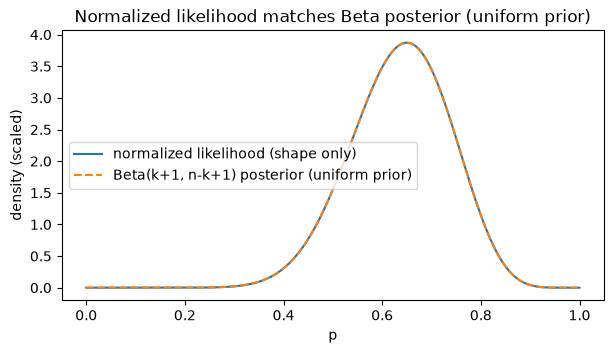

In [81]:
# Compare shapes
plt.figure(figsize=(7, 3.5),dpi=100)

plt.plot(p_grid, L_norm, label="normalized likelihood (shape only)")
plt.plot(p_grid, post_pdf, label="Beta(k+1, n-k+1) posterior (uniform prior)", ls='--')
plt.xlabel("p")
plt.ylabel("density (scaled)")
plt.title("Normalized likelihood matches Beta posterior (uniform prior)")
plt.legend()

plt.show()

In [82]:
# MLE is k/n (same calculation as the MLE of p_rs in Section 11.4)
print("MLE p_hat = k/n =", k/n)

MLE p_hat = k/n = 0.65


### 12.11 Worked example: coin flips (Bernoulli + Beta)

This example is deliberately simple, but the logic transfers to SBMs. We observe flips $x_1, \dots, x_n$ with $x_i \in \{0,1\}$.

Let:
- $k = \sum_i x_i$ be the number of heads
- $n-k$ be the number of tails

#### Model (likelihood)

$$x_i \sim \mathrm{Bernoulli}(p)$$

Each flip is heads ($x_i = 1$) with probability $p$ and tails ($x_i = 0$) with probability $1-p$. A single yes/no draw like this is called a Bernoulli trial.

The flips do not affect each other, so the probability of the whole sequence is the product of the probabilities of each flip. The factor $p^{x_i}(1-p)^{1-x_i}$ is a compact way to write: $p$ if heads, $1-p$ if tails. So the likelihood is:

$$P(x \mid p) = \prod_{i=1}^n p^{x_i}(1-p)^{1-x_i}
= p^k (1-p)^{n-k}.$$

The Binomial distribution is the distribution of the count $k$ of heads in $n$ such flips: $P(k \mid p) = \binom{n}{k}p^k(1-p)^{n-k}$, where $\binom{n}{k} = \frac{n!}{k!\,(n-k)!}$ counts the different orders in which $k$ heads can turn up. Our formula is the same without the $\binom{n}{k}$, because we recorded the order. A small but important move: take logs.

$$
\ell(p) = \log P(x\mid p)
= k\log p + (n-k)\log(1-p).
$$

This turns a product into a sum, and it also makes the geometry visible:
- $\ell(p)$ is *concave* (one hump, easier to find the max)
- the maximum occurs at $\hat p = k/n$ (set the derivative $k/p - (n-k)/(1-p)$ to zero, exactly as for $\hat p_{rs}$ in Section 11.4)

#### Prior: why a Beta prior?

Use a Beta prior:

$$p \sim \mathrm{Beta}(\alpha, \beta),
\qquad
P(p) = \frac{1}{B(\alpha,\beta)}\,p^{\alpha-1}(1-p)^{\beta-1}.$$

Here $B(\alpha,\beta)$ is not the number of blocks. It is the Beta function, a number that depends on $\alpha$ and $\beta$ and makes the total area under $P(p)$ equal 1. Its formula is in Section 12.12; you do not need it yet. $\alpha$ and $\beta$ are two positive numbers you choose; they set the shape of the prior.

Why this prior shows up constantly:

1. Right support. $p$ lives on $[0,1]$, and Beta lives on $[0,1]$.
2. Conjugacy. The Bernoulli/Binomial likelihood has the form $p^k(1-p)^{n-k}$, and the Beta prior has the form $p^{\alpha-1}(1-p)^{\beta-1}$.  
   When you multiply them, you just add exponents → the posterior is Beta again.
3. Pseudo-count interpretation. The posterior mean is $(\alpha+k)/(\alpha+\beta+n)$: exactly what $k/n$ would give if you had already seen $\alpha$ extra heads and $\beta$ extra tails. So $\alpha$ acts like a number of prior heads, $\beta$ like a number of prior tails, and $\alpha+\beta$ is the prior's "equivalent sample size". (If you summarize with the posterior mode instead, the counts shift by one: $\alpha-1$ prior heads and $\beta-1$ prior tails. That is why the uniform prior $\mathrm{Beta}(1,1)$ gives MAP = MLE.)
4. Convenient evidence. The Beta prior makes the evidence integral doable in closed form (Beta-Binomial). You want this when doing model selection.

Two common "default" choices:
- **Uniform** prior: $\mathrm{Beta}(1,1)$ (flat on $[0,1]$)
- **Jeffreys** prior: $\mathrm{Beta}(1/2, 1/2)$ (often used as a reparameterization-invariant default)

#### Posterior (conjugacy)

Multiply likelihood × prior:

$$P(p\mid x) \propto p^{k+\alpha-1}(1-p)^{(n-k)+\beta-1}$$

So:

$$p \mid x \sim \mathrm{Beta}(\alpha + k,\; \beta + n - k).$$

We dropped everything that does not depend on $p$: the evidence $P(x)$ in the denominator of Bayes' rule and the constant $1/B(\alpha,\beta)$. What is left has exactly the shape of a Beta density, $p^{a-1}(1-p)^{b-1}$, with $a = \alpha + k$ and $b = \beta + n - k$. A density must have area 1, so the dropped constants have to combine to $1/B(a,b)$. We never need to compute them.

#### Other posterior summaries

Posterior mean:

$$\mathbb{E}[p\mid x] = \frac{\alpha+k}{\alpha+\beta+n}.$$

Posterior mode (MAP), when $\alpha+k>1$ and $\beta+n-k>1$:

$$p_{\mathrm{MAP}} = \frac{\alpha+k-1}{\alpha+\beta+n-2}.$$

Posterior predictive for a new flip:

$$P(x_{\mathrm{new}}=1 \mid x) = \mathbb{E}[p\mid x].$$

Next we compute all of these in code, and then we'll play with different priors to see what changes.

In [83]:
# Simulate coin flips (synthetic data)
rng = np.random.default_rng(3)

n = 40
p_true = 0.65
x = rng.binomial(1, p_true, size=n)

k = int(x.sum())
print(f"{k} heads out of {n} flips (true p={p_true})")

27 heads out of 40 flips (true p=0.65)


In [84]:
# ---------------------------
# 1) Frequentist MLE
# ---------------------------
p_mle = k / n
print("MLE p_hat = k/n =", round(p_mle, 3))

MLE p_hat = k/n = 0.675


In [85]:
# ---------------------------
# 2) Bayesian prior + posterior
# ---------------------------
alpha, beta = 1, 1  # Beta(1,1) = uniform prior on [0,1]
alpha_post = alpha + k
beta_post  = beta + (n - k)

# Posterior mean
p_mean = alpha_post / (alpha_post + beta_post)

# Posterior MAP (mode), defined only if alpha_post>1 and beta_post>1
if alpha_post > 1 and beta_post > 1:
    p_map = (alpha_post - 1) / (alpha_post + beta_post - 2)
else:
    p_map = np.nan

# Posterior variance
p_var = (alpha_post * beta_post) / (((alpha_post + beta_post) ** 2) * (alpha_post + beta_post + 1))

print("Posterior mean E[p|x] =", round(p_mean, 3))
print("Posterior MAP  p_MAP  =", round(p_map, 3))
print("Posterior sd          =", round(np.sqrt(p_var), 3))

Posterior mean E[p|x] = 0.667
Posterior MAP  p_MAP  = 0.675
Posterior sd          = 0.072


In [86]:
# ---------------------------
# 3) Posterior credible interval
# ---------------------------
# A 95% credible interval is a range that contains p with posterior probability 0.95. We get it by
# drawing many values of p from the posterior and cutting off the lowest 2.5% and the highest 2.5%.
p_samps = rng.beta(alpha_post, beta_post, size=50_000)
ci = np.quantile(p_samps, [0.025, 0.975])
print("95% credible interval:", tuple(float(c) for c in np.round(ci, 3)))

95% credible interval: (0.518, 0.8)


Given these 40 flips and a flat prior, there is a 95% chance that $p$ is between 0.52 and 0.80. The true value 0.65 is inside.

In [87]:
# ---------------------------
# 4) Posterior predictive distribution
# ---------------------------
# Predict number of heads in n_future future flips by sampling p ~ posterior, then Binomial(n_future, p)
n_future = 40
p_post = rng.beta(alpha_post, beta_post, size=20_000)
k_future = rng.binomial(n_future, p_post)

print("Posterior predictive: E[#heads in next 40 flips] ≈", round(k_future.mean(), 1))

Posterior predictive: E[#heads in next 40 flips] ≈ 26.7


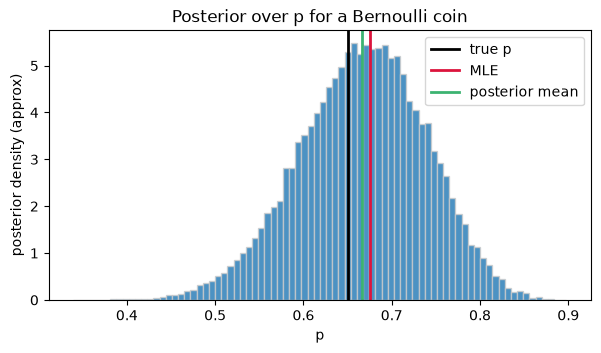

In [88]:
# ---------------------------
# Plot posterior over p
# ---------------------------
plt.figure(figsize=(7, 3.5), dpi=100)

plt.hist(p_samps, bins=80, density=True, alpha=0.8, ec='.8')
plt.axvline(p_true, linewidth=2, label="true p", color='k')
plt.axvline(p_mle,  linewidth=2, label="MLE", color='crimson')
plt.axvline(p_mean, linewidth=2, label="posterior mean", color='mediumseagreen')

plt.xlabel("p")
plt.ylabel("posterior density (approx)")
plt.title("Posterior over p for a Bernoulli coin")
plt.legend()

plt.show()

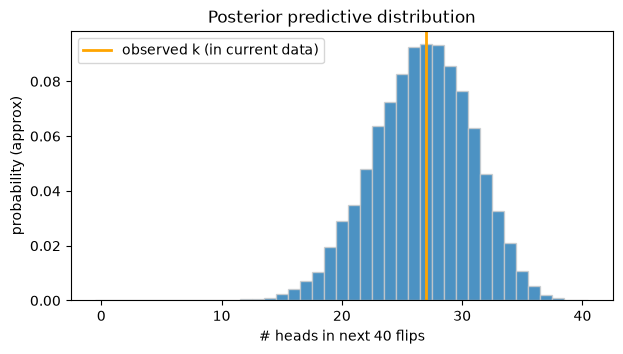

In [89]:
# Plot posterior predictive distribution over future heads
plt.figure(figsize=(7, 3.5), dpi=100)

plt.hist(k_future, bins=np.arange(n_future+2)-0.5, density=True, alpha=0.8, ec='.8')
plt.axvline(k, linewidth=2, label="observed k (in current data)", color='orange')

plt.xlabel(f"# heads in next {n_future} flips")
plt.ylabel("probability (approx)")
plt.title("Posterior predictive distribution")
plt.legend()

plt.show()

This histogram is the model's forecast for the number of heads in 40 new flips. It is wider than you would get by plugging in $p = 0.675$, because it adds our uncertainty about $p$ to the luck of the flips. The orange line marks the 27 heads we observed; it sits near the middle, as it should.

#### 12.11.1 Note: priors as pseudo-counts (and how "strong" a prior is)

In Beta-Bernoulli models, $\alpha$ and $\beta$ can be read as *pseudo-counts*:

- for the posterior **mean** $\frac{\alpha+k}{\alpha+\beta+n}$: prior heads $=\alpha$, prior tails $=\beta$, prior strength $=\alpha+\beta$ flips. Equivalently, posterior mean $= w\,\frac{\alpha}{\alpha+\beta} + (1-w)\,\frac{k}{n}$ with $w = \frac{\alpha+\beta}{\alpha+\beta+n}$.
- for the posterior **mode** $\frac{\alpha-1+k}{\alpha+\beta-2+n}$ (needs $\alpha,\beta \ge 1$): prior heads $=\alpha-1$, prior tails $=\beta-1$.

The table below reports posterior means, so read `prior_strength = a + b` as a number of prior flips.

Let's keep the same data and compare several priors.

In [90]:
from scipy.stats import beta as beta_dist

# We re-use k = 27 and n = 40 from the simulated flips in 12.11.
priors = [
    ("Uniform  Beta(1,1)", 1, 1),
    ("Jeffreys Beta(1/2,1/2)", 0.5, 0.5),
    ("Mild     Beta(2,2)", 2, 2),
    ("Strong   Beta(20,20)", 20, 20),
    ("Skewed   Beta(10,2)", 10, 2),
]

p_grid = np.linspace(1e-4, 1 - 1e-4, 2000)

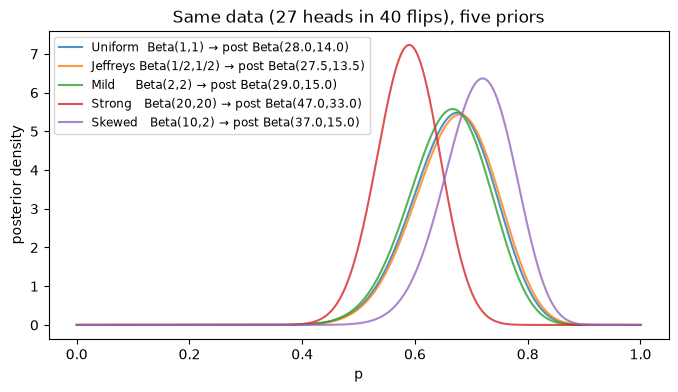

In [91]:
plt.figure(figsize=(8, 4), dpi=100)
for label, a, b in priors:
    a_post = a + k
    b_post = b + (n - k)

    pdf = beta_dist.pdf(p_grid, a_post, b_post)
    plt.plot(p_grid, pdf, label=f"{label} → post Beta({a_post:.1f},{b_post:.1f})", alpha=0.8)

plt.xlabel("p")
plt.ylabel("posterior density")
plt.title("Same data (27 heads in 40 flips), five priors")
plt.legend(fontsize='small')


plt.show()

In [92]:
# Show posterior means numerically
rows = []
for label, a, b in priors:
    a_post = a + k
    b_post = b + (n - k)
    post_mean = a_post / (a_post + b_post)
    prior_mean = a / (a + b)
    rows.append(dict(prior=label, prior_mean=prior_mean, post_mean=post_mean, prior_strength=a+b))

pd.DataFrame(rows)

,prior,prior_mean,post_mean,prior_strength
0,"Uniform Beta(1,1)",0.500000,0.666667,2.0
1,"Jeffreys Beta(1/2,1/2)",0.500000,0.670732,1.0
2,"Mild Beta(2,2)",0.500000,0.659091,4.0
3,"Strong Beta(20,20)",0.500000,0.587500,40.0
4,"Skewed Beta(10,2)",0.833333,0.711538,12.0


Read the table. The three weak priors (strength 1, 2, 4) give almost the same posterior mean, 0.66 to 0.67: 40 flips swamp them. The strong prior Beta(20,20) has strength 40, the same as the number of flips, so its posterior mean 0.5875 lands exactly halfway between the prior mean 0.5 and the MLE 0.675. To see how much the prior matters when data are scarce, rerun with only 5 flips: the curves spread apart.

### 12.12 Evidence and "Occam's razor" in a tiny model comparison

We'll compare two models:

- $M_0$: fair coin, fixed $p_0 = 0.5$ (no free parameters)
- $M_1$: unknown $p$, with prior $p \sim \mathrm{Beta}(\alpha,\beta)$

Let $k$ be the number of heads out of $n$ flips.

#### Evidence under the fair-coin model $M_0$

$M_0$ has no unknown parameter, so there is nothing to average over. Its evidence is just the probability of the data at $p_0 = 0.5$.

The probability of observing exactly $k$ heads is:

$$P(k \mid M_0) = \binom{n}{k} p_0^k (1-p_0)^{n-k}.$$

(If you treat the full sequence $x_1,\dots,x_n$ as the data, you can drop the $\binom{n}{k}$ term. A sufficient statistic is a summary of the data that carries everything the model can use. Here that is the count $k$: the order of heads and tails tells you nothing more about $p$. The $\binom{n}{k}$ appears in both models, so it cancels in the Bayes factor either way.)

#### Evidence under the unknown-$p$ model $M_1$

Start with:

$$P(k \mid p) = \binom{n}{k} p^k (1-p)^{n-k}, \qquad p \sim \mathrm{Beta}(\alpha,\beta).$$

Then integrate out $p$:

$$P(k \mid M_1) = \int_0^1 P(k \mid p)\,P(p)\,dp.$$

Because the Beta is conjugate to the Binomial, this integral has a closed form:

$$P(k \mid M_1) = \binom{n}{k}\,\frac{B(k+\alpha,\; n-k+\beta)}{B(\alpha,\beta)},$$

where the Beta function is:

$$B(a,b)=\frac{\Gamma(a)\Gamma(b)}{\Gamma(a+b)}.$$

#### Bayes factor

$$\mathrm{BF}_{10} = \frac{P(k\mid M_1)}{P(k\mid M_0)}.$$

A useful habit: compute this in log space:

$$\log \mathrm{BF}_{10} = \log P(k\mid M_1) - \log P(k\mid M_0).$$

_______
After a short detour to do the integral (12.12.1), we compute these in code and see Occam's razor at work. The Bayes factor is the best-fit likelihood ratio times a penalty for flexibility (the "Occam factor"). For 13 heads in 20 flips, $M_1$'s best fit is 2.49 times more likely than the fair coin, but the penalty is 0.26, so $\mathrm{BF}_{10} = 0.64$. $M_1$ has flexibility, but it only wins if the data *demand* that flexibility.

#### 12.12.1 (Math breakaway) Doing the evidence integral step by step

We claimed (for the unknown-$p$ model):

$$ P(k \mid M_1) = \binom{n}{k}\,\frac{B(k+\alpha,\; n-k+\beta)}{B(\alpha,\beta)}.$$

Here is the algebra that gets you there.

Start with:

- Likelihood: $P(k\mid p) = \binom{n}{k} p^k (1-p)^{n-k}$
- Prior: $P(p) = \frac{1}{B(\alpha,\beta)}p^{\alpha-1}(1-p)^{\beta-1}$

Evidence is the integral:

$$
\begin{aligned}
P(k\mid M_1)
&= \int_0^1 P(k\mid p)P(p)\,dp \\
&= \int_0^1 \binom{n}{k} p^k (1-p)^{n-k}
\cdot \frac{1}{B(\alpha,\beta)}p^{\alpha-1}(1-p)^{\beta-1}\,dp \\
&= \binom{n}{k}\,\frac{1}{B(\alpha,\beta)}
\int_0^1 p^{k+\alpha-1}(1-p)^{n-k+\beta-1}\,dp.
\end{aligned}
$$

But the Beta function is defined as:

$$
B(a,b) = \int_0^1 t^{a-1}(1-t)^{b-1}\,dt.
$$


So our integral is exactly:

$$
\int_0^1 p^{k+\alpha-1}(1-p)^{n-k+\beta-1}\,dp
= B(k+\alpha,\; n-k+\beta).
$$

Plug it back in and we're done:

$$
P(k \mid M_1) = \binom{n}{k}\,\frac{B(k+\alpha,\; n-k+\beta)}{B(\alpha,\beta)}.
$$

We can verify the closed form with a numerical integral in code.

In [93]:
from scipy import integrate

# Small example (use the same notation as above)
n = 20
k = 13
alpha, beta = 2.0, 2.0

binom = special.comb(n, k, exact=False)
B_ab = special.beta(alpha, beta)

In [94]:
def integrand(p):
    prior = (p**(alpha - 1) * (1 - p)**(beta - 1)) / B_ab
    like  = binom * (p**k) * ((1 - p)**(n - k))
    return like * prior

num_int, num_err = integrate.quad(integrand, 0, 1)

closed_form = binom * special.beta(k + alpha, n - k + beta) / B_ab

print("Numerical integral:", num_int, "(±", num_err, ")")
print("Closed form      :", closed_form)
print("Absolute diff    :", abs(num_int - closed_form))

Numerical integral: 0.0632411067193676 (± 4.2619713639356627e-13 )
Closed form      : 0.06324110671936757
Absolute diff    : 2.7755575615628914e-17


In [95]:
# We'll compute log-evidences to avoid underflow.

def log_choose(n, k):
    # log binomial coefficient using Gamma functions
    return special.gammaln(n + 1) - special.gammaln(k + 1) - special.gammaln(n - k + 1)

def log_evidence_fair(n, k, p0=0.5):
    # P(k | M0) = C(n,k) p0^k (1-p0)^(n-k)
    return log_choose(n, k) + k * np.log(p0) + (n - k) * np.log(1 - p0)

def log_evidence_beta_binomial(n, k, alpha=1, beta=1):
    # P(k | M1) = C(n,k) * B(k+alpha, n-k+beta) / B(alpha,beta)
    return (
        log_choose(n, k)
        + special.betaln(k + alpha, n - k + beta)
        - special.betaln(alpha, beta)
    )

In [96]:
# Same small example as two cells up: k = 13 heads in n = 20 flips (not the 27-of-40 data
# from 12.11). Prior for M1: uniform Beta(1,1).
le0 = log_evidence_fair(n, k, p0=0.5)
le1 = log_evidence_beta_binomial(n, k, alpha=1, beta=1)

log_bf_10 = le1 - le0
bf_10 = float(np.exp(log_bf_10))

print("log evidence M0 (fair):", round(le0, 3))
print("log evidence M1 (unknown p with Beta(1,1)):", round(le1, 3))
print("log Bayes factor log BF_10 =", round(log_bf_10, 3))
print("Bayes factor BF_10 =", round(bf_10, 3))

log evidence M0 (fair): -2.605
log evidence M1 (unknown p with Beta(1,1)): -3.045
log Bayes factor log BF_10 = -0.44
Bayes factor BF_10 = 0.644


In [97]:
# Convert log BF to bits (sometimes easier to interpret as "compression gain")
log_bf_bits = log_bf_10 / np.log(2)
print("log BF_10 in bits =", round(log_bf_bits, 3))

log BF_10 in bits = -0.635


**Reading the result.** $\mathrm{BF}_{10} = 0.64$ is below 1, so these data favor the fair coin $M_0$, by a factor of $1/0.64 \approx 1.6$. That is weak support, but notice the direction. $M_1$ can fit 13 heads in 20 better than the fair coin can (its best $p$ is 0.65). It still loses, because it spread its bets. Under the flat prior, $M_1$ gives every count from 0 to 20 heads the same probability, $1/21 \approx 0.048$. The fair coin concentrates on counts near 10 and gives 13 heads probability 0.074. In bits: $M_1$ needs 0.63 bits more than $M_0$ to describe these data. With more lopsided data (try $k = 17$) the Bayes factor swings well above 1.

### 12.13 Translating this to SBMs (networks)

For SBMs, the "coin flip" example generalizes like this:

- **Data** $D$: the graph $G$, often represented by an adjacency matrix $A$
- **Latent structure** $b$: a partition of nodes into blocks/communities
- **Parameters** $\theta$: quantities controlling edge probabilities/rates between blocks, and (sometimes) node propensities


A very simple **(canonical) SBM** story for an undirected simple graph:

1. Each node $i$ belongs to a block $b_i \in \{1,\dots,B\}$
2. For each pair $(i,j)$, generate an edge: $A_{ij} \sim \mathrm{Bernoulli}(p_{b_i b_j})$ such that $i<j$

so the likelihood is:

$$P(A \mid b, p) = \prod_{i<j} p_{b_i b_j}^{A_{ij}} (1-p_{b_i b_j})^{1-A_{ij}}.$$

A common (and important) extension is the **degree-corrected SBM (DC-SBM)**, which introduces node-level propensities so high-degree nodes don't force spurious communities. One convenient DC-SBM form uses Poisson edges:

$$A_{ij} \sim \mathrm{Poisson}(\theta_i \theta_j \,\omega_{b_i b_j}).$$

(These formulations are closely related, not identical. `graph-tool` uses the *microcanonical* version: instead of probabilities $p_{rs}$, its parameters are the exact numbers of edges $e_{rs}$ between blocks (and, with degree correction, the exact degrees), and every graph with those counts is equally likely.)

---

### 12.14 Evidence and MDL in SBMs

The Bayesian goal is conceptually:

$$P(b \mid G, M) \propto P(G \mid b, M)\,P(b \mid M),$$

where

$$P(G \mid b, M) = \int P(G \mid b, \theta, M)\,P(\theta \mid b, M)\,d\theta.$$

For the SBM, the integral over $\theta$ can be done exactly (Section 12.15 does a toy version). `graph-tool` reports the result as a **description length**, $\Sigma(b) = -\ln\left[P(G \mid b, M)\,P(b \mid M)\right]$, and searches for the partition $b$ that makes $\Sigma$ smallest. That is the partition with the highest posterior probability.

A useful heuristic you will use constantly with `graph-tool`:

- `state.entropy()` returns a description length $\Sigma$ (in nats)
- smaller $\Sigma$ means a more plausible partition/model

To compare two fits, partition $b_1$ under model variant $M_1$ against partition $b_0$ under $M_0$ (e.g., degree-corrected vs not), use the **posterior odds** of the two (partition, model) pairs. If the two variants are equally likely a priori,

$$\frac{P(b_1, M_1\mid G)}{P(b_0, M_0\mid G)} = \frac{P(G, b_1\mid M_1)}{P(G, b_0\mid M_0)} = \exp\bigl(-(\Sigma_1-\Sigma_0)\bigr).$$

This is an equality, because $\Sigma = -\ln P(G, b\mid M)$, so $P = e^{-\Sigma}$. It is not the ratio of evidences $P(G\mid M_1)/P(G\mid M_0)$: the evidence $P(G\mid M)=\sum_b P(G,b\mid M)$ sums over every partition, and `state.entropy()` evaluates only one.

### 12.15 Quick connection: canonical SBM is "many coin flips" 
(and the Beta prior comes back in!) In the simple (canonical) SBM we wrote:

$$
P(A \mid b, p) = \prod_{i<j} p_{b_i b_j}^{A_{ij}} (1-p_{b_i b_j})^{1-A_{ij}}.
$$

A useful re-expression groups terms by block pairs. Let $n_r$ be the number of nodes in block $r$ (as in Section 11.4). Define the number of *possible* edges between blocks:
- if $r \neq s$: $n_{rs} = n_r n_s$
- if $r = s$: $n_{rr} = \binom{n_r}{2}$

and the number of *observed* edges between blocks:

$$m_{rs} = \sum_{i<j} A_{ij}\,\bigl(\mathbf{1}\{b_i=r,\,b_j=s\} + \mathbf{1}\{b_i=s,\,b_j=r\}\bigr)\quad (r \neq s), \qquad m_{rr} = \sum_{i<j} A_{ij}\,\mathbf{1}\{b_i=r,\,b_j=r\}.$$

Here $\mathbf{1}\{\cdot\}$ is 1 when the statement in braces is true and 0 when it is false. In words: every edge is counted once, in the cell of the two blocks it joins.

Then the likelihood can be rewritten as:

$$
P(A \mid b, p)
= \prod_{r \le s} p_{rs}^{m_{rs}} (1-p_{rs})^{n_{rs}-m_{rs}}.
$$

Now you can see the analogy:

- For each block pair $(r,s)$, you have $n_{rs}$ Bernoulli trials
- with $m_{rs}$ successes
- and unknown success probability $p_{rs}$

So it's literally "coin flips," repeated for every block pair.

#### Why the Beta prior is a natural default here

If we set independent priors

$$p_{rs} \sim \mathrm{Beta}(\alpha,\beta),$$

then for each block pair the integral

$$
\int_0^1 p_{rs}^{m_{rs}}(1-p_{rs})^{n_{rs}-m_{rs}} \,\frac{p_{rs}^{\alpha-1}(1-p_{rs})^{\beta-1}}{B(\alpha,\beta)}\,dp_{rs}
$$

has a closed form:

$$
\frac{B(m_{rs}+\alpha,\; n_{rs}-m_{rs}+\beta)}{B(\alpha,\beta)}.
$$

This is the same conjugacy story as the coin flip example — just repeated many times. Let's compute a toy version of this "integrated likelihood score" for two different partitions of the *same* graph.

In [98]:
# Toy canonical-SBM scoring function:
# - compute block-pair counts (m_rs and n_rs)
# - compute an integrated likelihood under Beta priors (log scale)

from collections import defaultdict

def block_pair_counts_undirected(G, b, B=None):
    """Return (m_rs, n_rs) for an undirected simple graph under partition b.

    - G: NetworkX graph with nodes 0..n-1
    - b: list/array of block labels length n (values 0..B-1)
    """
    n = G.number_of_nodes()
    if B is None:
        B = int(np.max(b)) + 1

    # block sizes
    N = np.bincount(np.asarray(b), minlength=B)

    # n_rs: number of potential edges between block pairs
    n_rs = np.zeros((B, B), dtype=int)
    for r in range(B):
        for s in range(r, B):
            if r == s:
                n_rs[r, s] = N[r] * (N[r] - 1) // 2
            else:
                n_rs[r, s] = N[r] * N[s]

    # m_rs: observed edges between block pairs
    m_rs = np.zeros((B, B), dtype=int)
    for u, v in G.edges():
        r = int(b[u]); s = int(b[v])
        if r > s:
            r, s = s, r
        m_rs[r, s] += 1

    return m_rs, n_rs

def log_marginal_canonical_sbm(G, b, alpha=1.0, beta=1.0):
    """Log P(A | b) under a canonical SBM with independent Beta(alpha,beta) priors on p_rs.
    This uses the *exact graph likelihood* (no binomial coefficient), grouped by block pairs.
    """
    m_rs, n_rs = block_pair_counts_undirected(G, b)
    B = m_rs.shape[0]

    # log marginal = sum_{r<=s} log B(m+alpha, n-m+beta) - log B(alpha,beta)
    total = 0.0
    for r in range(B):
        for s in range(r, B):
            m = m_rs[r, s]
            n = n_rs[r, s]
            if n == 0:
                continue
            total += special.betaln(m + alpha, (n - m) + beta) - special.betaln(alpha, beta)
    return float(total)

def log_likelihood_mle_canonical_sbm(G, b, eps=1e-12):
    """Plug-in log-likelihood using MLE p_hat = m_rs/n_rs for each block pair."""
    m_rs, n_rs = block_pair_counts_undirected(G, b)
    B = m_rs.shape[0]

    ll = 0.0
    for r in range(B):
        for s in range(r, B):
            m = m_rs[r, s]
            n = n_rs[r, s]
            if n == 0:
                continue

            # MLE p_hat = m/n, handle boundary cases carefully
            if m == 0:
                p = 0.0
            elif m == n:
                p = 1.0
            else:
                p = m / n

            # Contribution: m log p + (n-m) log(1-p)
            # (with careful handling of 0*log(0))
            if 0 < p < 1:
                ll += m * np.log(p) + (n - m) * np.log(1 - p)
            elif p == 0.0:
                ll += 0.0  # since m=0 and log(1)=0
            elif p == 1.0:
                ll += 0.0  # since n-m=0 and log(1)=0

    return float(ll)

In [99]:
# -------------------------
# Generate a small SBM graph with a known partition
# -------------------------
n1, n2 = 30, 30
sizes = [n1, n2]
p_in, p_out = 0.25, 0.02
p = [[p_in, p_out],
     [p_out, p_in]]

G = nx.stochastic_block_model(sizes, p, seed=1)

# True partition (2 blocks)
b_true = np.array([0]*n1 + [1]*n2)

# An over-split partition (4 blocks): split each true block in half
b_over = np.array([0]*(n1//2) + [1]*(n1 - n1//2) + [2]*(n2//2) + [3]*(n2 - n2//2))

print("Graph: n =", G.number_of_nodes(), "m =", G.number_of_edges())

Graph: n = 60 m = 229


In [100]:
# Compare plug-in log-likelihoods (fit only)
ll_true = log_likelihood_mle_canonical_sbm(G, b_true)
ll_over = log_likelihood_mle_canonical_sbm(G, b_over)

# Compare integrated log marginal likelihoods (fit + complexity penalty)
lm_true = log_marginal_canonical_sbm(G, b_true, alpha=1, beta=1)
lm_over = log_marginal_canonical_sbm(G, b_over, alpha=1, beta=1)

In [101]:
print("\nPlug-in log-likelihood (MLE p_rs):")
print("  2 blocks:", round(ll_true, 2))
print("  4 blocks:", round(ll_over, 2), "(should be >= 2-block, since it's more flexible)")


Plug-in log-likelihood (MLE p_rs):
  2 blocks: -583.68
  4 blocks: -579.11 (should be >= 2-block, since it's more flexible)


In [102]:
print("\nIntegrated log marginal likelihood (Beta priors on p_rs):")
print("  2 blocks:", round(lm_true, 2))
print("  4 blocks:", round(lm_over, 2), "(may go up or down; this is the Occam effect)")


Integrated log marginal likelihood (Beta priors on p_rs):
  2 blocks: -593.94
  4 blocks: -608.23 (may go up or down; this is the Occam effect)


In [103]:
print("\nDifference (4 - 2):")
print("  Δ log-likelihood:", round(ll_over - ll_true, 2))
print("  Δ log-marginal  :", round(lm_over - lm_true, 2))


Difference (4 - 2):
  Δ log-likelihood: 4.56
  Δ log-marginal  : -14.29


**Reading the result.** Judged by fit alone, the 4-block partition wins by 4.56 nats. It always will: four blocks can copy anything two blocks can do and then use the extra freedom to chase noise. Judged by the integrated likelihood, the 2-block partition wins by 14.29 nats, a factor of $e^{14.29} \approx 1.6$ million. The 4-block model has 10 block-pair probabilities to learn instead of 3, and splitting each true block in half bought almost no better fit. This is the coin-flip Occam effect again, and it is how `graph-tool` chooses the number of groups.

<!-- ### Checks for understanding (after §12)

1. In Bayes' rule $P(\theta\mid D) \propto P(D\mid \theta) P(\theta)$, which term is the likelihood and which is the prior? What does the proportionality hide?
2. Why does the evidence $P(D)$ tend to penalize overly flexible models, even when they can fit the data well?
3. In the Beta-Bernoulli example, interpret $(\alpha,\beta)$ as pseudo-counts. What changes when you make $(\alpha,\beta)$ very large?
4. "Likelihood is not a probability distribution." What does that sentence mean, concretely, in the coin-flip micro-example? -->


## 13. SBM inference in `graph-tool`: `minimize_blockmodel_dl` and nested SBMs

Now we do the thing that modularity *wanted* to do, but in a statistically grounded way.

`graph-tool` treats community detection as **latent-variable inference**.

- latent variable: partition $b$
- observed data: graph $G$ (adjacency $A$)
- model class: SBM (with options like degree correction, overlap, layers, hierarchy)

---

### 13.1 The one line of code to rule them all

```python
state = gt.minimize_blockmodel_dl(g)
```

This returns a `BlockState` object that contains:
- a partition of vertices into blocks (`state.get_blocks()`)
- inferred block structure (e.g., a block matrix via `state.get_matrix()`); for an undirected graph its diagonal holds twice the number of within-block edges, and the block labels returned by `get_blocks()` are arbitrary integers, not 0, 1, 2, ...
- a description length / entropy score (`state.entropy()`)


### 13.2 What is the objective function?

The goal is to maximize:

$$P(b \mid G, M) \propto P(G \mid b, M)P(b\mid M).$$

In the MDL view, we minimize a description length:

$$\Sigma(b) = -\ln P(G, b \mid M)
= -\ln P(G\mid b,M) - \ln P(b\mid M).$$

So:
- **lower $\Sigma$** = better (higher posterior probability)
- the method automatically balances "fit" vs "complexity"
- the number of blocks $B$ is *selected* rather than fixed


### 13.2.1 Interpreting description length differences as evidence (a practical trick)

A `graph-tool` SBM fit gives you a description length (in nats) via:

```python
Sigma = state.entropy()
```

The key exponential relationship is:

$$
P(b \mid G) \propto \exp(-\Sigma(b)).
$$

So for two candidate partitions $b_1$ and $b_2$ under the same model, the posterior odds are exactly

$$
\frac{P(b_1\mid G)}{P(b_2\mid G)}
= \exp\bigl(-[\Sigma(b_1)-\Sigma(b_2)]\bigr).
$$

For two model variants, each with its own best partition, the same formula gives the posterior odds of the two (partition, model) pairs, assuming the variants are equally likely a priori.

That means:

- If $\Delta\Sigma = \Sigma_1-\Sigma_2 = 10$, then $b_1$ is downweighted by a factor of $e^{-10} \approx 0.000045$ relative to $b_2$.
- If you want **bits** instead of nats: $\Delta\Sigma_{\text{bits}} = \Delta\Sigma/\ln 2$.

This is the same logic as the Bayes factors of Section 12, with one difference: a Bayes factor compares $P(G\mid M)$ with everything unknown summed out, while $e^{-\Delta\Sigma}$ compares two specific partitions.

We'll use this repeatedly:
- comparing `deg_corr=True` vs `deg_corr=False`
- comparing nested vs non-nested SBMs
- comparing "model explains the data" vs "model is overfitting"

In [104]:
def posterior_odds_from_delta_sigma(delta_sigma):
    """Return the posterior odds P(b1, M1 | G) / P(b2, M2 | G) = exp(-ΔΣ) for ΔΣ = Σ1 - Σ2 in nats
    (the two model variants are assumed equally likely a priori)."""
    return math.exp(-delta_sigma)

# Example: interpret some common ΔΣ values
for dS in [0, 1, 2, 5, 10]:
    odds = posterior_odds_from_delta_sigma(dS)
    print(f"ΔΣ={dS:>2} nats -> odds ≈ e^(-ΔΣ) = {odds:.6f}")


ΔΣ= 0 nats -> odds ≈ e^(-ΔΣ) = 1.000000
ΔΣ= 1 nats -> odds ≈ e^(-ΔΣ) = 0.367879
ΔΣ= 2 nats -> odds ≈ e^(-ΔΣ) = 0.135335
ΔΣ= 5 nats -> odds ≈ e^(-ΔΣ) = 0.006738
ΔΣ=10 nats -> odds ≈ e^(-ΔΣ) = 0.000045


### 13.3 What does the result mean?

- The partition is not "the truth" — it's a model-based explanation.
- The inferred $B$ is the model's *preferred complexity* given the priors.
- Many partitions may have similar posterior probability → uncertainty is real.

### 13.4 Degree-corrected vs non-degree-corrected

A practical workflow is:

1. fit with `deg_corr=True`
2. fit with `deg_corr=False`
3. compare description lengths

Lower description length (entropy) usually indicates the better explanation.

> In many empirical networks, degree correction is crucial: without it, "communities" can become proxies for "high-degree vs low-degree".

First, the one-line fit from 13.1 on a real network, Zachary's karate club, with the plain SBM (`deg_corr=False`).

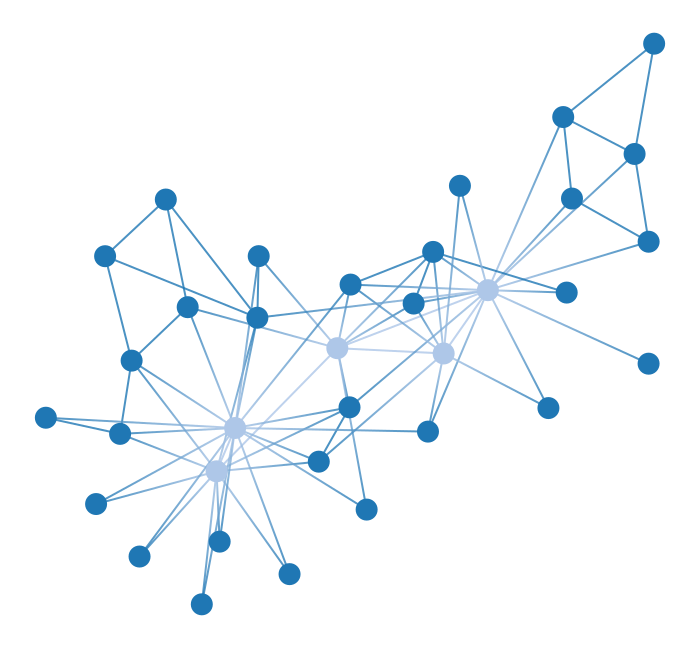

In [105]:
# 'karate' is one of graph-tool's built-in datasets (Appendix B). deg_corr=False is the plain SBM.
g = gt.collection.data['karate']
state = gt.minimize_blockmodel_dl(g, state_args=dict(deg_corr=False))

pos = gt.sfdp_layout(g)
state.draw(pos=pos, output_size=(350, 350), vertex_size=10);

Node colors are the inferred groups. Look at who ends up together: the plain SBM puts the few best-connected members in one group and everyone else in the other. It has split the club by degree, not by faction. This is the failure Section 11.5 described, and it is why degree correction exists.

---

### 13.5 Hands-on: recover planted communities in a synthetic SBM

We start with a synthetic graph where the "ground truth" is known.

In [106]:
# Synthetic planted partition
n_per_block = 50
B = 3
b_true = np.repeat(np.arange(B), n_per_block)

# Expected number of edges PER PAIR (a Poisson rate; close to a probability only when small)
p_in_pair = 0.15
p_out_pair = 0.01

# Convert to graph-tool's "probs" = expected edge counts between blocks
n = n_per_block
p_in  = p_in_pair  * n * (n - 1)   # = 2 * E[m_rr] for undirected
p_out = p_out_pair * n * n         # = E[m_rs] for r != s

probs = np.array([[p_in,  p_out, p_out],
                  [p_out, p_in,  p_out],
                  [p_out, p_out, p_in]], dtype=float)

g = gt.generate_sbm(b_true, probs, directed=False)
# generate_sbm draws Poisson counts, so g is a multigraph with a few self-loops and repeated edges.
# BlockState handles this. For a simple graph: gt.remove_parallel_edges(g); gt.remove_self_loops(g).
g.vp["b_true"] = g.new_vp("int", vals=b_true)


print("Generated SBM: V =", g.num_vertices(), "E =", g.num_edges())

Generated SBM: V = 150 E = 610


Inferred B: 3
Description length (entropy): 2208.95
Overlap with the planted partition: 0.9933333333333333


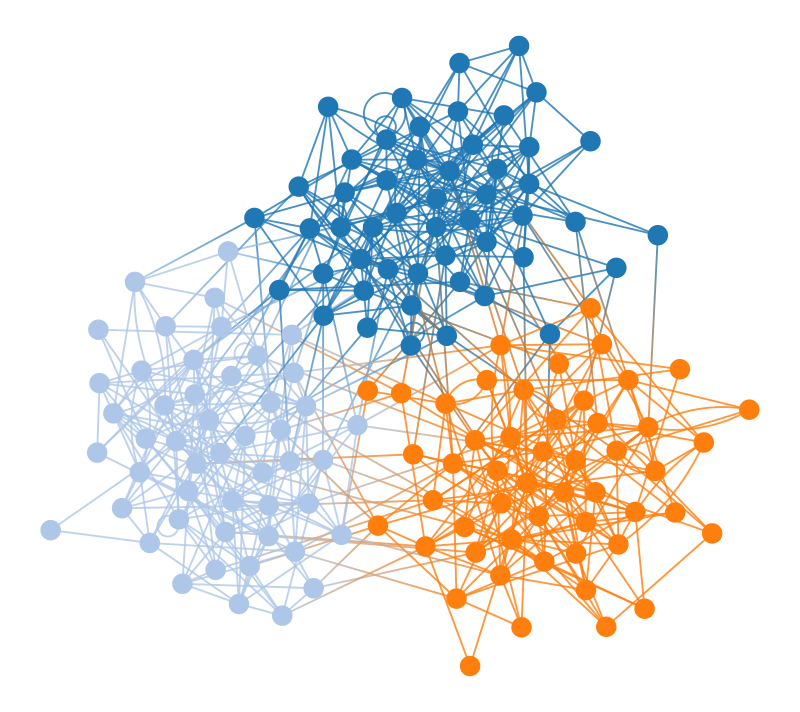

In [107]:
# Inference: non-degree-corrected SBM (fine for this toy)
state = gt.minimize_blockmodel_dl(g, state_args=dict(deg_corr=False))

b_hat = state.get_blocks()
B_hat = state.get_B()
dl = state.entropy()

print("Inferred B:", B_hat)
print("Description length (entropy):", round(dl, 2))
print("Overlap with the planted partition:", gt.partition_overlap(b_true, b_hat.a))

pos = gt.sfdp_layout(g)
state.draw(pos=pos, output_size=(400,400));

We never told the fit how many groups to look for. It should choose $B = 3$, the number we planted. An overlap of 1.0 would mean every node is in the right group (the overlap does not care how the groups are labelled); a value just below 1 means a few nodes landed in the wrong group, which noise in a random graph will do. The search is stochastic, so once in a while a run comes back with a small extra group. The description length means nothing alone. It is only useful for comparing two fits to the same graph, which we do next.

### 13.6 Comparing degree-corrected vs not

Even on the *same* graph, different SBM variants can yield different explanations.

Let's compare:
- non-degree-corrected SBM
- degree-corrected SBM

and look at description lengths.


In [108]:
state_plain = gt.minimize_blockmodel_dl(g, state_args=dict(deg_corr=False))
state_dc    = gt.minimize_blockmodel_dl(g, state_args=dict(deg_corr=True))

print("Plain SBM:")
print("  B =", state_plain.get_B(), "entropy =", round(state_plain.entropy(), 2))
print("Degree-corrected SBM:")
print("  B =", state_dc.get_B(), "entropy =", round(state_dc.entropy(), 2))

Plain SBM:
  B = 3 entropy = 2210.2
Degree-corrected SBM:
  B = 3 entropy = 2283.75


### 13.7 Turning description length differences into posterior odds

A powerful trick: compare two modeling choices (e.g., degree-corrected vs not) via:

$$\Delta \Sigma = \Sigma_1 - \Sigma_0.$$

Because $\Sigma = -\ln P(G, b\mid M)$, the posterior odds of the two (partition, model) pairs are, taking the two variants as equally likely a priori:

$$\frac{P(b_1, M_1\mid G)}{P(b_0, M_0\mid G)} = \exp(-\Delta\Sigma).$$

(This is not the ratio of evidences $P(G\mid M_1)/P(G\mid M_0)$, which would sum over every partition. See 12.14.)

So:

- if $\Delta\Sigma < 0$, model 1 is favored (higher joint posterior probability)
- if $\Delta\Sigma > 0$, model 0 is favored

You can also translate $\Delta\Sigma$ into bits:

$$\Delta\Sigma_{\mathrm{bits}} = \frac{\Delta\Sigma}{\ln 2}.$$

A difference of just **10 bits** corresponds to posterior odds of about $2^{10} \approx 1000$.

In [109]:
# We assume state_plain and state_dc exist from the previous cell.
S_plain = state_plain.entropy()
S_dc    = state_dc.entropy()

# Posterior odds of (b_dc, DC) vs (b_plain, plain) = exp(-(S_dc - S_plain))
dS = S_dc - S_plain
bf = float(np.exp(-dS))
dS_bits = dS / np.log(2)

print("Σ_plain =", round(S_plain, 3))
print("Σ_dc    =", round(S_dc, 3))
print("ΔΣ = Σ_dc - Σ_plain =", round(dS, 3), "nats =", round(dS_bits, 3), "bits")
print("Posterior odds of (b_dc, DC) vs (b_plain, plain) = exp(-ΔΣ) =", f"{bf:.2e}")

# Inspect the block matrix of the better fit
best = state_dc if S_dc < S_plain else state_plain
block_labels = np.unique(best.get_blocks().a)                           # labels in use (arbitrary integers, not 0,1,2)
e_rs = best.get_matrix().toarray()[np.ix_(block_labels, block_labels)]  # keep only the non-empty blocks
m_rs_hat = e_rs.copy()
m_rs_hat[np.diag_indices_from(m_rs_hat)] /= 2                           # graph-tool stores 2 x (within-block edges) on the diagonal

Σ_plain = 2210.205
Σ_dc    = 2283.747
ΔΣ = Σ_dc - Σ_plain = 73.543 nats = 106.1 bits
Posterior odds of (b_dc, DC) vs (b_plain, plain) = exp(-ΔΣ) = 1.15e-32


$\Delta\Sigma$ is positive, so the plain SBM wins: the degree-corrected model needs tens of nats more to describe this graph, and the odds printed above are tiny (they are printed in scientific notation: the number after the `e` is the power of ten). This is the right answer for this graph. We built it from a plain SBM, where all nodes in a block have the same expected degree. Degree correction adds a parameter for every node, and here those parameters explain nothing, so they are pure cost. On real networks with hubs the comparison usually goes the other way (PolBlogs, 15.2).

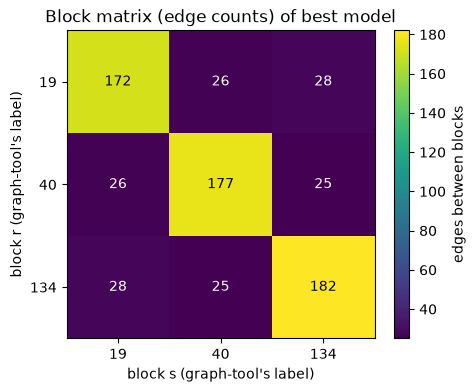

In [110]:
plt.figure(figsize=(5, 4),dpi=100)
plt.imshow(m_rs_hat)
plt.colorbar(label="edges between blocks")
plt.xticks(range(len(block_labels)), block_labels)
plt.yticks(range(len(block_labels)), block_labels)
for r in range(len(block_labels)):
    for s in range(len(block_labels)):
        plt.text(s, r, int(m_rs_hat[r, s]), ha="center", va="center",
                 color="w" if m_rs_hat[r, s] < m_rs_hat.max() / 2 else "k")
plt.title("Block matrix (edge counts) of best model")
plt.xlabel("block s (graph-tool's label)")
plt.ylabel("block r (graph-tool's label)")
plt.show()

### 13.8 Nested SBMs: multi-scale community structure

For many real networks, a flat partition is not enough.

`graph-tool` can infer nested/hierarchical structure with:
```python
state = gt.minimize_nested_blockmodel_dl(g)
```

This returns a `NestedBlockState`.
You can:
- print a summary
- draw the hierarchy
- access block memberships at each level


In [111]:
# A slightly larger synthetic example with 6 groups (2 super-groups)
n = 300
B = 6
b_true = np.repeat(np.arange(B), n//B)

# Make two super-communities: {0,1,2} and {3,4,5}
p_in  = 0.25   # at 0.10, the six groups are too faint to detect and the fit finds only the two super-groups
p_mid = 0.03
p_out = 0.005

# Build the matrix p_rs of expected edges PER PAIR (a Poisson rate; close to a probability only when small)
p = np.full((B, B), p_out, dtype=float)
np.fill_diagonal(p, p_in)

In [112]:
# within each super-group, between different blocks use p_mid
for r in range(3):
    for s in range(3):
        if r != s:
            p[r, s] = p_mid
for r in range(3, 6):
    for s in range(3, 6):
        if r != s:
            p[r, s] = p_mid

In [113]:
# Convert per-pair probabilities p_rs -> graph-tool propensities lambda_rs
sizes = np.array([(b_true == r).sum() for r in range(B)], dtype=int)
lam = np.zeros((B, B), dtype=float)

for r in range(B):
    for s in range(B):
        if r == s:
            # undirected convention: generate_sbm expects lam_rr = 2 * E[m_rr]
            # E[m_rr] = p_rr * C(n_r, 2)
            lam[r, r] = p[r, r] * sizes[r] * (sizes[r] - 1)
        else:
            # E[m_rs] = p_rs * n_r * n_s
            lam[r, s] = p[r, s] * sizes[r] * sizes[s]

In [114]:
g = gt.generate_sbm(b_true, lam, directed=False)
# (a multigraph again: a few dozen self-loops and a couple of hundred repeated edges, which the SBM handles)
g.vp["b_true"] = g.new_vp("int", vals=b_true)

print("Generated SBM: V =", g.num_vertices(), "E =", g.num_edges())

Generated SBM: V = 300 E = 2463


In [115]:
# Nested inference (degree correction often helps in real graphs)
nstate = gt.minimize_nested_blockmodel_dl(g, state_args=dict(deg_corr=True))

nstate.print_summary()
print("Total hierarchy description length:", round(nstate.entropy(), 2))

l: 0, N: 300, B: 6
l: 1, N: 6, B: 2
l: 2, N: 2, B: 1
l: 3, N: 1, B: 1
Total hierarchy description length: 8349.7


Each line is one level of the hierarchy. `l` is the level, `N` is how many things are being grouped at that level, and `B` is how many groups they go into. When the fit finds the planted structure, level 0 puts the 300 nodes into 6 groups, level 1 treats those 6 groups as nodes and puts them into 2, and level 2 merges the 2 into 1: six groups in two super-groups.

The search is stochastic. If your level 1 shows `B: 1` instead of `B: 2`, run the cell again and keep the fit with the smaller description length.

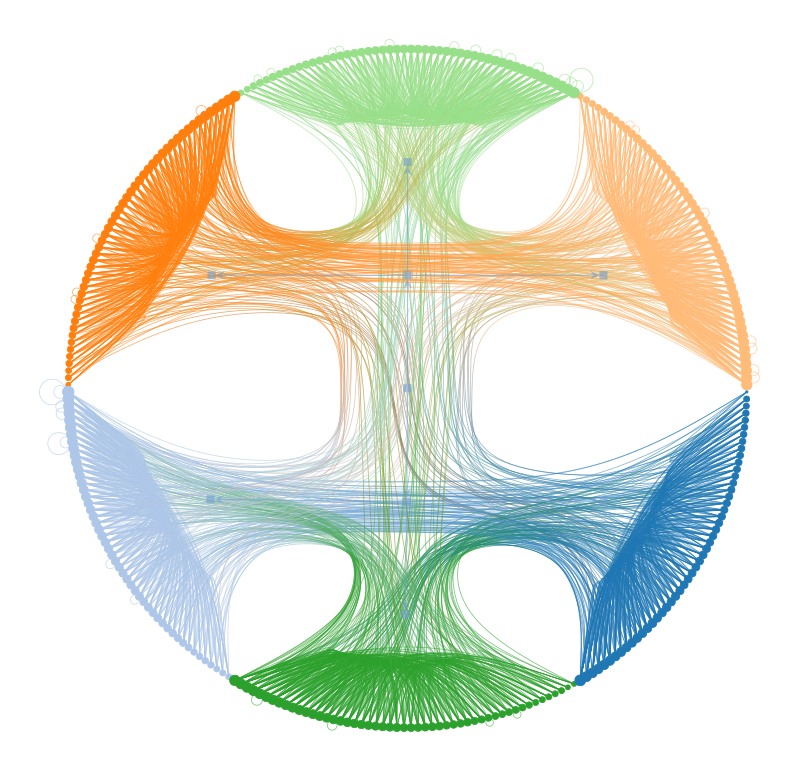

In [116]:
# Draw hierarchy
nstate.draw(output_size=(400, 400));

In the drawing, the 300 nodes sit on the outer circle, colored by their level-0 group. The tree in the middle is the hierarchy. The graph's edges are bent to follow the tree, so edges between the same two groups run together in a bundle. The small loops on the rim are self-loops: `generate_sbm` makes a few (Section 11.6).

In [117]:
# Get block memberships at each level
bs = nstate.get_bs()
B_per_level = [len(np.unique(b_l)) for b_l in bs]
print("Levels stored (graph-tool pads the top with one-group levels):", len(bs))
print("B at each level:", B_per_level)
print("Levels with more than one group:", sum(B_l > 1 for B_l in B_per_level))

Levels stored (graph-tool pads the top with one-group levels): 10
B at each level: [6, 2, 1, 1, 1, 1, 1, 1, 1, 1]
Levels with more than one group: 2


<!-- ### Checks for understanding (after §13)

1. What does `deg_corr=True` change in an SBM, and why does it matter for heavy-tailed degree distributions?
2. What is the difference between `minimize_blockmodel_dl(...)` and `minimize_nested_blockmodel_dl(...)` in terms of what the model is allowed to represent?
3. In `graph-tool`, why is the quantity $\Sigma$ (description length) a natural model selection score?
4. If the best-fitting model has $B=1$ block (no community structure), how should you interpret that result? -->


## 14. Uncertainty & MCMC: sampling partitions and getting marginals

A single inferred partition (an MDL optimum) can be misleading:

- many partitions may fit almost equally well
- block labels are arbitrary ("label switching")
- you often want *marginal* probabilities, not a single hard assignment

`graph-tool` gives you tools to:

1. **sample** partitions from the posterior (MCMC)
2. **summarize** the posterior:
   - vertex membership marginals ("soft" assignments)
   - consensus partitions ("hard" summaries)
   - uncertainty visualizations (pie charts, entropy, co-assignment matrices)

---

### 14.1 The posterior over partitions (conceptual)

Think of the SBM objective as a (negative log) posterior:

$$P(b \mid G) \propto \exp\bigl(-\Sigma(b)\bigr),$$

where $\Sigma(b)$ is the description length / entropy reported by `state.entropy()`.

---


### 14.2 MCMC and the Metropolis idea (high level)

MCMC (Markov chain Monte Carlo) is a random walk over partitions. At each step we propose a small change to the current partition $b$, called a move (for example, put one node in a different group), and then accept or reject it. A Markov chain is any random process like this, where the next step depends only on where you are now. The rule below is designed so that, over a long run, the walk visits each partition a fraction of the time equal to its posterior probability. That long-run pattern is the chain's stationary distribution.

A simplified Metropolis acceptance rule is:

$$\text{accept move } b\to b' \text{ with prob } 
\alpha = \min\left(1,\; \exp(-\beta[\Sigma(b')-\Sigma(b)])\right),$$

where:
- $\Delta\Sigma = \Sigma(b')-\Sigma(b)$ is the description-length change
- $\beta$ is an inverse temperature:
  - $\beta=1$: sample from the posterior
  - $\beta\to\infty$: greedy downhill search (optimization)

In words: a move that lowers $\Sigma$ is always accepted. A move that raises $\Sigma$ by $\Delta\Sigma$ is accepted with probability $e^{-\beta\,\Delta\Sigma}$, so small steps uphill happen often and big ones almost never. These $\alpha$ and $\beta$ have nothing to do with the Beta prior of Section 12. $\alpha$ is the acceptance probability. $\beta$ is a dial, called inverse temperature after its role in physics: $\beta = 1$ gives the sampling we want, and a larger $\beta$ makes the walk refuse uphill moves.

(Real implementations include proposal probabilities and extra move types, but this captures the core idea.)

---


### 14.2.1 Why Metropolis works (the one equation: detailed balance)

We want our Markov chain to have stationary distribution:

$$
\pi(b) \propto \exp(-\beta\,\Sigma(b)).
$$

A common sufficient condition is **detailed balance**:

$$
\pi(b)\,q(b\to b')\,\alpha(b\to b')
=
\pi(b')\,q(b'\to b)\,\alpha(b'\to b),
$$

where:

- $q(b\to b')$ is the proposal probability
- $\alpha(b\to b')$ is the acceptance probability

In words: in the long run, the walk steps from $b$ to $b'$ exactly as often as from $b'$ to $b$. If that holds for every pair, $\pi$ does not change from one step to the next, which is what stationary means. $q(b \to b')$ is the probability that the algorithm suggests $b'$ when it is at $b$.

If the proposal is symmetric ($q(b\to b')=q(b'\to b)$), detailed balance holds if we choose:

$$
\alpha(b\to b') = \min\left(1, \frac{\pi(b')}{\pi(b)}\right)
= \min\left(1, \exp\bigl(-\beta[\Sigma(b')-\Sigma(b)]\bigr)\right).
$$

Check it for the case $\pi(b') \le \pi(b)$. The left side is $\pi(b)\cdot\frac{\pi(b')}{\pi(b)} = \pi(b')$ and the right side is $\pi(b')\cdot 1$. They match. Notice that only the ratio $\pi(b')/\pi(b)$ appears. The constant hidden in $\propto$ cancels, so we never have to add up $e^{-\Sigma}$ over all partitions.

That's the Metropolis rule.

---

### 14.2.2 Practical diagnostics: burn-in and autocorrelation

MCMC is powerful, but you should build two habits:

1) **Look at a trace plot** of $\Sigma$ (or some statistic).  
   - early iterations can reflect initialization ("burn-in")
   - later iterations should look like noisy fluctuations around a stable region

2) **Expect autocorrelation.**  
   Successive samples are not independent. If you record every iteration, you'll get many nearly-duplicate samples.

A simple diagnostic is the lag-$\ell$ autocorrelation:

$$
\rho(\ell) = \frac{\mathrm{Cov}(\Sigma_t,\Sigma_{t+\ell})}{\mathrm{Var}(\Sigma_t)}.
$$

When $\rho(\ell)$ decays slowly, you need either:
- more sweeps, or
- thinner samples (record every $k$ sweeps), or
- better proposals (graph-tool handles many of these details for you, but you still need to *think* statistically).


### 14.3 Label switching (why "block 0" is not meaningful)

If you permute labels (rename blocks), the partition is the same grouping structure.
This means raw MCMC samples can "jump" in label space even when they haven't changed in meaning.

`PartitionModeState` solves this by aligning labels across samples so we can compute meaningful marginals.

---

### 14.4 Hands-on: posterior marginals as "pie charts" (Karate Club)

We will:

1. fit a degree-corrected SBM
2. run MCMC to sample partitions
3. compute vertex marginals
4. visualize uncertainty as pie charts

Two terms in the code: to equilibrate a chain is to run it until it has forgotten where it started, and DL is short for description length.

Initial entropy: 222.89 B = 1
Collected samples: 49
Entropy range: 222.89013084344728 to 244.97855153368147


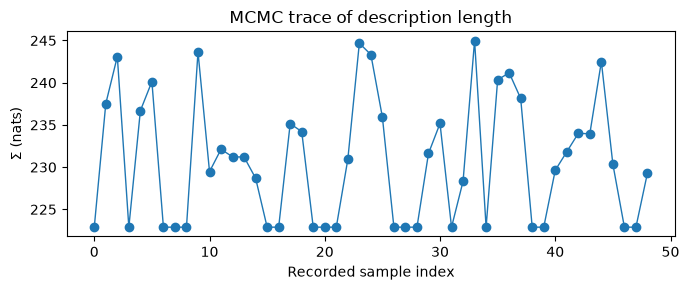

autocorr(lag= 1) ≈ 0.157
autocorr(lag= 2) ≈ -0.248
autocorr(lag= 5) ≈ -0.158
autocorr(lag=10) ≈ -0.160


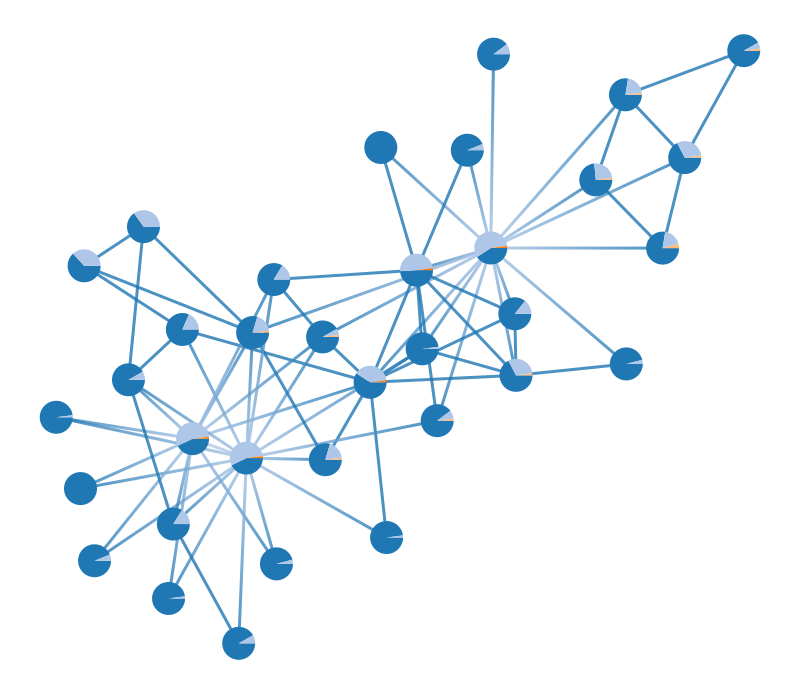

In [118]:
g = nx_to_gt(nx.karate_club_graph())

# Fit a degree-corrected SBM
state = gt.minimize_blockmodel_dl(g, state_args=dict(deg_corr=True))
print("Initial entropy:", round(state.entropy(), 2), "B =", state.get_B())

# We'll record both partitions and description lengths along the chain
partitions = []
entropies = []

def record_state(s):
    partitions.append(s.get_blocks().a.copy())
    entropies.append(s.entropy())

# Equilibrate + collect
gt.mcmc_equilibrate(
    state,
    wait=20,                # stop after 20 iterations in a row with no new record high or low of Σ,
                            # twice (nbreaks=2); ignored here because force_niter is set
    force_niter=50,         # run exactly 50 iterations
    mcmc_args=dict(niter=5),# sweeps per iteration; the callback fires after every iteration
                            # except the last, so we get 49 samples
    callback=record_state,
    verbose=False
)

entropies = np.asarray(entropies)
print("Collected samples:", len(partitions))
print("Entropy range:", float(entropies.min()), "to", float(entropies.max()))

# Trace plot of Σ (description length)
plt.figure(figsize=(7, 3))
plt.plot(entropies, marker="o", linewidth=1)
plt.xlabel("Recorded sample index")
plt.ylabel("Σ (nats)")
plt.title("MCMC trace of description length")
plt.tight_layout()
plt.show()

# A tiny autocorrelation helper (for intuition, not for publication-grade estimates of the effective
# sample size, ESS: the number of independent samples the chain is worth)
def autocorr(x, lag):
    x = np.asarray(x)
    x0 = x[:-lag]
    x1 = x[lag:]
    return np.corrcoef(x0, x1)[0, 1]

for lag in [1, 2, 5, 10]:
    if len(entropies) > lag + 2:
        print(f"autocorr(lag={lag:>2}) ≈ {autocorr(entropies, lag):.3f}")

# Align labels + compute vertex marginals
pmode = gt.PartitionModeState(partitions, relabel=True, converge=True)
pv = pmode.get_marginal(g)  # VertexPropertyMap with vector<int> counts

# Draw: node pie charts show uncertainty (multi-membership probability mass)
pos = gt.sfdp_layout(g)
state.draw(
    pos=pos,
    vertex_shape="pie",
    vertex_pie_fractions=pv,
    vertex_size=15,
    output_size=(400, 400)
);


**Reading the output.** (1) $B = 1$: the single best partition under the degree-corrected SBM puts all 34 members in one group. That does not mean the two factions are imaginary. It means that with only 34 nodes and 78 edges, a two-group description costs slightly more than it saves. Two-group partitions are nearly as good, and the sampler visits them. (2) The trace has a floor at 222.89. That is the one-group partition the fit started from. The chain keeps coming back to it and making excursions to worse partitions. You do not see the downward drift of a burn-in, because we started at the best partition. (3) The autocorrelations are small, so samples a few iterations apart are close to independent. Do not read anything into which ones come out negative: with only 49 samples, anything within about $\pm 0.3$ of zero cannot be told apart from zero.

### 14.5 Quantifying uncertainty: consensus partition, entropy, and co-assignment

Visualizations are great, but you also want **numbers**.

Three common summaries:

1. **Consensus ("max marginal") partition**  
   Assign each node to its most probable block:

   $$\hat b_i = \arg\max_r \; P(b_i=r \mid G).$$

2. **Mean-field entropy of node marginals**  
   If $p_{ir} = P(b_i=r\mid G)$, then one natural uncertainty measure is:

   $$H_{\mathrm{MF}} = -\sum_i \sum_r p_{ir}\log p_{ir}.$$

   This is near 0 when assignments are nearly deterministic, and larger when nodes are ambiguous.

3. **Co-assignment matrix**  
   Define:

   $$C_{ij} = P(b_i=b_j\mid G).$$

   This is a very interpretable object: it tells you which pairs of nodes are "almost always" together vs "often split".

We'll compute all three below.

In [119]:
# --- MCMC sampling settings ---
burnin = 2000          # sweeps to forget initialization
thin = 20              # keep one sample every 'thin' sweeps
n_samples = 200        # number of saved samples

# --- Run burn-in ---
# multiflip_mcmc_sweep also proposes merging and splitting whole groups; with single-node moves
# (state.mcmc_sweep) this chain can sit at B = 1 for the whole run
# beta=1.0 is the β of Section 14.2: sample from the posterior instead of optimizing
for _ in range(burnin):
    state.multiflip_mcmc_sweep(beta=1.0, niter=1)

# --- Collect samples of block assignments ---
samples = []
Bs = []

for t in range(n_samples):
    for _ in range(thin):
        state.multiflip_mcmc_sweep(beta=1.0, niter=1)

    b = state.get_blocks().a.copy()   # length N
    samples.append(b)
    Bs.append(len(np.unique(b)))

samples = np.asarray(samples)  # shape (n_samples, N)
Bs = np.asarray(Bs)

print("Sampled B (min/median/max):", Bs.min(), int(np.median(Bs)), Bs.max())
print("Fraction with B=1:", np.mean(Bs == 1))


# Sanity checks (helps if you run cells out of order)
N = samples.shape[1]
print("Sample matrix shape:", samples.shape, "| g.num_vertices() =", g.num_vertices())
assert N == g.num_vertices(), "Mismatch: samples were generated for a different graph than 'g'. Re-run the sampling cell."


Sampled B (min/median/max): 1 1 3
Fraction with B=1: 0.6
Sample matrix shape: (200, 34) | g.num_vertices() = 34


Read the last line: a large share of the sampled partitions, half or more, have a single group, and the rest have a few. The posterior is split between no communities and a few communities. The single best partition, which said $B = 1$, hides this.

In [120]:
# Co-assignment (co-clustering) matrix from raw MCMC samples.
#
# Definition:
#   C[i,j] = fraction of posterior samples where i and j are assigned to the same block.
#
# This object is *label-invariant*: it does not care what the numeric block labels are,
# only whether two nodes match within each sample.

samples_arr = np.asarray(samples)
N = samples_arr.shape[1]

print("Using samples array with shape:", samples_arr.shape)
assert N == g.num_vertices(), "Mismatch: samples were generated for a different graph than 'g'. Re-run the sampling cell."

C = np.zeros((N, N), dtype=float)
for b in samples_arr:
    C += (b[:, None] == b[None, :]).astype(float)

C /= len(samples_arr)
print("Co-assignment matrix computed from", len(samples_arr), "samples.")

Using samples array with shape: (200, 34)
Co-assignment matrix computed from 200 samples.


Consensus B (nonempty): 1
Mean-field entropy of node marginals: 13.233 (nats)


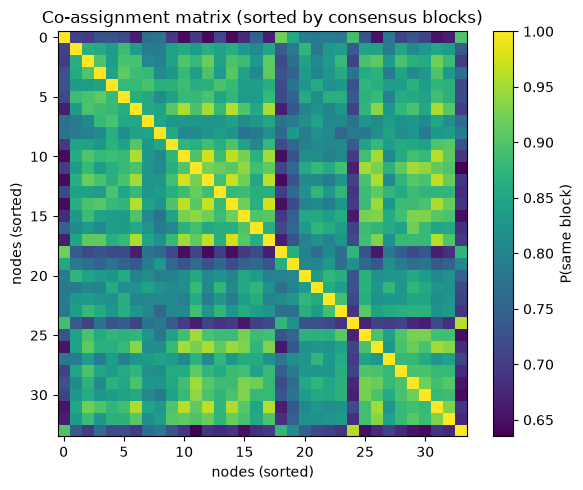

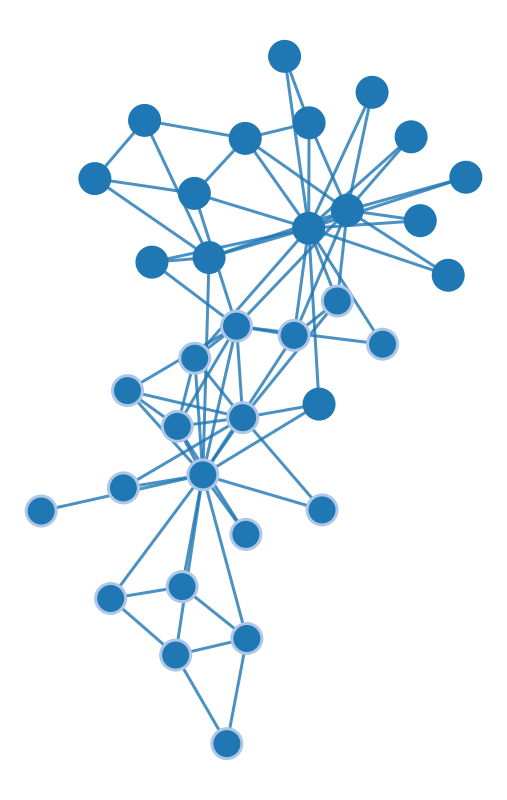

In [121]:
# 1) Consensus partition (max marginal) via PartitionModeState
#
# Align labels across the 200 thinned samples from the cell above, and recompute the marginals
# from them. This gives a *label-aligned* view of the posterior and is convenient for marginals.
pmode = gt.PartitionModeState(list(samples), relabel=True, converge=True)
pv = pmode.get_marginal(g)

b_max = pmode.get_max(g)  # int-valued VertexPropertyMap
b_max_arr = np.asarray(b_max.a)
print("Consensus B (nonempty):", len(np.unique(b_max_arr)))

# 2) Mean-field entropy of node marginals (graph-tool convenience)
#
# Intuition:
# - If each node's marginal is concentrated on one block, entropy is low (confident assignments).
# - If many nodes have spread-out marginals, entropy is higher (uncertainty / boundary nodes).

H_mf = gt.mf_entropy(g, pv)
print("Mean-field entropy of node marginals:", round(H_mf, 3), "(nats)")

# 3) Visualize the co-assignment matrix (computed from raw samples)
#
# We sort nodes by the consensus labels so the block structure is easier to see.

# If C isn't in memory (e.g., you ran cells out of order), recompute it from `samples`.
try:
    C
except NameError:
    samples_arr = np.asarray(samples)
    N = samples_arr.shape[1]
    assert N == g.num_vertices(), "Mismatch: samples were generated for a different graph than 'g'. Re-run the sampling cell."
    C = np.zeros((N, N), dtype=float)
    for b in samples_arr:
        C += (b[:, None] == b[None, :]).astype(float)
    C /= len(samples_arr)

order = np.argsort(b_max_arr)

fig, ax = plt.subplots(1, 1, figsize=(6, 5), dpi=100)
im = ax.imshow(C[order][:, order], aspect="auto")
fig.colorbar(im, ax=ax, label="P(same block)")
ax.set_title("Co-assignment matrix (sorted by consensus blocks)")
ax.set_xlabel("nodes (sorted)")
ax.set_ylabel("nodes (sorted)")
plt.tight_layout()
plt.show()

# Draw consensus partition (hard colors, no pie charts)
pos = gt.sfdp_layout(g)
state.draw(pos=pos, vertex_fill_color=b_max, output_size=(400, 400), vertex_size=15);

**Reading the output.** The consensus partition gives each node its most likely label. That is a different question from the single best overall description, so the two need not agree: with the posterior split between one group and a few, the consensus can come out as one group in one run and two in the next. For scale on the entropy: if all 34 nodes were split 50/50 between two groups it would be $34 \ln 2 \approx 23.6$ nats, and if every node were certain it would be 0. In the heat map, look at the color scale first: it does not start at 0. In every sample with a single group, every pair of nodes is together, so no entry can fall below the fraction of one-group samples printed above. The darker rows and columns are nodes that often split away from the rest.

### 14.6 Reading the pie charts

- A node with a **single dominant color** is confidently assigned to one block.
- A node with a **mixed pie** is uncertain (it plausibly belongs to multiple groups).
- Boundary / bridge nodes often show higher uncertainty.

> **Checkpoint:** Under the degree-corrected SBM, Karate's single best partition has just one group (the `B = 1` printed at the top of 14.4), yet the sampler keeps visiting partitions with more groups. Which nodes have the most mixed pies? Are they the "bridge" nodes between the two factions, or the high-degree hubs? What is the model uncertain about?

---

### 14.7 Alternative: collecting marginals directly from `state`

`state.collect_vertex_marginals()` accumulates membership counts, but you must handle label switching carefully.

`PartitionModeState` is usually the easiest way for beginners.


## 15. Social science case study: PolBlogs polarization + posterior predictive checks

This is a classic dataset in computational social science:
- blogs as nodes
- hyperlinks as edges
- known political orientation (often: liberal vs conservative)
- strong polarization (assortative mixing by ideology)

We'll use it to practice:
1. cleaning and inspecting a real graph-tool dataset
2. choosing a model (degree-corrected vs not) using description length
3. interpreting blocks as social structure
4. checking whether the model captures key features (posterior predictive checks)

> PolBlogs ships with `graph-tool`, so this works offline.

---

### 15.1 Load and prepare the data


In [122]:
# PolBlogs ships with graph-tool's built-in collection, so no download is needed
g0 = gt.collection.data["polblogs"]
source = "gt.collection.data['polblogs']"
# except Exception:
#     g0 = gt.collection.ns["polblogs"]
#     source = "gt.collection.ns['polblogs']"

# Work on a *copy* we can safely edit (remove edges, prune components, etc.)
g = gt.Graph(g0)
g.set_directed(False)

# Clean up multigraph artifacts (common when data are merged from multiple sources)
gt.remove_parallel_edges(g)
gt.remove_self_loops(g)

# Largest connected component (return a pruned Graph, not just a view)
g = gt.extract_largest_component(g, directed=False, prune=True)

print("Loaded:", source)
print("V =", g.num_vertices(), "E =", g.num_edges())
print("Vertex properties:", list(g.vp.keys()))
print("Edge properties:", list(g.ep.keys()))


Loaded: gt.collection.data['polblogs']
V = 1222 E = 16714
Vertex properties: ['label', 'value', 'pos', 'source']
Edge properties: []


### 15.2 Fit nested SBMs (degree-corrected vs not) and compare description lengths

We'll fit two models:
- **non-degree-corrected** nested SBM
- **degree-corrected** nested SBM

and choose the one with smaller description length.

> This is model selection: "which explanation compresses the network best?"


In [123]:
# Fit models (can take some time depending on machine)
state_ndc = gt.minimize_nested_blockmodel_dl(g, state_args=dict(deg_corr=False))
state_dc  = gt.minimize_nested_blockmodel_dl(g, state_args=dict(deg_corr=True))

dl_ndc = state_ndc.entropy()
dl_dc  = state_dc.entropy()

print("Nested SBM (non-degree-corrected) DL:", round(dl_ndc, 2))
print("Nested SBM (degree-corrected)     DL:", round(dl_dc,  2))

best = state_dc if dl_dc < dl_ndc else state_ndc
print("\nSelected model:", "degree-corrected" if best is state_dc else "non-degree-corrected")

Nested SBM (non-degree-corrected) DL: 51676.24
Nested SBM (degree-corrected)     DL: 51095.11

Selected model: degree-corrected


The degree-corrected model is shorter by hundreds of nats. By the rule in 13.7, even 100 nats would be odds of $e^{100} \approx 10^{43}$, so this is not a close call. Compare 13.6, where degree correction lost on a synthetic graph with no hubs. PolBlogs has a few very popular blogs and many obscure ones, so the degree parameters pay for themselves.

### 15.3 Visualize the inferred macro-structure

Nested SBMs contain multiple levels.  
For social science interpretation, it's often useful to look at a **coarse** level (few groups).

We'll:
1. inspect the number of groups at each level
2. select the *coarsest* level with, say, 2-10 groups
3. project that partition back onto the original graph
4. draw it


B by level (0 = finest): [25, 4, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Chosen level: 1 with B = 4


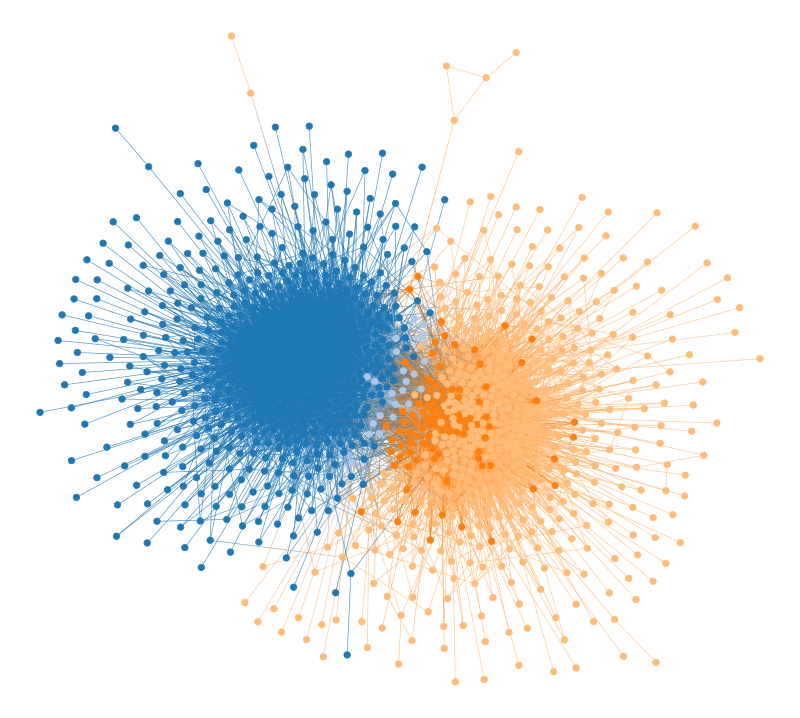

In [124]:
# Choose the best model from previous cell
try:
    best
except NameError:
    best = gt.minimize_nested_blockmodel_dl(g, state_args=dict(deg_corr=True))

# Determine number of groups at each level
bs = best.get_bs()
Bs = [len(np.unique(b)) for b in bs]
print("B by level (0 = finest):", Bs)

# Pick a coarse level with 2..10 groups (fallback: level 0)
candidate_levels = [i for i, B in enumerate(Bs) if 2 <= B <= 10]
level = candidate_levels[-1] if candidate_levels else 0
print("Chosen level:", level, "with B =", Bs[level])

# Project that level to a flat BlockState on the original graph
state_coarse = best.project_level(level)

# Choose positions: dataset often provides g.vp['pos']
pos = g.vp["pos"] if "pos" in g.vp else gt.sfdp_layout(g)

state_coarse.draw(pos=pos, output_size=(400, 400));

### 15.4 Quantify polarization: assortativity by ideology and by inferred blocks

**Assortativity** is a normalized "like connects to like" score.

For a categorical label $x \in \{1,\dots,K\}$, define a mixing matrix:

- $e_{ij}$: fraction of edges from type $i$ to type $j$ (for an undirected graph, count each edge once in each direction)
- $a_i = \sum_j e_{ij}$, $b_j = \sum_i e_{ij}$

Then the assortativity coefficient (Newman) is:

$$r = \frac{\sum_i e_{ii} - \sum_i a_i b_i}{1-\sum_i a_i b_i}.$$

Interpretation:
- $r \approx 1$: almost all edges are within the same type (strong homophily / polarization)
- $r \approx 0$: connections are close to random mixing (given each type's share of edge ends)
- $r < 0$: disassortative mixing (edges tend to go across types)

In the PolBlogs dataset, we can compute assortativity for:
- **inferred blocks** (model-implied polarization / segmentation)
- **known ideology label** (if provided as a vertex property)

We'll use `gt.assortativity()`, which returns $r$ and its standard error, estimated with the jackknife (recompute $r$ with each edge left out in turn and measure how much it moves). The graph-tool docstring calls this second number a variance, but the value returned is already a standard deviation, so do not take its square root.

In [125]:
# inferred block labels
b = state_coarse.get_blocks()

r_blocks, err_blocks = gt.assortativity(g, b)   # (r, its jackknife standard error)
print("Assortativity by inferred blocks:", round(r_blocks, 3), "+/-", round(err_blocks, 3))

# Try to detect a known ideology property map automatically
label_candidates = ["value", "label", "party", "ideology", "pol", "color"]
known_key = next((k for k in label_candidates if k in g.vp), None)

if known_key is None:
    print("No obvious ideology label found in g.vp. (That's okay.)")
else:
    y = g.vp[known_key]
    r_y, err_y = gt.assortativity(g, y)
    print(f"Assortativity by known label '{known_key}':", round(r_y, 3), "+/-", round(err_y, 3))

Assortativity by inferred blocks: 0.519 +/- 0.005
Assortativity by known label 'value': 0.811 +/- 0.005


By the recorded political label, assortativity is 0.81: blogs link overwhelmingly to their own side. By the model's inferred groups it is lower, and it changes from run to run, because the level we drew has four or five groups rather than two and is not the same partition every time. Finer groups leave more edges running between groups. Both values are clearly above 0, the value for random mixing.

### 15.5 Posterior predictive checks: does the fitted model reproduce key statistics?

A foundational Bayesian habit:

> Fit a generative model → **simulate replicated data** from the fitted model → compare to what you observed.

For a network model with latent structure $(b,\theta)$, the **posterior predictive** distribution is:

$$P(G_{\mathrm{rep}} \mid G)
= \int P(G_{\mathrm{rep}} \mid b,\theta)\;P(b,\theta \mid G)\, db\, d\theta.$$

(The integral over $b$ is really a sum over partitions.)

In practice, we approximate this by:
1. fitting a state (here a single fitted partition stands in for the posterior; a fuller check would also sample partitions with MCMC)
2. sampling replicated graphs $G_{\mathrm{rep}}$ from the fitted state
3. computing statistics $T(G_{\mathrm{rep}})$ and comparing to $T(G)$

If the observed statistic is consistently extreme under the replicated distribution, the model is missing something.

`sample_graph()` draws from graph-tool's SBM, which is a model of multigraphs. Every replicate has the observed number of edges and the observed degrees, but some edges are self-loops or repeats of the same pair. We remove those so replicates are cleaned the same way as the data, which leaves roughly 15% fewer edges (the cell prints the count). Part of any gap you see below comes from that step.

Below we check several statistics:
- global clustering coefficient
- degree assortativity (by degree)
- approximate average shortest-path length (via sampled source vertices)

You can add more: motif counts, rich-club coefficients, reciprocity (directed graphs), etc.

Observed stats:
  global clustering         : 0.226
  degree assortativity      : -0.2213
  avg shortest-path length  : 2.74



Replicate edges after cleaning: mean 14293 vs observed 16714

Posterior predictive p-values (upper tail, lower tail, two-sided):
  clustering    : [0.0385, 1.0, 0.0769]
  assortativity : [1.0, 0.0385, 0.0769]
  path length   : [0.9615, 0.0769, 0.1538]


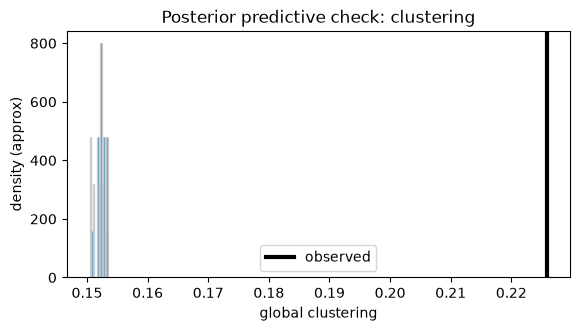

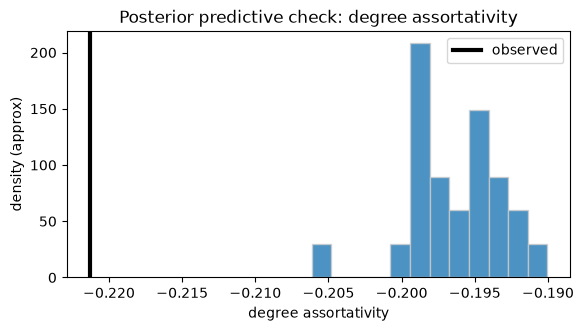

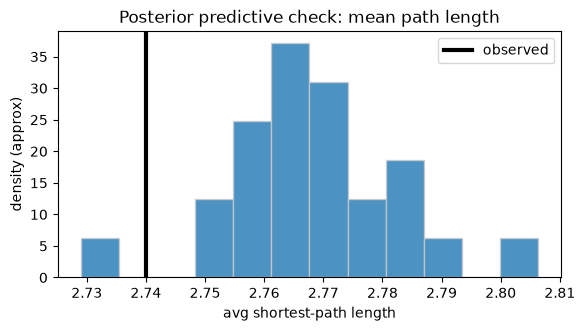

In [126]:
# We'll use the finest level (level 0) for sampling replicated graphs
base_state = best.get_levels()[0]  # BlockState on original graph

# For statistics, we'll treat the graph as undirected
g_obs = gt.GraphView(g, directed=False)

def compute_stats(g_in, dist_samples=500):
    # Return a small vector of network summary statistics.
    # (We keep this tiny, but you can extend it easily.)
    # 1) global clustering
    c = gt.global_clustering(g_in)[0]

    # 2) degree assortativity (scalar assortativity of total degree)
    r_deg = gt.scalar_assortativity(g_in, "total")[0]

    # 3) approximate average shortest-path length via distance histogram
    counts, bins = gt.distance_histogram(g_in, bins=[0, 1], samples=dist_samples)
    dists = bins[:-1]  # bin [d, d+1) holds the pairs at distance exactly d

    # drop distance 0 (self-pairs)
    mask = dists > 0
    apl = float((dists[mask] * counts[mask]).sum() / counts[mask].sum())

    return c, r_deg, apl

# Observed statistics
c_obs, rdeg_obs, apl_obs = compute_stats(g_obs, dist_samples=1000)
print("Observed stats:")
print("  global clustering         :", round(c_obs, 4))
print("  degree assortativity      :", round(rdeg_obs, 4))
print("  avg shortest-path length  :", round(apl_obs, 3))

# Sample from the fitted model
n_samp = 25
stats = []
E_rep = []   # edges left in each replicate after cleaning

for _ in range(n_samp):
    gs = base_state.sample_graph()  # replicate from fitted model
    gt.remove_parallel_edges(gs)
    gt.remove_self_loops(gs)
    E_rep.append(gs.num_edges())

    gs = gt.GraphView(gs, directed=False)
    stats.append(compute_stats(gs, dist_samples=500))

stats = np.array(stats)
c_samp    = stats[:, 0]
rdeg_samp = stats[:, 1]
apl_samp  = stats[:, 2]

print("\nReplicate edges after cleaning: mean", int(np.mean(E_rep)), "vs observed", g_obs.num_edges())

def mc_pvalues(null_samples, obs):
    n_rep = len(null_samples)
    p_hi = (1 + np.sum(null_samples >= obs)) / (n_rep + 1)   # share of replicates at or above the observed value
    p_lo = (1 + np.sum(null_samples <= obs)) / (n_rep + 1)   # share at or below it
    return p_hi, p_lo, min(1.0, 2 * min(p_hi, p_lo))         # two-sided

print("\nPosterior predictive p-values (upper tail, lower tail, two-sided):")
for stat_name, samp, obs in [("clustering", c_samp, c_obs), ("assortativity", rdeg_samp, rdeg_obs),
                             ("path length", apl_samp, apl_obs)]:
    print(f"  {stat_name:14s}:", [round(float(p), 4) for p in mc_pvalues(samp, obs)])

# Plot PPC distributions
def ppc_hist(samples, obs, title, xlabel):
    
    plt.figure(figsize=(6.5, 3.2))

    plt.hist(samples, bins=12, density=True, ec='.8', alpha=0.8)
    plt.axvline(obs, linewidth=3, label="observed", color='k')
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("density (approx)")
    plt.legend()

    plt.show()

ppc_hist(c_samp,    c_obs,    "Posterior predictive check: clustering", "global clustering")
ppc_hist(rdeg_samp, rdeg_obs, "Posterior predictive check: degree assortativity", "degree assortativity")
ppc_hist(apl_samp,  apl_obs,  "Posterior predictive check: mean path length", "avg shortest-path length")

**Reading the p-values.** With 25 replicates the smallest value either tail can take is $1/26 = 0.0385$. A one-sided value of 1.0 means every replicate was at or above the observed value, which is as extreme as 0.0385 in the other direction. In the run saved here, the observed clustering is higher than every replicate and the observed degree assortativity is more negative than every replicate. The observed path length sits at or near the short end of the replicates.

### 15.6 Interpretation prompts (for discussion)

1. Does the inferred *coarse* partition look like "two big camps"?
2. Are there smaller subcommunities within camps?
3. Which nodes appear as bridges between groups?
4. In the posterior predictive check:
   - Is the observed clustering typical under the model?
   - If not, what kinds of mechanisms might increase clustering beyond SBM?
     (e.g., triadic closure, geometric constraints, social circles)

---

### 15.7 Exercises + further resources

#### Exercises (suggested)
1. **NetworkX → graph-tool translation drill**  
   Take a NetworkX graph you built in a previous assignment and:
   - convert to graph-tool
   - compute betweenness and clustering in both libraries
   - verify results agree (approximately)

2. **Model comparison**  
   On PolBlogs (or another dataset):
   - compare `deg_corr=True` vs `deg_corr=False`
   - record description lengths and inferred B per level
   - write a short interpretation: *why do you think one wins?*

3. **Uncertainty**  
   For Karate Club:
   - compute marginals with MCMC
   - identify the most uncertain nodes
   - relate uncertainty to graph position (bridges, cut vertices, etc.)

4. **Posterior predictive checks**  
   Pick a statistic (e.g., average path length, assortativity by degree) and test whether the fitted SBM reproduces it.

#### Further reading / references
- graph-tool cookbook: **Inferring modular network structure** (official docs)
- Tiago Peixoto's papers on Bayesian/MDL SBM inference and nested SBMs
- A reminder: generative models are *useful stories*, not "truth machines"



### Checks for understanding (after §15)

1. In the PolBlogs example, what features of the graph are you implicitly asking the SBM to explain?
2. Posterior predictive checks ask: "If the model were true, would data like this be typical?"  
   What did you choose to check here, and what would be a good *additional* check for this dataset?
3. If you have node metadata (e.g., "liberal" / "conservative"), where should it enter the analysis: as **validation**, as **priors**, or as **covariates**? What are the risks of each?


## 16. Community detection gallery: fit SBMs on several networks and compare the pictures

PolBlogs is a great teaching dataset because it has a clear political interpretation.

But one danger in learning any method from a single dataset is that you start thinking the method *always* produces the same kind of output.

So here we do something simple:

- load a few networks with very different structures
- fit the same **degree-corrected nested SBM** workflow
- draw the resulting coarse partition

The goal is not to argue that SBMs are "right" for every dataset.  
The goal is to build **visual intuition** for what these partitions look like across domains.

> If a dataset fails to download on a given machine (network restrictions), skip it and run the ones that work.


In [127]:
from IPython.display import display

def load_dataset(name):
    """Try gt.collection.data first, then gt.collection.ns. Fallback to a few NetworkX built-ins.
    (`ns` is Netzschleuder, an online catalogue of network datasets; see Appendix B.)"""
    # graph-tool collections (may download on first use)
    try:
        g0 = gt.collection.data[name]
        return g0, f"gt.collection.data['{name}']"
    except Exception:
        try:
            g0 = gt.collection.ns[name]
            return g0, f"gt.collection.ns['{name}']"
        except Exception:
            pass

    # A few offline fallbacks via NetworkX
    if name == "karate":
        return nx_to_gt(nx.karate_club_graph()), "NetworkX: karate_club_graph() (fallback)"
    if name == "karate_nx":
        return nx_to_gt(nx.karate_club_graph()), "NetworkX: karate_club_graph()"
    if name == "lesmis_nx":
        return nx_to_gt(nx.les_miserables_graph()), "NetworkX: les_miserables_graph()"
    if name == "florentine_nx":
        return nx_to_gt(nx.florentine_families_graph()), "NetworkX: florentine_families_graph()"

    raise KeyError(f"Could not load dataset '{name}'.")

def clean_undirected_simple(g_in):
    """Return a cleaned, simple, undirected graph.

    Steps:
    - copy the input graph (so edits are safe),
    - make it undirected,
    - remove parallel edges and self-loops,
    - keep only the largest connected component.

    This keeps the gallery focused on community structure instead of artifacts.
    """
    g = gt.Graph(g_in)
    g.set_directed(False)

    gt.remove_parallel_edges(g)
    gt.remove_self_loops(g)

    g = gt.extract_largest_component(g, directed=False, prune=True)
    return g

In [128]:
def draw_state(state, g, title, level=0):
    st = state.project_level(level)
    pos = g.vp["pos"] if "pos" in g.vp else gt.sfdp_layout(g)
    print(title)
    print("  vertices:", g.num_vertices(), "edges:", g.num_edges())
    print("  chosen level:", level)
    st.draw(pos=pos, output_size=(400,400))


def fit_nested_sbm_and_choose_level(g, B_min=2, B_max=10, deg_corr=True, mcmc_args={}):
    state = gt.minimize_nested_blockmodel_dl(g, state_args=dict(deg_corr=deg_corr),
                                             multilevel_mcmc_args=mcmc_args)

    # Determine B at each level
    bs = state.get_bs()
    Bs = [len(np.unique(np.asarray(b))) for b in bs]

    # Choose a "teaching level": coarse but not trivial
    candidate_levels = [i for i, B in enumerate(Bs) if B_min <= B <= B_max]
    level = candidate_levels[-1] if candidate_levels else 0

    
    return state, level, Bs

Karate Club (classic social network)  |  gt.collection.data['karate']  |  B by level = [1, 1, 1, 1, 1, 1, 1]
  vertices: 34 edges: 78
  chosen level: 0


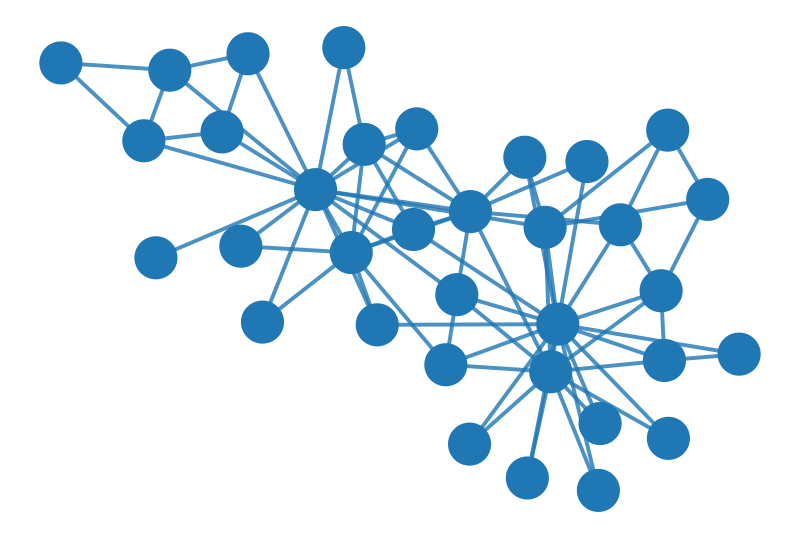

---
Dolphins (animal social network)  |  gt.collection.data['dolphins']  |  B by level = [2, 1, 1, 1, 1, 1, 1]
  vertices: 62 edges: 159
  chosen level: 0


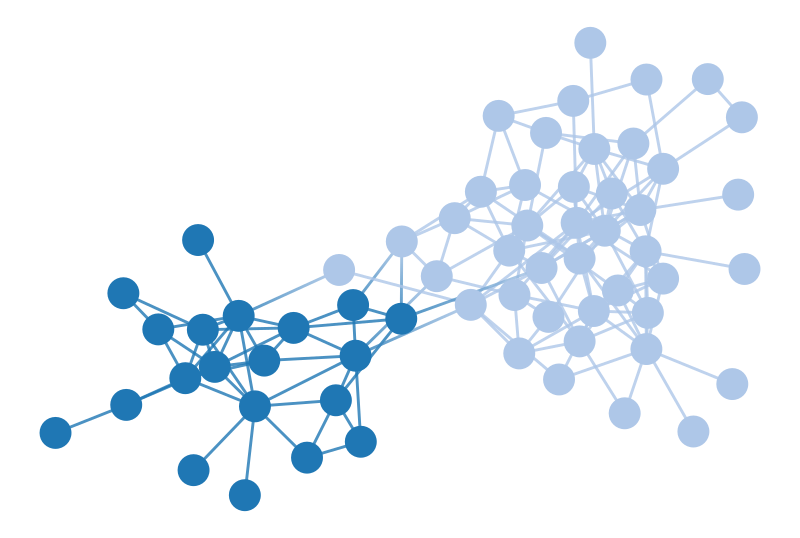

---


College football (games network)  |  gt.collection.data['football']  |  B by level = [10, 2, 1, 1, 1, 1, 1, 1]
  vertices: 115 edges: 613
  chosen level: 1


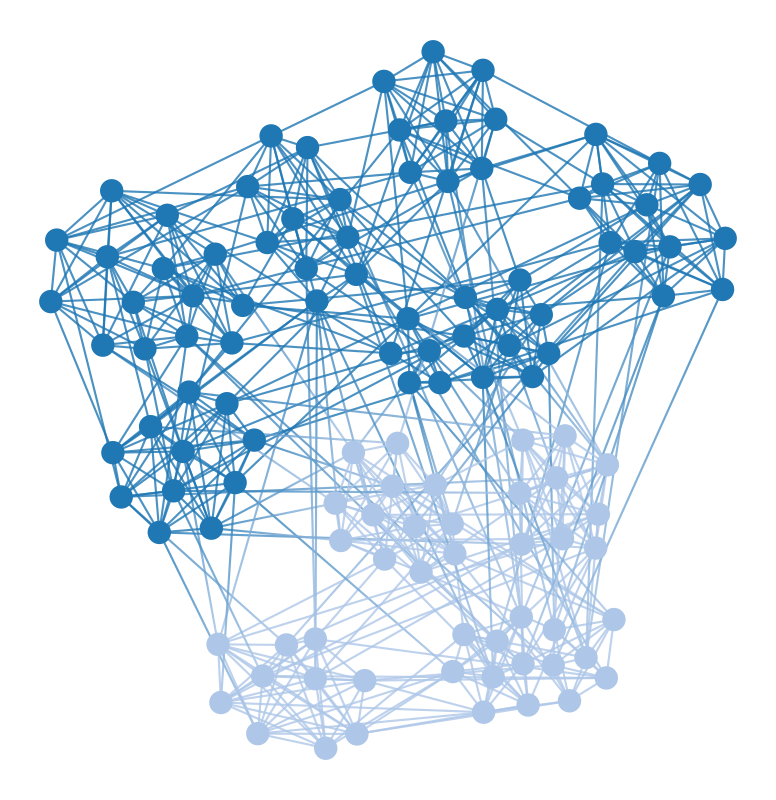

---


Political books (co-purchase network)  |  gt.collection.data['polbooks']  |  B by level = [3, 1, 1, 1, 1, 1, 1, 1]
  vertices: 105 edges: 441
  chosen level: 0


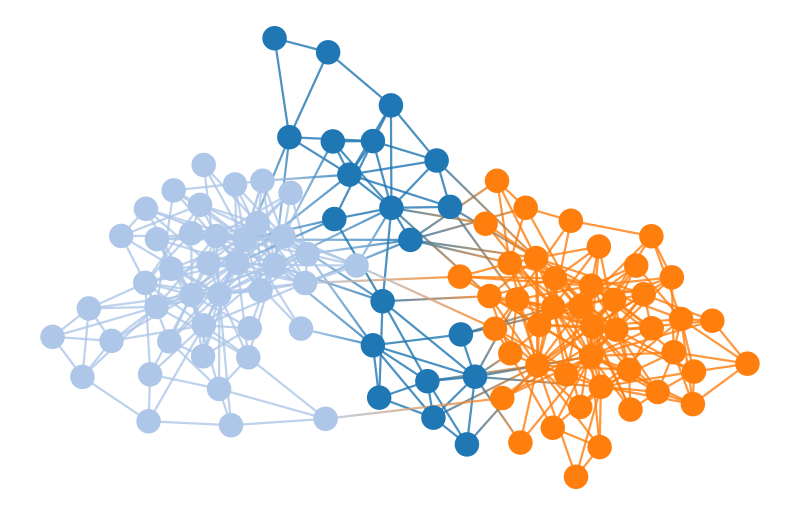

---


Worm brain  |  gt.collection.data['celegansneural']  |  B by level = [24, 4, 1, 1, 1, 1, 1, 1, 1, 1]
  vertices: 297 edges: 2148
  chosen level: 1


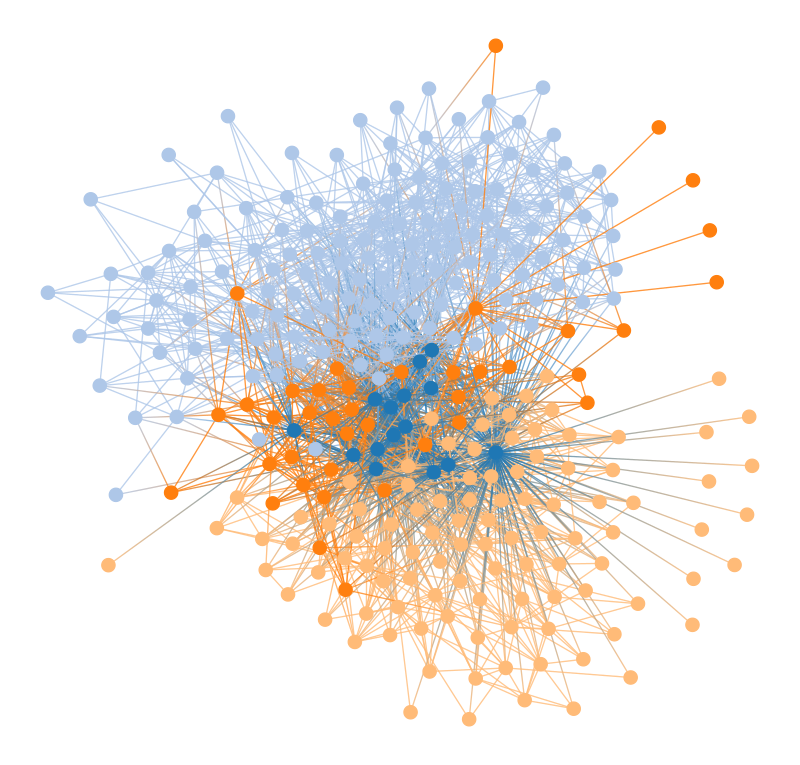

---


Power grid  |  gt.collection.data['power']  |  B by level = [16, 5, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
  vertices: 4941 edges: 6594
  chosen level: 2


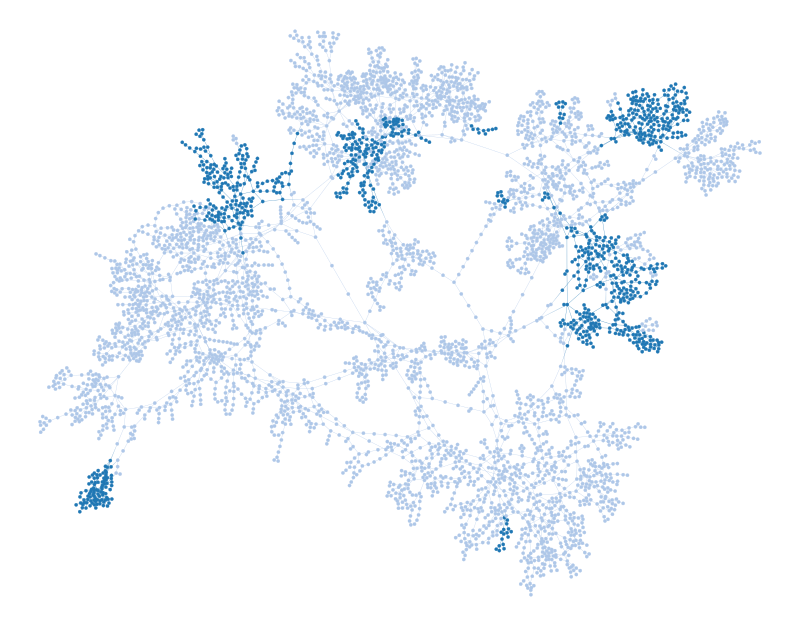

---


Food web  |  gt.collection.data['serengeti-foodweb']  |  B by level = [4, 2, 1, 1, 1, 1, 1, 1, 1]
  vertices: 161 edges: 591
  chosen level: 1


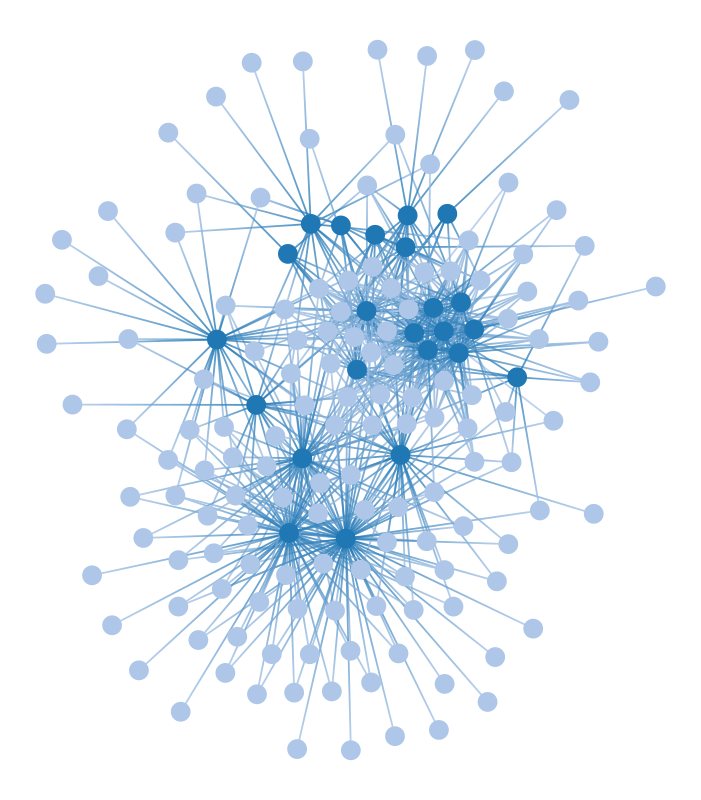

---


Les Misérables (character co-appearance)  |  NetworkX: les_miserables_graph()  |  B by level = [7, 2, 1, 1, 1, 1, 1, 1]
  vertices: 77 edges: 254
  chosen level: 1


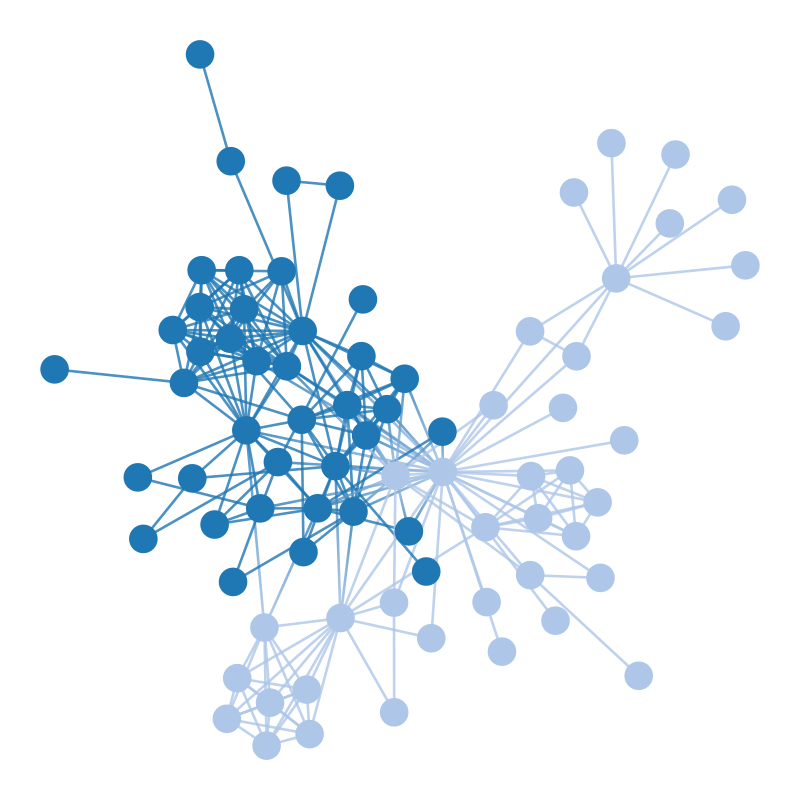

---


Florentine families (marriage/business ties)  |  NetworkX: florentine_families_graph()  |  B by level = [1, 1, 1, 1, 1]
  vertices: 15 edges: 20
  chosen level: 0


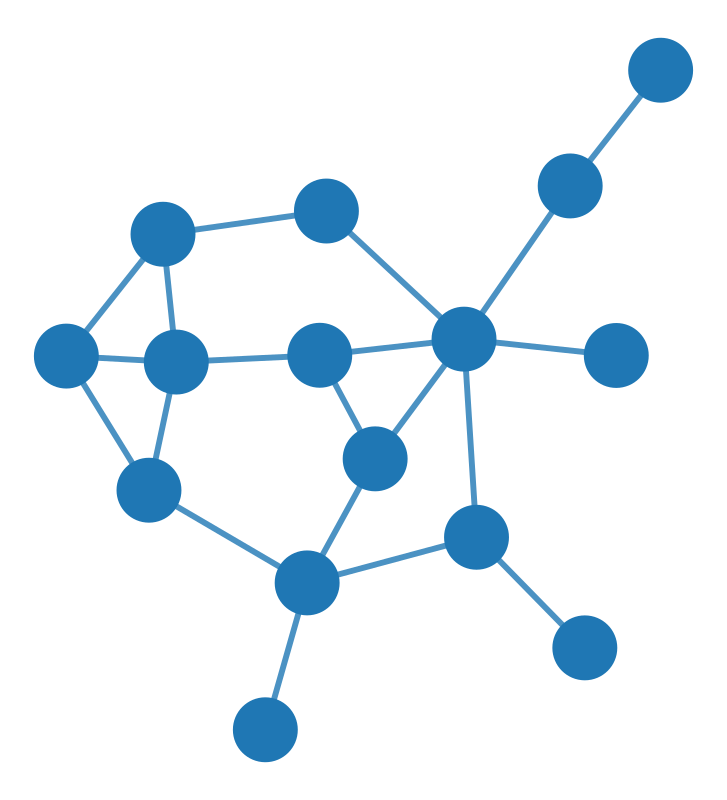

---


In [129]:
# Pick a small gallery. Add/remove items as you like.
gallery = [
    ("karate", "Karate Club (classic social network)"), 
    ("dolphins", "Dolphins (animal social network)"), 
    ("football", "College football (games network)"), 
    ("polbooks", "Political books (co-purchase network)"),
    ("celegansneural", "Worm brain"),
    ("power", "Power grid"),
    ("serengeti-foodweb",'Food web'),
    # ('as-22july06', 'Autonomous systems'),   # 23k nodes: about 7 minutes on 2 CPUs
    
    # Offline fallbacks (no download required if NetworkX has them)
    ("lesmis_nx", "Les Misérables (character co-appearance)"), 
    ("florentine_nx", "Florentine families (marriage/business ties)"), 
]

# niter=10: make 10 sweeps of proposed moves at each stage of the search, not the default 1.
# Slower, but less likely to settle on a poor partition. (Do not add beta=1.0 here: that would
# sample instead of minimize and take many minutes per network.)
mcmc_args = dict(niter=10)

for name, label in gallery:
    try:
        g0, src = load_dataset(name)
    except Exception as e:
        print(f"Skipping {name}: {e}")
        print("---")
        continue

    g = clean_undirected_simple(g0)

    state, level, Bs = fit_nested_sbm_and_choose_level(g, B_min=2, B_max=20,
                                                       deg_corr=True, mcmc_args=mcmc_args)

    title = f"{label}  |  {src}  |  B by level = {Bs}"
    draw_state(state, g, title=title, level=level)
    print("---")


**Reading the gallery.** "B by level" lists the number of groups at each level of the hierarchy, finest first; the trailing 1s are padding (13.8). Each picture shows the coarsest level that has between 2 and 20 groups, or level 0 if there is none. In the run saved here, Karate Club (34 nodes) and the Florentine families (15 nodes) come back with one group at every level. That is an answer, not a failure: in a network that small, the model does not find enough evidence to pay for a split. For Karate, 14.5 showed the posterior is divided between one group and a few. Louvain still returns several communities for Karate (Section 2.4).

### Wrapping up

A good mental checklist when you run community detection:

1. **Start with a null model.** Ask what structure you would see "by chance," given what must be preserved (size, degrees, etc.).
2. **Be explicit about assumptions.** Modularity, Infomap, and SBMs answer different questions because they assume different generating stories.
3. **Model selection is part of the problem.** If you must choose the number of communities by hand, you are doing model selection "off to the side."
4. **Uncertainty matters.** A single partition is rarely the full story; look at marginals, stability, and posterior predictive behavior.

__________
## Next time...
Project update presentations (Mon, Oct 19): present from your chapter notebook. Then our next notebook, Visualization — Python! `class_11_visualization.ipynb` (Wed, Oct 21).
_______

## 17. References and further resources

1. Class Webpages
    - Jupyter Book: https://computational-methods-network-science.github.io/nets7052_fa26/README.html
    - Github: https://github.com/computational-methods-network-science/nets7052_fa26/
    - Syllabus and course details: https://brennanklein.com/nets7052-fall26
2. The official `graph-tool` documentation. https://graph-tool.skewed.de/
3. Netzschleuder: the dataset repository used by `graph-tool` (via `gt.collection.ns[...]`). https://networks.skewed.de/
4. Girvan, M. & Newman, M. E. J. (2002). *Community structure in social and biological networks*. **PNAS**, 99(12), 7821-7826. DOI: 10.1073/pnas.122653799
5. Newman, M. E. J. & Girvan, M. (2004). *Finding and evaluating community structure in networks*. **Physical Review E**, 69, 026113. DOI: 10.1103/PhysRevE.69.026113
6. Newman, M. E. J. (2006). *Modularity and community structure in networks*. **PNAS**, 103(23), 8577-8582. DOI: 10.1073/pnas.0601602103
7. Blondel, V. D., Guillaume, J.-L., Lambiotte, R., & Lefebvre, E. (2008). *Fast unfolding of communities in large networks* (Louvain). **J. Stat. Mech.**, P10008. DOI: 10.1088/1742-5468/2008/10/P10008
8. Traag, V. A., Waltman, L., & van Eck, N. J. (2019). *From Louvain to Leiden: guaranteeing well-connected communities*. **Scientific Reports**, 9, 5233. DOI: 10.1038/s41598-019-41695-z
9. Rosvall, M. & Bergstrom, C. T. (2008). *Maps of random walks on complex networks reveal community structure* (Infomap / map equation). **PNAS**, 105(4), 1118-1123. DOI: 10.1073/pnas.0706851105
10. Fortunato, S. (2010). *Community detection in graphs*. **Physics Reports**, 486(3-5), 75-174. DOI: 10.1016/j.physrep.2009.11.002
11. Abbe, E. (2018). *Community Detection and Stochastic Block Models: Recent Developments*. **JMLR**, 18(177), 1-86. (Often circulated as a free PDF; search the title.)
12. Fortunato, S. & Barthélemy, M. (2007). *Resolution limit in community detection*. **PNAS**, 104(1), 36-41. DOI: 10.1073/pnas.0605965104
13. Good, B. H., de Montjoye, Y.-A., & Clauset, A. (2010). *Performance of modularity maximization in practical contexts*. **Physical Review E**, 81, 046106. DOI: 10.1103/PhysRevE.81.046106
14. Holland, P. W., Laskey, K. B., & Leinhardt, S. (1983). *Stochastic blockmodels: First steps*. **Social Networks**, 5(2), 109-137. DOI: 10.1016/0378-8733(83)90021-7
15. Karrer, B. & Newman, M. E. J. (2011). *Stochastic blockmodels and community structure in networks* (degree correction). **Physical Review E**, 83, 016107. DOI: 10.1103/PhysRevE.83.016107
16. Peixoto, T. P. (2014). *Hierarchical block structures and high-resolution model selection in large networks*. **Physical Review X**, 4, 011047. DOI: 10.1103/PhysRevX.4.011047
17. Peixoto, T. P. (2014). *Efficient Monte Carlo and greedy heuristic for the inference of stochastic block models*. **Physical Review E**, 89, 012804. DOI: 10.1103/PhysRevE.89.012804
18. Peixoto, T. P. (2017). *Nonparametric Bayesian inference of the microcanonical stochastic block model*. **Physical Review E**, 95, 012317. DOI: 10.1103/PhysRevE.95.012317
19. Funke, T. & Becker, T. (2019). *Stochastic block models: A comparison of variants and inference methods*. **PLOS ONE**, 14(4): e0215296. DOI: 10.1371/journal.pone.0215296
20. Kass, R. E. & Raftery, A. E. (1995). *Bayes factors*. **Journal of the American Statistical Association**, 90(430), 773-795. DOI: 10.1080/01621459.1995.10476572
21. Rissanen, J. (1978). *Modeling by shortest data description*. **Automatica**, 14(5), 465-471. DOI: 10.1016/0005-1098(78)90005-5
22. MacKay, D. J. C. (2003). *Information Theory, Inference, and Learning Algorithms*. Cambridge University Press. ISBN-13: 978-0521642989
23. Gelman, A., et al. (various editions). *Bayesian Data Analysis* (excellent for building intuition around posteriors)

## Appendix A: NetworkX ↔ `graph-tool` cheat sheet

This appendix is meant to be something you can **keep open while coding**.

> In `graph-tool`, the "secret" is: **structure in the Graph, data in property maps**.

---

### A.1 Create a graph

**NetworkX**
```python
G = nx.Graph()
G = nx.DiGraph()
```

**graph-tool**
```python
g = gt.Graph(directed=False)
g = gt.Graph(directed=True)
```

---


### A.2 Add edges

**NetworkX**
```python
G.add_edge("a", "b")
G.add_edges_from([("a","b"), ("b","c")])
```

**graph-tool**
```python
g.add_edge(0, 1)   # vertices 0 and 1 are created if they don't exist yet
g.add_edge_list([(0,1), (1,2)])
```

If your node IDs are strings:
```python
v_id = g.add_edge_list(edge_list, hashed=True, hash_type="string")
g.vp["id"] = v_id
```

---


### A.3 Node/edge attributes

**NetworkX**
```python
G.nodes["a"]["age"] = 20
G.edges["a","b"]["w"] = 0.7
```

**graph-tool**
```python
age = g.new_vp("int")
w   = g.new_ep("double")

age[v] = 20
w[e]   = 0.7

g.vp["age"] = age
g.ep["w"]   = w
```

---


### A.4 Subgraphs

**NetworkX**
```python
H = G.subgraph(nodes_to_keep).copy()
```

**graph-tool**
```python
vfilt = g.new_vp("bool")
vfilt.a = ...  # boolean mask of length N
gv = gt.GraphView(g, vfilt=vfilt)
H = gt.Graph(gv, prune=True)  # optional: make a real copy
```

---


### A.5 Degrees

**NetworkX**
```python
deg = dict(G.degree())
```

**graph-tool**
```python
deg = g.degree_property_map("total").a  # numpy array
```

---


### A.6 Clustering

**NetworkX**
```python
nx.transitivity(G)          # 3 x triangles / connected triples
nx.average_clustering(G)    # a different number: the average of the local C_i
```

**graph-tool**
```python
gt.global_clustering(g)           # transitivity; returns (value, std)
gt.local_clustering(g).a.mean()   # the average of the local C_i
```

---

### A.7 Shortest paths

**NetworkX**
```python
nx.shortest_path_length(G, source, target)
```

**graph-tool**
```python
gt.shortest_distance(g, source=v, target=u)
```

Weighted:
```python
gt.shortest_distance(g, source=v, weights=g.ep.weight)
```

---


### A.8 Community detection

- NetworkX comm detection often ends at: partition that maximizes modularity
- graph-tool comm detection often starts at: generative model → infer partition + uncertainty

**NetworkX (Louvain)**
```python
from networkx.algorithms.community import louvain_communities
parts = louvain_communities(G, seed=0)
```

**graph-tool (SBM inference)**
```python
state = gt.minimize_nested_blockmodel_dl(g, state_args=dict(deg_corr=True))
state.draw()
```

---

### A.9 Saving/loading

**NetworkX**
```python
nx.write_graphml(G, "g.graphml")
G = nx.read_graphml("g.graphml")
```

**graph-tool**
```python
g.save("g.gt")
g = gt.load_graph("g.gt")
```


## Appendix B: `graph-tool` datasets and Netzschleuder

`graph-tool` ships with a small built-in collection (`gt.collection.data`) and can also download many more graphs from **Netzschleuder** (`gt.collection.ns`). This is super convenient.

Why this matters for learning:
- You can grab real graphs in 1 line
- You can reproduce experiments easily

![](images/netzschleuder.png)

---

### B.1 Built-in datasets (`gt.collection.data`)

These typically work offline once installed.

Example:
```python
g = gt.collection.data["polbooks"]
```


### B.2 Netzschleuder datasets (`gt.collection.ns`)

Netzschleuder access requires internet the first time; graphs are cached locally afterward.

Example:
```python
g = gt.collection.ns["ego_social/facebook_combined"]  # example dataset
```


### B.3 Hands-on: list dataset keys and load an example


In [130]:
print("Some built-in datasets:", list(gt.collection.data.keys())[:20])

# This prints a dictionary-like structure with available collections.
print("\nNetzschleuder example keys (may take a moment):")
print(list(gt.collection.ns.keys())[:10])

Some built-in datasets: ['adjnoun', 'as-22july06', 'astro-ph', 'celegansneural', 'cond-mat', 'cond-mat-2003', 'cond-mat-2005', 'dolphins', 'email-Enron', 'football', 'hep-th', 'karate', 'lesmis', 'netscience', 'pgp-strong-2009', 'polblogs', 'polbooks', 'power', 'serengeti-foodweb']

Netzschleuder example keys (may take a moment):


['7th_graders', 'academia_edu', 'add_health/comm1', 'add_health/comm2', 'add_health/comm3', 'add_health/comm4', 'add_health/comm5', 'add_health/comm6', 'add_health/comm7', 'add_health/comm8']


Loaded facebook_combined: 4039 V, 88234 E
Vertex properties: ['_pos']


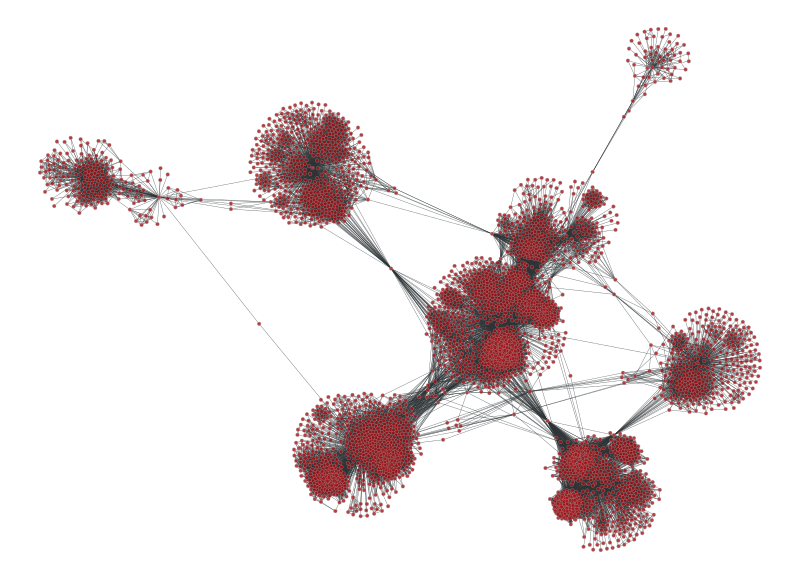

In [131]:
# Example: Facebook combined ego network (requires internet for first download)
g_fb = gt.collection.ns["ego_social/facebook_combined"]
print("Loaded facebook_combined:", g_fb.num_vertices(), "V,", g_fb.num_edges(), "E")
print("Vertex properties:", list(g_fb.vp.keys())[:10])

# positions are sometimes stored as an internal property map
pos = g_fb.vp["_pos"] if "_pos" in g_fb.vp else gt.sfdp_layout(g_fb)
gt.graph_draw(g_fb, pos=pos, output_size=(400, 400));

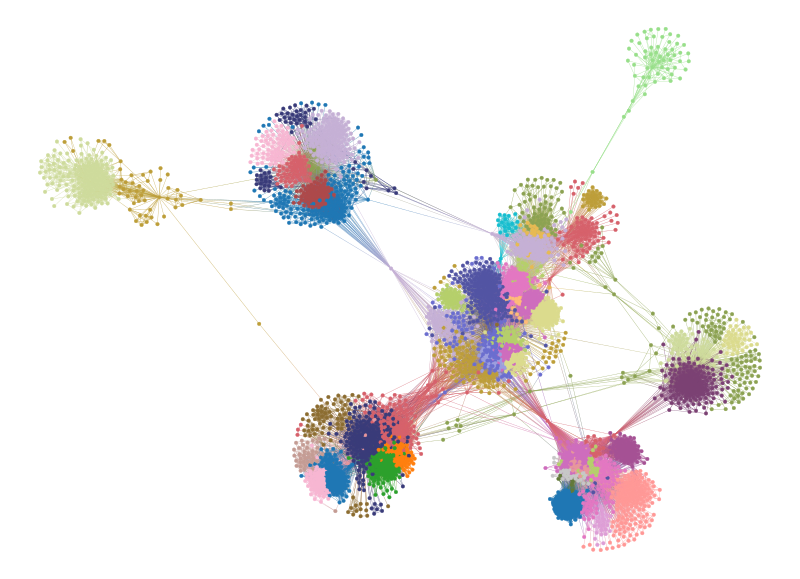

In [132]:
# quick SBM inference (warning: can be computationally heavy)
st = gt.minimize_blockmodel_dl(g_fb, state_args=dict(deg_corr=True))
st.draw(pos=pos, output_size=(400, 400));

## Appendix C: Weighted graphs in `graph-tool`

Edge "weights" can mean different things:
- **cost** or **distance** (shortest paths)
- **tie strength** (stronger relationship)
- **frequency** (number of interactions)
- **capacity** (flow)

In `graph-tool`, weights are usually stored in an **edge property map** (e.g., `double`).

---

### C.1 Weighted shortest paths

If you have `g.ep["weight"]`, you can do:

```python
dist = gt.shortest_distance(g, source=v, weights=g.ep.weight)
```

This treats weights as *edge lengths/costs*.  
If your weights are "strength", you might want to invert them (cost = 1/strength).

---

### C.2 Weighted SBMs (edge covariates)

SBM inference can incorporate weights as **edge covariates** using `state=gt.WeightedBlockState` and:
- `rec=[...]` (list of edge property maps)
- `rec_types=[...]` (list of distributional assumptions)

Common `rec_types` include:
- `"real-normal"` (continuous real weights)
- `"real-exponential"`
- `"discrete-poisson"` (counts)
- `"discrete-binomial"`, `"discrete-geometric"`

This is *not* the same as "weighted adjacency" — it models:
1) whether an edge exists
2) the weight of the edge, given it exists

---

### C.3 Hands-on: weighted distances and a weighted SBM on a tiny example

In [133]:
# Reuse the earlier pandas edge list
df_edges

,src,dst,weight
0,alice,bob,1.0
1,alice,carlos,0.2
2,bob,carlos,0.8
3,carlos,dana,2.0
4,carlos,alice,0.5
5,dana,bob,1.3


In [134]:
# NetworkX: weighted shortest path
G_w = nx.from_pandas_edgelist(df_edges, "src", "dst", edge_attr="weight", create_using=nx.MultiGraph)
# MultiGraph keeps both alice–carlos rows (0.2 and 0.5), like graph-tool does. A plain nx.Graph keeps
# only the last one (0.5), and the distance below would come out 2.3 instead of 2.2.

print("NetworkX weighted distance alice→dana:",
      nx.shortest_path_length(G_w, "alice", "dana", weight="weight"))

NetworkX weighted distance alice→dana: 2.2


In [135]:
# Build the same weighted graph in graph-tool
edge_list = list(df_edges.itertuples(index=False, name=None))
g = gt.Graph(directed=False)
w = g.new_ep("double")
v_id = g.add_edge_list(edge_list, hashed=True, hash_type="string", eprops=[w])

g.vp["id"] = v_id
g.ep["weight"] = w

In [136]:
# Find vertex handles by ID
v_by_id = {g.vp.id[v]: v for v in g.vertices()}

v_src = v_by_id["alice"]
v_dst = v_by_id["dana"]

dist = gt.shortest_distance(g, source=v_src, weights=g.ep.weight)
print("graph-tool weighted distance alice→dana:", dist[v_dst])

graph-tool weighted distance alice→dana: 2.2


Weighted SBM DL: 12.62 B = 1


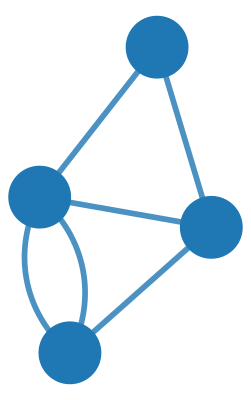

In [137]:
# Weighted SBM inference (toy example)
state_w = gt.minimize_blockmodel_dl(
    g,
    state=gt.WeightedBlockState,
    state_args=dict(
        deg_corr=True,
        rec=[g.ep.weight],
        rec_types=["real-normal"]
    )
)
print("Weighted SBM DL:", round(state_w.entropy(), 2), "B =", state_w.get_B())
state_w.draw(output_size=(200, 200));

## Appendix D: Practical tips, performance, and common gotchas

### D.1 OpenMP threads (parallel algorithms)

Many `graph-tool` algorithms use OpenMP parallelism.

You can inspect and set threads:

```python
import graph_tool.all as gt
import graph_tool

print(graph_tool.openmp_enabled())
print(graph_tool.openmp_get_num_threads())
graph_tool.openmp_set_num_threads(8)
```

You can also use a context manager:
```python
with graph_tool.openmp_context(nthreads=8):
    # run expensive algorithms here
    ...
```

---

### D.2 Multigraph by default

Parallel edges and self-loops are allowed unless you remove them:
```python
gt.remove_parallel_edges(g)
gt.remove_self_loops(g)
```

This matters for:
- clustering coefficient
- simple-graph assumptions
- some visualizations

---

### D.3 Property map types

If you create a property map with the wrong type, you'll get confusing errors.

Example:
```python
p = g.new_vp("int")
p[v] = "alice"   # error / nonsense
```

When in doubt:
- store labels as `"string"`
- store numeric quantities as `"double"`
- store masks as `"bool"`

---


### D.4 Label switching in MCMC

Block labels are arbitrary. Partition A and partition B might be the *same* partition up to relabeling.

This is why we used:
- `PartitionModeState` for marginals

---



### D.5 If you get stuck

1. Print what you have:
```python
print(g)
print(list(g.vp.keys()))
print(list(g.ep.keys()))
```

2. Start with smaller graphs (Karate, PolBooks), then scale up.

3. Use the cookbook demos in the official docs!!!

In [138]:
import graph_tool
print("OpenMP enabled:", graph_tool.openmp_enabled())
print("Current threads:", graph_tool.openmp_get_num_threads())
# To change it (do not ask for more threads than your session has cores):
# graph_tool.openmp_set_num_threads(2)

OpenMP enabled: True
Current threads: 2


_________
## Appendix E: Modularity, `ModularityState`

In Classes 7 and 8, we saw modularity and its limitations.  
Here we show how to compute modularity in `graph-tool`, and connect it to statistical inference.

---


### E.1 Generalized modularity (equation)

Given a partition $b$, generalized modularity is:

$$Q = \frac{1}{2m}\sum_{ij}\left(A_{ij} - \gamma\frac{k_i k_j}{2m}\right)\delta(b_i,b_j),$$

where:
- $m$ is the number of edges
- $k_i$ is the degree of node $i$
- $\gamma$ is a **resolution parameter**
- $\delta(b_i,b_j)=1$ if $i$ and $j$ are in the same community

Interpretation:
- compares within-community edge density to a configuration-model null baseline
- $\gamma$ tunes the "preferred" community size (resolution limit issues are real)

---


### E.2 `graph-tool` has modularity maximization — but it's explicitly labeled dangerous

`graph-tool` can do modularity optimization via `ModularityState`.

But its own documentation warns that modularity lacks statistical regularization and tends to overfit.  We include it here so you can compare it to SBM inference and understand the difference.

---

### E.3 Hands-on: maximize modularity on an ER graph (overfitting demo)

We generate an Erdős-Rényi graph and maximize modularity.
Even though the graph has no planted communities, modularity typically finds a partition with non-trivial $Q$.


In [139]:
# Generate an Erdos-Renyi graph in NetworkX for convenience, then convert.
N = 250
p = 0.03
G_er = nx.erdos_renyi_graph(N, p, seed=1)
g_er = nx_to_gt(G_er)

# Modularity maximization via ModularityState
# (same search routine as before; with state=gt.ModularityState it maximizes modularity instead
#  of minimizing description length)
mod_state = gt.minimize_blockmodel_dl(g_er, state=gt.ModularityState)

# Partition labels live here
b_mod = mod_state.b

# Number of inferred communities (nonempty)
B_mod = len(np.unique(b_mod.a))

Q = gt.modularity(g_er, b_mod, gamma=1.0)

print("ER graph (N={}, p={}):".format(N, p))
print("  inferred B (modularity) :", B_mod)
print("  modularity Q            :", round(float(Q), 4))

# Compare to SBM inference (degree-corrected)
sbm_state = gt.minimize_blockmodel_dl(g_er, state_args=dict(deg_corr=True))
print("\nSBM inference on the same ER graph:")
print("  inferred B (SBM)        :", sbm_state.get_B())
print("  description length Σ    :", round(float(sbm_state.entropy()), 3), "(nats)")

ER graph (N=250, p=0.03):
  inferred B (modularity) : 8
  modularity Q            : 0.3348

SBM inference on the same ER graph:
  inferred B (SBM)        : 1
  description length Σ    : 4502.917 (nats)


This graph is pure noise: every pair of nodes is linked with the same probability 0.03. Modularity maximization still returns around ten communities with $Q$ around 0.33, a value often reported as evidence of community structure. The SBM returns one group, which is the truth.

## Appendix F: Overlapping communities with `OverlapBlockState`

Many real networks have **overlapping** community structure:

- people belong to multiple social circles
- papers span multiple topics
- genes participate in multiple pathways

A standard SBM assumes a *single* block label per node.   `graph-tool` supports overlapping SBMs via `OverlapBlockState`.

The main idea is that instead of a single block label $b_i$, a node can have multiple memberships. This is quite intuitive! One way to think about this is: each "half-edge" of a node may belong to a different block, so a node can connect to multiple groups in different interaction contexts.

---
A sensible workflow:

1. Fit a standard (non-overlapping) SBM
2. Fit an overlapping SBM
3. Compare description lengths
4. If the overlap model is favored, interpret carefully (uncertainty is even more important)

Below we show the minimal code on Karate Club.

Non-overlap Σ: 222.89 nats | B: 1
Overlap    Σ: 216.042 nats | B: 1
ΔΣ (overlap - base): -6.848


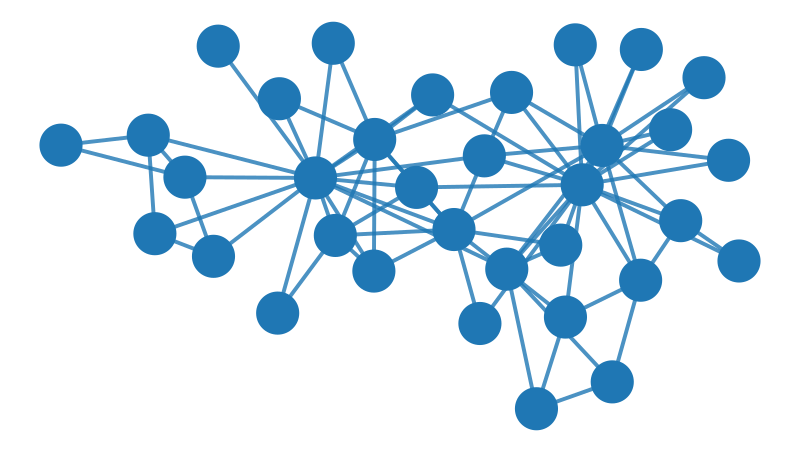

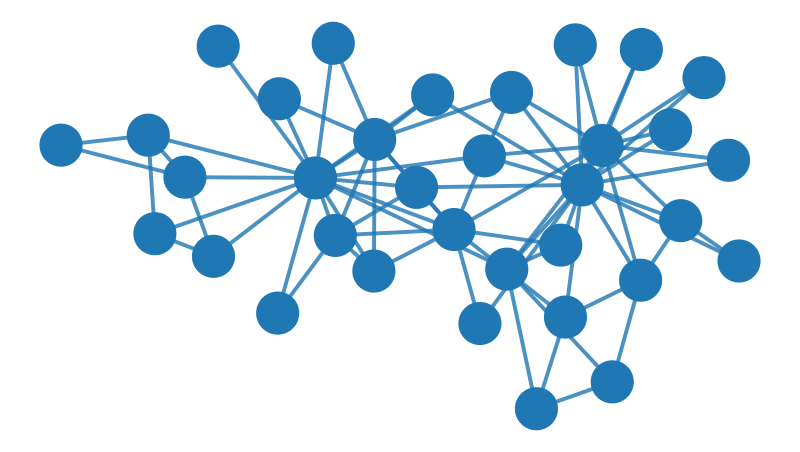

In [140]:
g = nx_to_gt(nx.karate_club_graph())

base = gt.minimize_blockmodel_dl(g, state_args=dict(deg_corr=True))
ov   = gt.minimize_blockmodel_dl(g, state=gt.OverlapBlockState,
                                 state_args=dict(deg_corr=True))

print("Non-overlap Σ:", round(base.entropy(), 3), "nats | B:", base.get_B())
print("Overlap    Σ:", round(ov.entropy(),   3), "nats | B:", ov.get_B())
print("ΔΣ (overlap - base):", round(ov.entropy() - base.entropy(), 3))

pos = gt.sfdp_layout(g)
base.draw(pos=pos, output_size=(400,400))
ov.draw(pos=pos, output_size=(400,400));

Both fits return $B = 1$ here, so there is nothing overlapping: with one group the two states describe the same model, and their likelihood terms are identical (`entropy(dl=False)` gives 139.20 nats for both). The 6.85-nat gap comes only from the two classes using different priors for the partition and the degrees. Read a negative $\Delta\Sigma$ as support for overlapping groups only when the overlapping fit uses more than one group.

## Appendix G: Multilayer (multiplex) networks with `LayeredBlockState`

Many real-world network science problems involve multiple edge types. For example...
- friendship vs advice ties
- retweets vs replies
- co-authorship vs citation
- positive vs negative interactions

A naive approach aggregates everything into one graph, which can erase structure. `graph-tool` supports **layered SBMs** where each edge belongs to a *layer*.

### G.1 Representing layers

We store a layer label on each edge:

- `ec[e] = 0` for layer 0
- `ec[e] = 1` for layer 1
- ...

The graph can be a multigraph so the same node pair can have multiple edges across layers.

### G.2 Synthetic example: two layers, same nodes, different mixing

We build a toy multiplex graph with two layers and then fit a layered SBM:

```python
state = gt.minimize_blockmodel_dl(g,
                                 state=gt.LayeredBlockState,
                                 state_args=dict(ec=ec, independent=True, deg_corr=True))
```

We compare it to the "edge covariates" version of the same model (`independent=False`). Both versions use one partition of the nodes for all layers, and both let the number of edges between two groups differ from layer to layer. They differ in how the layers are generated. Edge covariates: one SBM generates the merged graph (all layers together), so each node has one degree, and each edge then gets a layer label that depends only on the two groups it joins. Independent layers: each layer is generated by its own SBM, so with `deg_corr=True` each node gets a separate degree in every layer.

In [141]:
rng = np.random.default_rng(5)
gt.seed_rng(5)

# Make a planted partition graph
N = 200
B = 4
sizes = [50, 50, 50, 50]
b_true = np.concatenate([np.full(s, r, dtype=int) for r, s in enumerate(sizes)])


# Two layers that share the same underlying blocks, but with meaningfully different block matrices.
# Layer 0: standard assortative structure (communities)
p0_in, p0_out = 0.18, 0.006

p1_in = 0.06
p1_out_low = 0.004
p1_out_high = 0.05  # higher probability for (0,1) and (2,3)


p0 = p0_in * np.eye(B) + p0_out * (np.ones((B, B)) - np.eye(B))

p1 = p1_out_low * np.ones((B, B))
np.fill_diagonal(p1, p1_in)
p1[0, 1] = p1[1, 0] = p1_out_high
p1[2, 3] = p1[3, 2] = p1_out_high

In [142]:
# Build a multigraph where parallel edges represent different layers.
g = gt.Graph(directed=False)
g.add_vertex(N)

ec = g.new_ep("int")      # layer label per edge
g.ep["layer"] = ec

for i in range(N):
    for j in range(i + 1, N):
        bi, bj = int(b_true[i]), int(b_true[j])

        if rng.random() < p0[bi, bj]:
            e = g.add_edge(i, j)
            ec[e] = 0

        if rng.random() < p1[bi, bj]:
            e = g.add_edge(i, j)
            ec[e] = 1

m0 = sum(1 for e in g.edges() if ec[e] == 0)
m1 = sum(1 for e in g.edges() if ec[e] == 1)
print("Total edges:", g.num_edges(), "| layer0:", m0, "| layer1:", m1)

Total edges: 1628 | layer0: 994 | layer1: 634


In [143]:
# Fit layered SBM.... independent=True uses the “independent layers” model.
layered = gt.minimize_blockmodel_dl(
    g,
    state=gt.LayeredBlockState,
    state_args=dict(ec=ec, independent=True, deg_corr=True),
    multilevel_mcmc_args=dict(niter=20)   # try 5 (fast), 20 (strong), 50 (very strong)
)

In [144]:
# Same layer labels, same shared partition; one SBM for the merged graph, then a layer label
# per edge ("edge covariates")
covariates = gt.minimize_blockmodel_dl(
    g,
    state=gt.LayeredBlockState,
    state_args=dict(ec=ec, independent=False, deg_corr=True),
    multilevel_mcmc_args=dict(niter=20)
)

In [145]:
print("Layered Σ        :", round(float(layered.entropy()), 3), "nats | B:", layered.get_B())
print("Covariates Σ     :", round(float(covariates.entropy()), 3), "nats | B:", covariates.get_B())
print("Per-edge Σ (layered)      :", round(float(layered.entropy())/g.num_edges(), 4))
print("Per-edge Σ (covariates)  :", round(float(covariates.entropy())/g.num_edges(), 4))

Layered Σ        : 6067.096 nats | B: 4
Covariates Σ     : 6030.312 nats | B: 4
Per-edge Σ (layered)      : 3.7267
Per-edge Σ (covariates)  : 3.7041


In [146]:
# Visualize each layer with nodes colored by the *layered* inferred blocks
b_layered = layered.get_blocks()
pos = gt.sfdp_layout(gt.GraphView(g, directed=False))

ef0 = g.new_ep("bool")
ef1 = g.new_ep("bool")
for e in g.edges():
    ef0[e] = (ec[e] == 0)
    ef1[e] = (ec[e] == 1)

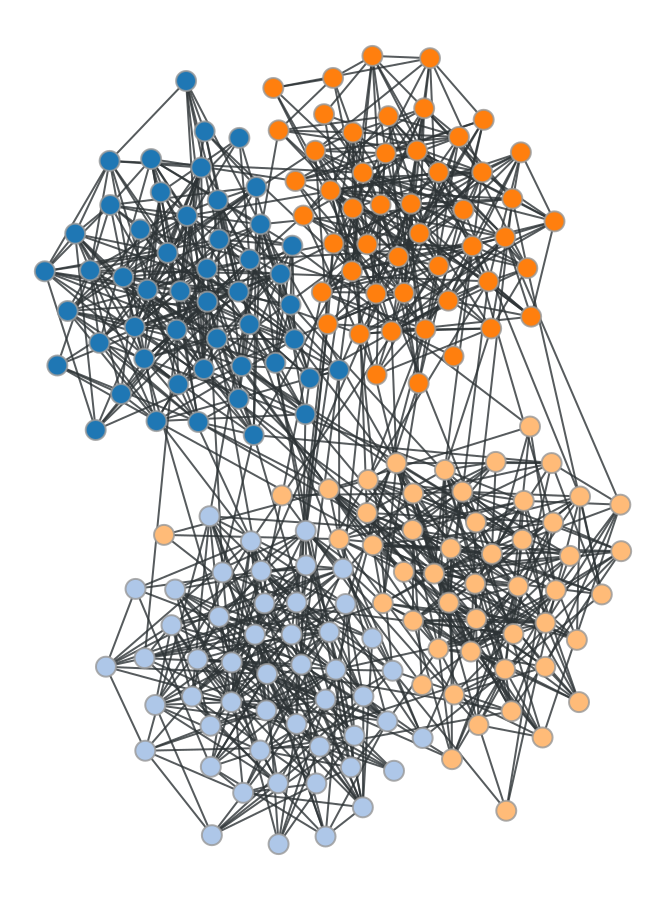

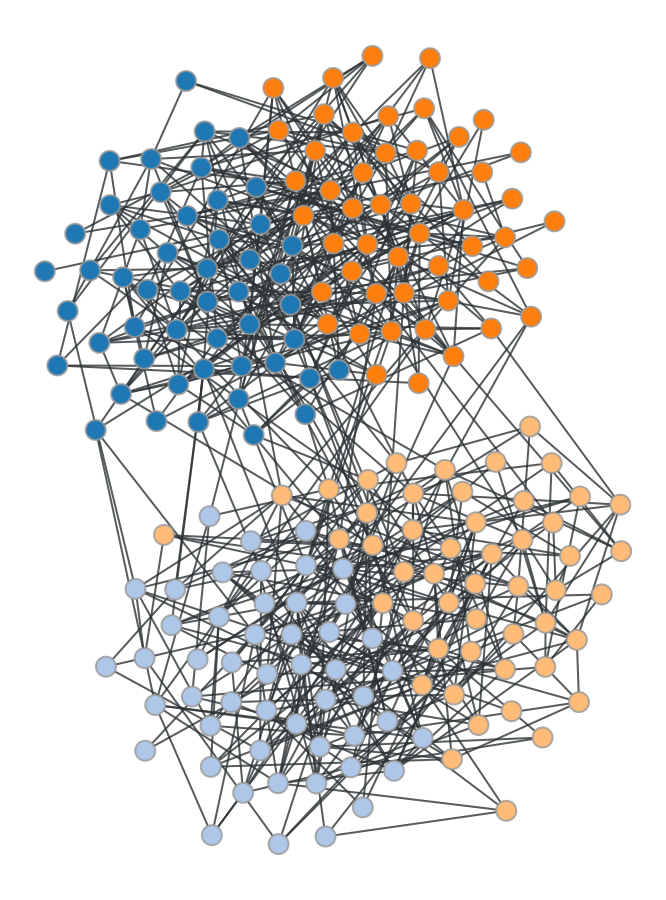

In [147]:
g0 = gt.GraphView(g, efilt=ef0)
g1 = gt.GraphView(g, efilt=ef1)

gt.graph_draw(g0, pos=pos, vertex_fill_color=b_layered,
              vertex_size=10, output_size=(450, 450))
gt.graph_draw(g1, pos=pos, vertex_fill_color=b_layered,
              vertex_size=10, output_size=(450, 450));

The multilayer example above is mainly about modeling choices and how to interpret them. We created a network with a fixed set of vertices and two edge layers, encoded as a multigraph with an edge property `ec` that labels the layer of each edge. We then compared two inference choices:

1. A layered SBM (`LayeredBlockState`), which allows the *layer label* to matter in the generative story, and
2. The edge-covariates version of the same model (`independent=False`), which generates the merged graph with one SBM and then gives each edge a layer label that depends only on the two groups it joins. (A plain `BlockState` that ignores the labels is not a fair comparison: its description length never pays to encode which layer each edge is in, so it always comes out shorter.)

It is completely normal for both models to infer the same number of blocks $B$ and to produce visually similar partitions. The question the two description lengths answer is narrower than "do layers matter?". Both models encode the layer labels, and both allow a different block-to-block pattern in each layer. What the independent-layers version adds (with `deg_corr=True`) is a separate degree for every node in every layer. Those extra parameters cost description length, so it wins only when nodes' degrees differ across layers by more than their groups explain. In this synthetic graph a node's expected degree in each layer is set by its group alone, so the edge-covariates version should have the shorter description length, and it does.

In practice, the decision rule is simple: treat layers as part of the model only when they change the story in a way that improves out-of-sample reasoning or materially reduces MDL relative to the appropriate baseline. If the two versions yield similar partitions and MDL prefers the simpler model, that is a useful conclusion rather than a failure: the data are telling you that layer distinctions are not carrying enough additional structure to justify extra parameters.

## Appendix H: Link prediction with SBMs

A very common network science task:

> Given a partially observed network, can we predict missing links?

SBMs are generative models, so they naturally support link prediction.

### H.1 Scoring edges

Let $G$ be your observed graph, and consider adding a candidate edge $(u,v)$. A simple score is a log-likelihood ratio:

$$\mathrm{score}(u,v) = \log\frac{P(G + (u,v)\mid \text{model})}{P(G\mid \text{model})}.$$

In `graph-tool`, `state.modify_edge_dS(u, v, 1)` (the 1 means: add one edge) returns the change in description length $\Delta\Sigma$ from adding the edge $(u,v)$ with the partition held fixed, so $-\Delta\Sigma$ is that log-ratio, and we can use it as a ranking score.

1. Remove a set of true edges (holdout set)
2. Fit the SBM on the remaining edges
3. Score:
   - held-out true edges ("positives")
   - randomly chosen non-edges ("negatives")
4. Compute an AUC-like statistic:
   - probability a random positive gets a higher score than a random negative

AUC stands for area under the curve, a standard score for rankings. You only need the reading given here: 0.5 is guessing and 1.0 is perfect.

This is not the only evaluation method, but it's a good start.

In [148]:
rng = np.random.default_rng(2)
gt.seed_rng(2)

# --- Data: Karate Club ---
g_full = nx_to_gt(nx.karate_club_graph())
g_full = gt.Graph(g_full)
g_full.set_directed(False)

In [149]:
# --- Hold out a subset of true edges ---
edges = [(int(e.source()), int(e.target())) for e in g_full.edges()]
rng.shuffle(edges)
n_test = 15
test_edges = edges[:n_test]

In [150]:
# --- Training graph = full graph minus test edges ---
g_train = gt.Graph(g_full)
for (u, v) in test_edges:
    e = g_train.edge(u, v)
    if e is not None:
        g_train.remove_edge(e)

print("Train edges:", g_train.num_edges(), "| Test edges:", len(test_edges))

Train edges: 63 | Test edges: 15


In [151]:
# --- Fit an SBM on the training graph ---
state = gt.minimize_blockmodel_dl(g_train, state_args=dict(deg_corr=True))
print("Inferred B (MAP state):", state.get_B())
# B = 1 again (see 14.4). With one group, the model predicts links from degree alone: two
# well-connected nodes are more likely to be linked.

Inferred B (MAP state): 1


In [152]:
# --- Sample random non-edges (negatives) ---
neg_edges = []
N = g_train.num_vertices()
while len(neg_edges) < len(test_edges):
    u = int(rng.integers(0, N))
    v = int(rng.integers(0, N))
    if u == v:
        continue
    # a non-edge of the FULL graph, so held-out true edges can't sneak in as negatives
    if g_full.edge(u, v) is None and (u, v) not in neg_edges and (v, u) not in neg_edges:
        neg_edges.append((u, v))

In [153]:
# --- Helper: numerically stable log-mean-exp ---
# Each score is the log of a probability ratio. We want to average the ratios themselves across
# samples, not their logs: exponentiate, average, take the log again. Subtracting the largest
# value first keeps exp() from overflowing.
def logmeanexp(a):
    a = np.asarray(a, dtype=float)
    m = np.max(a)
    return m + np.log(np.mean(np.exp(a - m)))

In [154]:
# --- MCMC model averaging of per-edge scores ---
# -modify_edge_dS(u, v, 1) is the log-likelihood ratio for adding edge (u, v), partition held fixed.
# We average the likelihood ratio exp(-ΔΣ) over posterior samples of b, then take the log
# (that is what logmeanexp does).
burnin = 2000
thin = 10
n_samples = 500
beta = 1.0

for _ in range(burnin):
    state.mcmc_sweep(beta=beta)

In [155]:
pos_hist = [[] for _ in test_edges]
neg_hist = [[] for _ in neg_edges]

for _ in range(n_samples):
    for _ in range(thin):
        state.mcmc_sweep(beta=beta)

    # IMPORTANT: pass integer pairs (u,v)
    # partition_dl=False: leave the cost of the partition out of ΔΣ (it does not change when an edge is added)
    for i, (u, v) in enumerate(test_edges):
        pos_hist[i].append(-state.modify_edge_dS(u, v, 1, entropy_args=dict(partition_dl=False)))
    for i, (u, v) in enumerate(neg_edges):
        neg_hist[i].append(-state.modify_edge_dS(u, v, 1, entropy_args=dict(partition_dl=False)))

pos_scores = np.array([logmeanexp(h) for h in pos_hist])
neg_scores = np.array([logmeanexp(h) for h in neg_hist])

In [156]:
# AUC-like statistic: P(score(pos) > score(neg)) with ties = 0.5
wins = 0.0
for s in pos_scores:
    wins += np.sum(s > neg_scores) + 0.5 * np.sum(s == neg_scores)
auc = wins / (len(pos_scores) * len(neg_scores))

print("Mean positive score:", round(float(pos_scores.mean()), 3))
print("Mean negative score:", round(float(neg_scores.mean()), 3))
print("AUC (higher is better):", round(float(auc), 3))

Mean positive score: -1.659
Mean negative score: -2.954
AUC (higher is better): 0.747


Read the AUC as a probability: it is the chance that a held-out true edge outscores a random non-edge, and 0.5 would be guessing. With only 15 edges of each kind, this number is rough and will move from run to run.

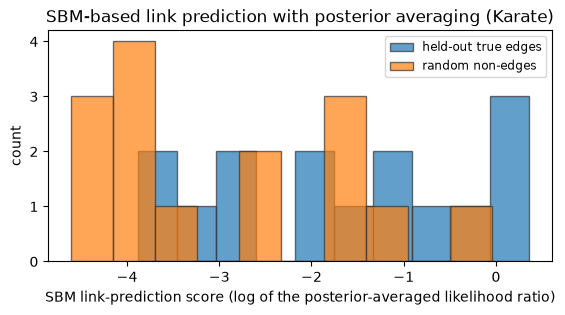

In [157]:
# Visualize score distributions
plt.figure(figsize=(6.5, 3.0), dpi=100)

plt.hist(pos_scores, bins=10, alpha=0.7, label="held-out true edges", ec='.2')
plt.hist(neg_scores, bins=10, alpha=0.7, label="random non-edges", ec='.2')
plt.xlabel("SBM link-prediction score (log of the posterior-averaged likelihood ratio)")
plt.ylabel("count")
plt.title("SBM-based link prediction with posterior averaging (Karate)")
plt.legend(fontsize='small')

plt.show()

## Appendix I: Network dynamics in `graph-tool` — SIS epidemics + spectral thresholds

`graph-tool` includes a `dynamics` module for simulating standard processes on networks. This is extremely useful in applied network science!

We'll focus on the SIS (susceptible-infectious-susceptible) model.

### I.1 SIS model (equations)

Each node is either:
- susceptible: $s_i(t)=0$
- infectious: $s_i(t)=1$

A node $i$ becomes infected based on its infectious neighbors. In `graph-tool`'s SIS model, when node $i$ is updated at time $t$:

- If $s_i(t)=0$, it becomes infected with probability

$$(1-r_i)\left[1-\prod_j(1-\beta_{ij})^{A_{ij}\delta_{s_j(t),1}}\right] + r_i$$

- If $s_i(t)=1$, it recovers with probability $\gamma_i$.

Here:
- $\beta_{ij}$ is the transmission probability along edge $i\leftarrow j$
- $\gamma_i$ is the recovery probability
- $r_i$ is spontaneous infection probability (we'll set $r=0$)

### I.2 Epidemic threshold

A common approximation (quenched mean-field) says an epidemic can persist if:

$$\frac{\beta}{\gamma} \gtrsim \frac{1}{\lambda_{\max}},$$

where $\lambda_{\max}$ is the largest eigenvalue of the adjacency matrix.

We'll compute $\lambda_{\max}$ and simulate SIS above and below this threshold.

$1/\lambda_{\max}$ is a lower bound on the threshold of the actual random process, and on a finite network every run eventually reaches the state with no infectious nodes, which it cannot leave when $r=0$. Close to the threshold on a 34-node graph that happens fast, so we compare well below ($0.6\,\beta_c$) with well above ($5\,\beta_c$), and we start with every node infectious.

In [158]:
from graph_tool.dynamics import SISState

g = nx_to_gt(nx.karate_club_graph())
g = gt.GraphView(g, directed=False)

In [159]:
# Largest eigenvalue of adjacency matrix (sparse)
A = gt.adjacency(g)
lam_max = float(np.real(spla.eigs(A, k=1, which="LR", return_eigenvectors=False)[0]))
print("lambda_max (adjacency):", round(lam_max, 3))

lambda_max (adjacency): 6.726


In [160]:
gamma = 0.2
beta_c = gamma / lam_max
print("Approx threshold beta_c ≈ gamma / lambda_max =", round(beta_c, 4))

Approx threshold beta_c ≈ gamma / lambda_max = 0.0297


In [161]:
# Simulate well below and well above the threshold
betas = [0.6 * beta_c, 5.0 * beta_c]
T = 200

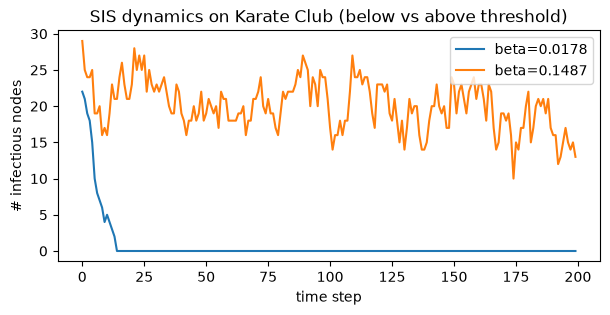

In [162]:
plt.figure(figsize=(7, 3.0), dpi=100)
for beta in betas:
    s0 = g.new_vp("int32_t", val=1)   # start with every node infectious
    state = SISState(g, beta=float(beta), gamma=float(gamma), r=0.0, s=s0)
    X = []
    for _ in range(T):
        state.iterate_sync()  # one synchronous sweep
        # number infectious nodes
        X.append(state.get_state().fa.sum())
    plt.plot(X, label=f"beta={beta:.4f}")

plt.xlabel("time step")
plt.ylabel("# infectious nodes")
plt.title("SIS dynamics on Karate Club (below vs above threshold)")
plt.legend()

plt.show()

## Appendix J: Other fun graph algorithms with `graph-tool`

Beyond inference, `graph-tool` is an extremely fast graph-algorithms library.

### J.1 k-core decomposition

The k-core is the maximal subgraph where every node has degree ≥ k (within that subgraph).
The **core number** of a node is the largest k for which it belongs to the k-core.

Use cases:
- identify "network core" vs periphery
- robustness / percolation intuition
- preprocessing for visualization and inference

---

In [163]:
g = nx_to_gt(nx.karate_club_graph())
g = gt.GraphView(g, directed=False)

# --- k-core decomposition ---
core = gt.kcore_decomposition(g)
print("Core numbers (min, max):", int(core.a.min()), ",", int(core.a.max()))

Core numbers (min, max): 1 , 4


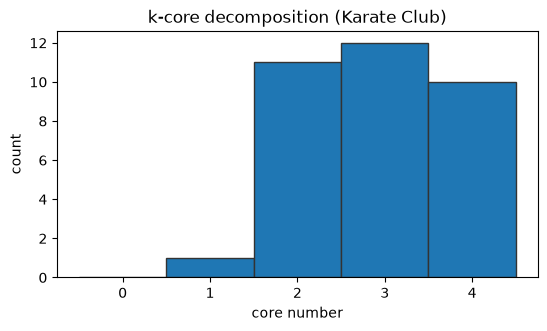

In [164]:
plt.figure(figsize=(6.2, 3.2), dpi=100)

plt.hist(core.a, bins=np.arange(core.a.max() + 2) - 0.5, density=False, ec='.2')
plt.xlabel("core number")
plt.ylabel("count")
plt.title("k-core decomposition (Karate Club)")

plt.show()

In [165]:
# Extract the 3-core (as an example)
k = 3
vfilt = g.new_vp("bool")
vfilt.a = core.a >= k
g_kcore = gt.GraphView(g, vfilt=vfilt)

print(f"{k}-core vertices:", g_kcore.num_vertices(), "| edges:", g_kcore.num_edges())

3-core vertices: 22 | edges: 55


### J.2 Minimum spanning tree (MST)

For weighted connected graphs, the MST is a cycle-free subset of edges connecting all vertices with minimum total weight. Use cases:
- extracting a "backbone" structure
- simplifying dense weighted networks

---


In [166]:
# --- Minimum spanning tree (needs weights) ---
w = g.new_ep("double")
rng = np.random.default_rng(0)
for e in g.edges():
    w[e] = float(rng.random())

tree = gt.min_spanning_tree(g, weights=w)  # boolean EdgePropertyMap
g_mst = gt.GraphView(g, efilt=tree)
print("MST edges:", g_mst.num_edges())

MST edges: 33


### J.3 Maximum cardinality matching

A matching is a set of edges with no shared vertices. Maximum matching finds the largest such set. Use cases:
- assignment problems
- bipartite matching
- structural controllability intuition

---

In [167]:
# --- Maximum cardinality matching (Karate Club) ---
g = nx_to_gt(nx.karate_club_graph())
g = gt.Graph(g)
g.set_directed(False)

mate = gt.max_cardinality_matching(g)  # vertex property map
N = g.num_vertices()

In [168]:
# Convert mate[] into a boolean edge filter
ef = g.new_ep("bool", val=False)

for e in g.edges():
    s = e.source()
    t = e.target()

    ms = int(mate[s])  # mate index for s (or sentinel if unmatched)
    if 0 <= ms < N and ms == int(t):
        ef[e] = True

In [169]:
g_match = gt.GraphView(g, efilt=ef)
print("Matching size (#edges):", g_match.num_edges())

Matching size (#edges): 13


_______
### J.4 Quick connectivity checks

- largest connected component
- bipartite test
- DAG test (directed acyclicity)

In [170]:
# --- Quick checks ---
print("Is bipartite?", gt.is_bipartite(g))
print("Largest component size:", gt.label_largest_component(g).a.sum())

Is bipartite? False
Largest component size: 34


## Appendix K: Centrality (PageRank, betweenness, closeness, eigenvector) in `graph-tool`

Community structure is one "macro" lens. Centrality is a complementary micro lens. `graph-tool` implements many standard centrality measures efficiently in C++.

---


### K.1 Quick definitions (from Class 4!)

#### Degree
For an undirected graph, degree is:

$$
k_i = \sum_j A_{ij}.
$$

It's fast and often surprisingly informative, but it's local.


#### Betweenness
Betweenness counts how often a node lies on shortest paths:

$$
C_B(v) = \sum_{s\ne v\ne t} \frac{\sigma_{st}(v)}{\sigma_{st}},
$$

where $\sigma_{st}$ is the number of shortest paths from $s$ to $t$, and $\sigma_{st}(v)$ is the number of those paths that pass through $v$.

Interpretation: high betweenness nodes can act as "bridges" / bottlenecks.

(Section 9.4 wrote this same quantity as $\mathrm{BC}(v)$. The code below uses `norm=True`, which divides by the number of pairs, as explained there.)

#### Closeness
Closeness centrality (connected graphs):

$$
C_C(v) = \frac{N-1}{\sum_{u\ne v} d(v,u)}.
$$

For disconnected graphs, a more stable variant is *harmonic closeness*:

$$
C_H(v) = \sum_{u\ne v} \frac{1}{d(v,u)},
$$

with the convention $1/\infty = 0$.

With `norm=True`, as in the code below, `graph-tool` divides the harmonic sum by $N-1$ (for node 0 of the Karate Club, $23.17/33 = 0.702$).

#### Eigenvector centrality
Eigenvector centrality is the eigenvector of $A$ that belongs to its largest eigenvalue $\lambda_{\max}$:

$$
A\,\mathbf{x} = \lambda_{\max}\,\mathbf{x}.
$$

For a connected graph it is the only eigenvector whose entries all have the same sign, which is what lets us read them as scores. `graph-tool` scales it so that $\sum_i x_i^2 = 1$.

aka nodes are important if they connect to other important nodes (and so on and so on).

#### PageRank
PageRank is a damped random-walk centrality:

$$
\mathbf{x} = \alpha\,P^T\mathbf{x} + (1-\alpha)\,\frac{1}{N}\mathbf{1},
$$

where $P_{ij} = A_{ij}/k_i$ is the probability that a random walker at $i$ steps to $j$, and $\alpha$ is the damping factor (often 0.85).

---

### K.2 `graph-tool` API shape: property maps

Centralities are returned as `VertexPropertyMaps`.

- The property map itself behaves like a mapping from vertices to values.
- The underlying NumPy array is usually available as `.a`.

Below we compute centralities on Karate in both `graph-tool` and `networkx` and compare.

In [171]:
g = nx_to_gt(nx.karate_club_graph())
G_nx = gt_to_nx(g)

# --- graph-tool centralities ---
pr_gt = gt.pagerank(g, damping=0.85)                 # VertexPropertyMap
vb_gt, eb_gt = gt.betweenness(g, norm=True)          # (vertex vp, edge ep)
cl_gt = gt.closeness(g, norm=True)                   # VertexPropertyMap
ch_gt = gt.closeness(g, harmonic=True, norm=True)    # harmonic closeness
eigval, ev_gt = gt.eigenvector(g)                    # (largest eigenvalue, VertexPropertyMap)

print("Node 0: harmonic closeness =", round(float(ch_gt.a[0]), 4),
      "| eigenvector centrality =", round(float(ev_gt.a[0]), 4),
      "| largest eigenvalue =", round(float(eigval), 4))

Node 0: harmonic closeness = 0.702 | eigenvector centrality = 0.3555 | largest eigenvalue = 6.7257


In [172]:
# --- networkx centralities ---
pr_nx = nx.pagerank(G_nx, alpha=0.85, weight=None)  # unweighted, like graph-tool's call above (networkx would otherwise use karate's edge weights)
vb_nx = nx.betweenness_centrality(G_nx, normalized=True)
cl_nx = nx.closeness_centrality(G_nx)

# align to a consistent node order
nodes = list(G_nx.nodes())
pr_nx_vec = np.array([pr_nx[v] for v in nodes])
vb_nx_vec = np.array([vb_nx[v] for v in nodes])
cl_nx_vec = np.array([cl_nx[v] for v in nodes])

In [173]:
# graph-tool vectors
pr_gt_vec = pr_gt.a
vb_gt_vec = vb_gt.a
cl_gt_vec = cl_gt.a

In [174]:
def spearman(x, y):
    # tiny Spearman rank correlation (no scipy.stats dependency)
    rx = pd.Series(x).rank().to_numpy()
    ry = pd.Series(y).rank().to_numpy()
    return np.corrcoef(rx, ry)[0, 1]

In [175]:
print("Spearman corr (PageRank):   ", round(spearman(pr_gt_vec, pr_nx_vec), 3))
print("Spearman corr (Betweenness):", round(spearman(vb_gt_vec, vb_nx_vec), 3))
print("Spearman corr (Closeness):  ", round(spearman(cl_gt_vec, cl_nx_vec), 3))

Spearman corr (PageRank):    1.0
Spearman corr (Betweenness): 1.0
Spearman corr (Closeness):   1.0


In [176]:
# show top nodes by PageRank + betweenness (graph-tool)
top_pr = np.argsort(-pr_gt_vec)[:5]
top_vb = np.argsort(-vb_gt_vec)[:5]


In [177]:
print("\nTop-5 PageRank nodes (graph-tool):")
for i in top_pr:
    print(f"  node {i:>2}  PR={pr_gt_vec[i]:.4f}")


Top-5 PageRank nodes (graph-tool):
  node 33  PR=0.1009
  node  0  PR=0.0970
  node 32  PR=0.0717
  node  2  PR=0.0571
  node  1  PR=0.0529


In [178]:
print("\nTop-5 betweenness nodes (graph-tool):")
for i in top_vb:
    print(f"  node {i:>2}  betw={vb_gt_vec[i]:.4f}")



Top-5 betweenness nodes (graph-tool):
  node  0  betw=0.4376
  node 33  betw=0.3041
  node 32  betw=0.1452
  node  2  betw=0.1437
  node 31  betw=0.1383


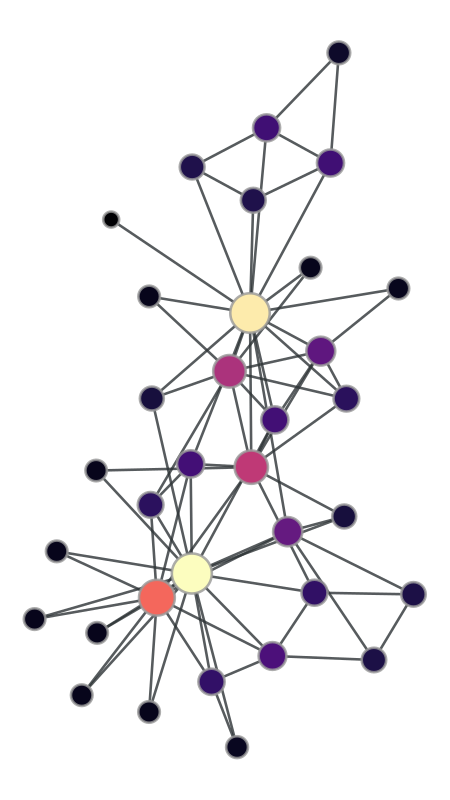

In [179]:
# simple visualization: size nodes by PageRank
pos = gt.sfdp_layout(g)
gt.graph_draw(
    g, pos=pos,
    vertex_size=gt.prop_to_size(pr_gt, mi=8, ma=20),
    vertex_fill_color=pr_gt,
    output_size=(400,400)
);

## Appendix L: Motifs and motif significance

Motifs are small subgraph patterns (triads, tetrads, ...) that can be:
- descriptive ("this network has lots of feed-forward loops")
- inferential ("is this motif over-represented compared to a null model?")

Also `graph-tool` sneakily has terrific motif abilities.

---

### L.1 Counting motifs

`graph-tool` can count connected node-induced subgraphs of size $k$ via:

```python
motifs, counts = gt.motifs(g, k)
```

The returned `motifs` are themselves tiny graphs (one per motif type), and `counts[i]` tells you how often motif `i` occurs as an induced subgraph.

---


### L.2 Motif significance as a z-score

To quantify "over-representation", a common approach is to compare motif counts to a null ensemble (often degree-preserving shuffles).

Let:

- $N_i$ = motif count in the observed graph
- $N_i^{(s)}$ = motif count in shuffle $s$
- $\mu_i = \mathbb{E}[N_i^{(s)}]$
- $\sigma_i = \mathrm{sd}(N_i^{(s)})$

($N_i$ is a count of motifs, not of nodes. $\mu_i$ and $\sigma_i$ are the average and the standard deviation of that count across the shuffled graphs. A common rule of thumb: $|z|$ below about 2 is within the range of chance.)

Then a standard z-score is:

$$
z_i = \frac{N_i - \mu_i}{\sigma_i}.
$$

Large $|z_i|$ means motif $i$ is unusually common (positive) or unusually rare (negative) relative to the chosen null model.

`graph-tool` computes this directly via:

```python
motifs, z = gt.motif_significance(g, k=3, n_shuffles=100, shuffle_model="configuration")
```

--

### L.3 Example: motifs of size 3 on Karate (and their significance)

This is meant as a "how to do it" template — for real motif work, choose $k$ and $n_\text{shuffles}$ carefully (runtime grows quickly with $k$).

In [180]:
g = nx_to_gt(nx.karate_club_graph())

# Count 3-node induced motifs
motifs_3, counts_3 = gt.motifs(g, k=3)
counts_3 = np.asarray(counts_3)

print("Number of distinct 3-node motifs found:", len(motifs_3))
print("Counts:", counts_3)

Number of distinct 3-node motifs found: 2
Counts: [393  45]


In [181]:
# A simple way to summarize motifs without drawing:
# show number of edges in each motif graph
edges_in_motif = np.array([m.num_edges() for m in motifs_3])
summary = pd.DataFrame({
    "motif_id": np.arange(len(motifs_3)),
    "edges_in_motif": edges_in_motif,
    "count": counts_3.astype(int)
}).sort_values(["edges_in_motif", "count"], ascending=[True, False])

summary

,motif_id,edges_in_motif,count
0,0,2,393
1,1,3,45


In [182]:
# Motif significance profile (keep n_shuffles small for classroom runtime)
motifs_sig, zscores = gt.motif_significance(
    g, k=3,
    n_shuffles=30,
    shuffle_model="configuration"
)

In [183]:
zscores = np.asarray(zscores)
edges_sig = np.array([m.num_edges() for m in motifs_sig])

sig = pd.DataFrame({
    "motif_id": np.arange(len(motifs_sig)),
    "edges_in_motif": edges_sig,
    "z": zscores
}).sort_values("z", ascending=False)

sig

,motif_id,edges_in_motif,z
1,1,3,1.09167
0,0,2,-1.09167


The two z-scores are equal and opposite, and they have to be. A degree-preserving shuffle keeps every degree, so it keeps the number of paths of length two, $\sum_i k_i(k_i-1)/2 = 528$. Each triangle contains three of those and each open wedge one, so wedges $+\;3\times$ triangles $= 528$ in the data ($393 + 3\cdot 45$) and in every shuffle. The wedge count is $528 - 3T$, so its z-score is the triangle z-score with the sign flipped. For $k=3$ on an undirected graph this profile carries one number, not two. And that number is small: Karate has a few more triangles than its degrees alone would produce, but not convincingly more. Section 10.4 said the same thing with a p-value of 0.12.

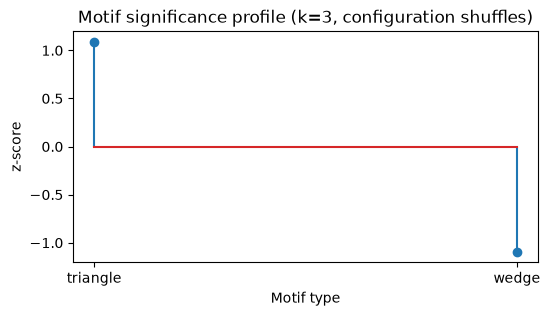

In [184]:
plt.figure(figsize=(6, 3), dpi=100)

plt.stem(sig["z"].values)
plt.xticks(range(len(sig)), ['triangle' if e == 3 else 'wedge' for e in sig['edges_in_motif']])
plt.xlabel("Motif type")
plt.ylabel("z-score")
plt.title("Motif significance profile (k=3, configuration shuffles)")

plt.show()

_________
## Appendix M: Installing `graph-tool` on your own computer

You don't need any of this on the cluster. It's here in case you want to run `graph-tool` on your own machine.

Because `graph-tool` is a compiled C++/Python library, **the safest path is to put it in its own Conda environment** (so you don't accidentally mix binary dependencies from different sources).

---

### M.1 What we're trying to avoid

If you've ever seen errors like:

- `ImportError: ... undefined symbol ...`
- `libstdc++.so.6: version GLIBCXX_... not found`
- `libgomp... version GOMP_... not found`
- `Segmentation fault (core dumped)` *right after an import*

...those are almost always **binary dependency conflicts**.

The fix is boring but reliable:

1. Create a **fresh** environment
2. Install from **conda-forge**
3. Don't "pile" unrelated heavy stacks into the same env unless you really need them

---

### M.2 Recommended installer: Miniforge (Conda + conda-forge)

`graph-tool` is easiest to install from **conda-forge** (binary builds; no compilation).

- macOS (Intel + Apple Silicon): supported
- Linux (x86_64 + ARM): supported
- Windows: **no native build** → use WSL2 (or Docker)

**Install Miniforge** (recommended) or another Conda distribution, then use `mamba` (faster solver).

---

### M.3 "One environment for the course" (macOS / Linux)

In a terminal:

```bash
# 0) (optional but recommended) make sure conda-forge has priority
conda config --add channels conda-forge
conda config --set channel_priority strict

# 1) Create a fresh environment
mamba create -n cmns-graphtool python=3.11

# 2) Install what we need for this course
mamba install -n cmns-graphtool graph-tool networkx numpy pandas scipy matplotlib jupyterlab ipykernel python-igraph leidenalg python-infomap

# 3) Activate
conda activate cmns-graphtool
```

If you don't have `mamba`, you can replace `mamba` with `conda` (it's just slower).


**macOS note (Apple Silicon):** make sure your terminal is running as `arm64`:

```bash
uname -m
```

If it prints `arm64`, you're good. If it prints `x86_64`, you're running an Intel/Rosetta shell (it can work, but you'll be mixing architectures).


---

### M.4 Windows (recommended): WSL2 + Ubuntu + conda-forge

On Windows, the cleanest path is to run `graph-tool` inside **WSL2** (Linux subsystem).

**Step A — install WSL2 (PowerShell as Administrator):**
```powershell
wsl --install
```

Reboot if prompted, then open your Ubuntu terminal.

**Step B — install Miniforge inside WSL2**, then create the same environment as above.

**Step C — how to run notebooks**
You have two good workflows:

1) **VS Code Remote (WSL)**  
   - install VS Code on Windows  
   - install the "Remote - WSL" extension  
   - open the folder from WSL  
   - run Jupyter notebooks using the WSL Python kernel

2) **Run Jupyter in WSL, open it in your Windows browser**
```bash
conda activate cmns-graphtool
jupyter lab --no-browser --ip 0.0.0.0 --port 8888
```
Then open the URL Jupyter prints (usually includes a token) in your Windows browser.

---

### M.5 Register the environment as a Jupyter kernel (recommended)

This makes sure your notebook is running the right Python.

```bash
conda activate cmns-graphtool
python -m ipykernel install --user --name cmns-graphtool --display-name "Python (cmns-graphtool)"
```

Then, in Jupyter: **Kernel → Change Kernel → Python (cmns-graphtool)**.

---

### M.6 Reproducibility checklist (quick sanity test)

From the activated environment:

```bash
python -c "import graph_tool.all as gt; import networkx as nx; import numpy as np; print('graph-tool OK')"
```

If that succeeds, you are ready.

---

### M.7 A fully reproducible `environment.yml` (copy/paste)

You can also create the environment from a file. The course repo has this one at `envs/graphtool/environment.yml`:

```yaml
name: cmns-graphtool
channels:
- conda-forge
dependencies:
- python=3.11
- jupyterlab
- ipykernel
- numpy
- pandas
- scipy
- matplotlib
- networkx
- graph-tool
- python-igraph
- leidenalg
- python-infomap
```

Then run:

```bash
mamba env create -f environment.yml
conda activate cmns-graphtool
```

---

### M.8 Troubleshooting heuristics that actually work

If installs fail or imports crash:

- **Start fresh**: delete the env and recreate it  
  `conda env remove -n cmns-graphtool`
- **Stay on conda-forge** (avoid mixing "defaults" + conda-forge for compiled stacks)
- **Avoid installing PyTorch + graph-tool into the same env** unless you know how to debug OpenMP / `libgomp` issues  
  (make a second env for deep learning)


- **Permission errors on macOS** (e.g., `PermissionError: ... /.condatmp`) often happen when your base Conda install lives in a protected location like `/usr/local/anaconda3`.  
  Two reliable fixes are:
  1) Put Conda's temp + package cache under your home directory:
     ```bash
     mkdir -p ~/.conda/tmp ~/.conda/pkgs ~/.conda/envs
     conda config --add envs_dirs ~/.conda/envs
     conda config --add pkgs_dirs ~/.conda/pkgs
     export TMPDIR="$HOME/.conda/tmp"
     ```
     Then retry the install.
  2) Install Miniforge under your home directory (recommended for a clean slate).

- **macOS Homebrew vs Conda library collisions** can cause warnings like "Class ... implemented in both ...libgio...".  
  If imports work but you see scary warnings (or occasional crashes), prefer the Conda env's libraries:
  ```bash
  mkdir -p "$CONDA_PREFIX/etc/conda/activate.d" "$CONDA_PREFIX/etc/conda/deactivate.d"

  cat > "$CONDA_PREFIX/etc/conda/activate.d/00-dyld-fallback.sh" << 'EOF'
  export _OLD_DYLD_FALLBACK_LIBRARY_PATH="$DYLD_FALLBACK_LIBRARY_PATH"
  export DYLD_FALLBACK_LIBRARY_PATH="$CONDA_PREFIX/lib:${DYLD_FALLBACK_LIBRARY_PATH:-}"
  EOF

  cat > "$CONDA_PREFIX/etc/conda/deactivate.d/00-dyld-fallback.sh" << 'EOF'
  export DYLD_FALLBACK_LIBRARY_PATH="$_OLD_DYLD_FALLBACK_LIBRARY_PATH"
  unset _OLD_DYLD_FALLBACK_LIBRARY_PATH
  EOF

  conda deactivate
  conda activate cmns-graphtool
  ```

- **If your base Conda is very old**, a simple workaround is to make a tiny "boot" environment that contains a modern `mamba`, and use it only to create the course env:
  ```bash
  conda create -n mamba_boot -c conda-forge python=3.11 mamba
  conda activate mamba_boot
  mamba env create -f environment.yml
  ```

If all else fails, the official `graph-tool` Docker image is a reliable fallback.


---

### M.9 Fallback: Docker image (if your local install is blocked)

If you are in an environment where you *cannot* install Conda packages (or you're debugging a gnarly binary issue), the project maintains a Docker image.

At a minimum, you can pull it with:

```bash
docker pull tiagopeixoto/graph-tool
```

From there you can mount your course folder into the container and run Python/Jupyter inside it.
